In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import cv2
from PIL import Image

# Project paths
PROJECT_PATH = Path(r"D:\FINAL DFDT")
DATASET_PATH = PROJECT_PATH / "SELECTED_DATASET"

SPLIT_CSV = DATASET_PATH / "splits" / "dataset_split_manifest.csv"

# Verify paths
print("PROJECT:", PROJECT_PATH.exists())
print("DATASET:", DATASET_PATH.exists())
print("SPLIT CSV:", SPLIT_CSV.exists())

# Load existing split manifest
split_manifest = pd.read_csv(SPLIT_CSV)

print("\nDataset shape:", split_manifest.shape)
print("\nColumns:")
print(split_manifest.columns.tolist())

print("\nSplit distribution:")
print(split_manifest["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(split_manifest["split"], split_manifest["class"]))

print("\nMissing values:")
print(split_manifest.isnull().sum())

# Reconstruct image paths
split_manifest["image_path"] = split_manifest.apply(
    lambda row: str(
        DATASET_PATH /
        row["class"].lower() /
        Path(row["destination_image"]).name
    ),
    axis=1
)

missing_images = sum(
    not Path(path).exists()
    for path in split_manifest["image_path"]
)

print("\nMissing image files:", missing_images)

assert len(split_manifest) == 10000
assert missing_images == 0

print("\nSTEP 30.1 VERIFICATION PASSED")


PROJECT: True
DATASET: True
SPLIT CSV: True

Dataset shape: (10000, 5)

Columns:
['class', 'source_subfolder', 'source_image', 'destination_image', 'split']

Split distribution:
split
train         7000
test          1500
validation    1500
Name: count, dtype: int64

Class distribution:
class       FAKE  REAL
split                 
test         750   750
train       3500  3500
validation   750   750

Missing values:
class                0
source_subfolder     0
source_image         0
destination_image    0
split                0
dtype: int64

Missing image files: 0

STEP 30.1 VERIFICATION PASSED


In [2]:

import numpy as np
import cv2
from pathlib import Path

IMG_SIZE = 160

def extract_degradation_descriptors_160(image_path):

    # Load image as RGB
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize to 160 x 160
    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_LINEAR
    )

    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray_float = gray.astype(np.float32) / 255.0

    # 1. Brightness
    brightness = np.mean(gray_float)

    # 2. Contrast
    contrast = np.std(gray_float)

    # 3. Sharpness
    sharpness = cv2.Laplacian(
        gray_float, cv2.CV_32F
    ).var()

    # 4. Residual energy
    blurred = cv2.GaussianBlur(
        gray_float, (5, 5), 0
    )
    residual = gray_float - blurred
    residual_energy = np.mean(residual ** 2)

    # 5. Absolute residual
    absolute_residual = np.mean(np.abs(residual))

    # 6–8. FFT frequency energy
    fft = np.fft.fftshift(
        np.fft.fft2(gray_float)
    )

    magnitude = np.abs(fft) ** 2

    height, width = gray.shape
    center_y = height // 2
    center_x = width // 2

    y, x = np.ogrid[:height, :width]

    distance = np.sqrt(
        (y - center_y) ** 2 +
        (x - center_x) ** 2
    )

    max_distance = np.sqrt(
        center_y ** 2 + center_x ** 2
    )

    normalized_distance = distance / max_distance

    low_mask = normalized_distance < 0.15

    mid_mask = (
        (normalized_distance >= 0.15) &
        (normalized_distance < 0.50)
    )

    high_mask = normalized_distance >= 0.50

    total_energy = np.sum(magnitude) + 1e-8

    low_frequency_energy = (
        np.sum(magnitude[low_mask]) / total_energy
    )

    mid_frequency_energy = (
        np.sum(magnitude[mid_mask]) / total_energy
    )

    high_frequency_energy = (
        np.sum(magnitude[high_mask]) / total_energy
    )

    return np.array([
        brightness,
        contrast,
        sharpness,
        residual_energy,
        absolute_residual,
        low_frequency_energy,
        mid_frequency_energy,
        high_frequency_energy
    ], dtype=np.float32)


In [3]:

# Select one training image
sample_row = split_manifest[
    split_manifest["split"] == "train"
].iloc[0]

sample_path = sample_row["image_path"]

sample_features = extract_degradation_descriptors_160(
    sample_path
)

print("Image:", sample_path)
print("Descriptor shape:", sample_features.shape)
print("\nDescriptor values:")

descriptor_names = [
    "Brightness",
    "Contrast",
    "Sharpness",
    "Residual Energy",
    "Absolute Residual",
    "FFT Low",
    "FFT Mid",
    "FFT High"
]

for name, value in zip(descriptor_names, sample_features):
    print(f"{name}: {value:.8f}")

assert sample_features.shape == (8,)
assert np.all(np.isfinite(sample_features))

print("\nSTEP 30.3 TEST PASSED")


Image: D:\FINAL DFDT\SELECTED_DATASET\real\000_01_191.png
Descriptor shape: (8,)

Descriptor values:
Brightness: 0.63935280
Contrast: 0.23768118
Sharpness: 0.00552020
Residual Energy: 0.00068783
Absolute Residual: 0.01315756
FFT Low: 0.99331647
FFT Mid: 0.00635029
FFT High: 0.00033305

STEP 30.3 TEST PASSED


In [4]:

import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm

# Output directory
FEATURE_DIR = DATASET_PATH / "degradation_features_160"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_CSV = FEATURE_DIR / "degradation_features_160_raw.csv"

# Descriptor names
descriptor_names = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

# Extract descriptors for all images
all_features = []

for _, row in tqdm(
    split_manifest.iterrows(),
    total=len(split_manifest),
    desc="Extracting 160x160 descriptors"
):
    features = extract_degradation_descriptors_160(
        row["image_path"]
    )

    record = {
        "class": row["class"],
        "source_subfolder": row["source_subfolder"],
        "source_image": row["source_image"],
        "destination_image": row["destination_image"],
        "split": row["split"]
    }

    for name, value in zip(descriptor_names, features):
        record[name] = float(value)

    all_features.append(record)

# Create DataFrame
features_df = pd.DataFrame(all_features)

# Verification
print("Dataset shape:", features_df.shape)
print("\nSplit distribution:")
print(features_df["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(features_df["split"], features_df["class"]))

# Check missing values
print("\nMissing values:", features_df.isnull().sum().sum())

# Check finite descriptor values
descriptor_array = features_df[descriptor_names].to_numpy()

print("NaN values:", np.isnan(descriptor_array).sum())
print("Infinite values:", np.isinf(descriptor_array).sum())

assert len(features_df) == 10000
assert features_df.isnull().sum().sum() == 0
assert np.isfinite(descriptor_array).all()

# Save raw descriptors
features_df.to_csv(OUTPUT_CSV, index=False)

print("\nSaved:", OUTPUT_CSV)
print("\nSTEP 30.4 EXTRACTION PASSED")


Extracting 160x160 descriptors: 100%|██████████| 10000/10000 [00:22<00:00, 438.78it/s]

Dataset shape: (10000, 13)

Split distribution:
split
train         7000
test          1500
validation    1500
Name: count, dtype: int64

Class distribution:
class       FAKE  REAL
split                 
test         750   750
train       3500  3500
validation   750   750

Missing values: 0
NaN values: 0
Infinite values: 0

Saved: D:\FINAL DFDT\SELECTED_DATASET\degradation_features_160\degradation_features_160_raw.csv

STEP 30.4 EXTRACTION PASSED


In [5]:

import json
import numpy as np
import pandas as pd

# Load extracted descriptors
features_df = pd.read_csv(OUTPUT_CSV)

descriptor_names = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

# Separate training data
train_features = features_df.loc[
    features_df["split"] == "train",
    descriptor_names
]

assert len(train_features) == 7000

# Calculate training-only normalization parameters
train_mean = train_features.mean()
train_std = train_features.std(ddof=0)

# Protect against zero standard deviation
train_std = train_std.replace(0, 1.0)

# Normalize all splits using training statistics
normalized_df = features_df.copy()

normalized_df[descriptor_names] = (
    features_df[descriptor_names] - train_mean
) / train_std

# Verify normalized training data
normalized_train = normalized_df.loc[
    normalized_df["split"] == "train",
    descriptor_names
]

print("TRAINING NORMALIZATION VERIFICATION")
print("=" * 65)

print(normalized_train.describe().T.round(4))

# Check finite values
normalized_values = normalized_df[descriptor_names].to_numpy()

assert np.isfinite(normalized_values).all()

# Save normalized descriptors
NORMALIZED_CSV = (
    FEATURE_DIR / "degradation_features_160_normalized.csv"
)

normalized_df.to_csv(NORMALIZED_CSV, index=False)

# Save normalization parameters
normalization_params = {
    "image_size": 160,
    "descriptor_names": descriptor_names,
    "normalization_method": "z-score",
    "standard_deviation_ddof": 0,
    "fitted_on": "train",
    "training_sample_count": int(len(train_features)),
    "mean": train_mean.to_dict(),
    "std": train_std.to_dict()
}

NORMALIZATION_JSON = (
    FEATURE_DIR / "descriptor_normalization_160.json"
)

with open(NORMALIZATION_JSON, "w") as f:
    json.dump(normalization_params, f, indent=4)

print("\nNormalized CSV:", NORMALIZED_CSV)
print("Normalization JSON:", NORMALIZATION_JSON)

print("\nNaN:", np.isnan(normalized_values).sum())
print("Infinite:", np.isinf(normalized_values).sum())

print("\nSTEP 30.5 NORMALIZATION COMPLETED")


TRAINING NORMALIZATION VERIFICATION
                    count  mean     std      min     25%     50%     75%  \
brightness         7000.0  -0.0  1.0001  -2.4425 -0.7079 -0.1119  0.5649   
contrast           7000.0  -0.0  1.0001  -2.5556 -0.7192 -0.0872  0.5858   
sharpness          7000.0  -0.0  1.0001  -0.9728 -0.5777 -0.2741  0.2480   
residual_energy    7000.0   0.0  1.0001  -1.1158 -0.5750 -0.2450  0.2496   
absolute_residual  7000.0   0.0  1.0001  -1.8790 -0.6693 -0.1652  0.4583   
fft_low            7000.0  -0.0  1.0001 -14.1843 -0.3700  0.1779  0.6060   
fft_mid            7000.0   0.0  1.0001  -1.4966 -0.6106 -0.1855  0.3785   
fft_high           7000.0   0.0  1.0001  -0.9060 -0.5038 -0.2104  0.2432   

                       max  
brightness          3.7322  
contrast            3.8584  
sharpness          10.0205  
residual_energy    13.4193  
absolute_residual   8.2492  
fft_low             1.4667  
fft_mid            12.8285  
fft_high           22.0982  

Normalized CSV: D

In [6]:

# Identify the most extreme normalized values
for descriptor in descriptor_names:
    print(f"\n{'=' * 65}")
    print("DESCRIPTOR:", descriptor)

    lowest = normalized_df.nsmallest(3, descriptor)
    highest = normalized_df.nlargest(3, descriptor)

    print("\nLowest 3:")
    print(lowest[
        ["class", "split", "destination_image", descriptor]
    ].to_string(index=False))

    print("\nHighest 3:")
    print(highest[
        ["class", "split", "destination_image", descriptor]
    ].to_string(index=False))

print("\nSTEP 30.6 EXTREME VALUE INSPECTION COMPLETED")



DESCRIPTOR: brightness

Lowest 3:
class split                                       destination_image  brightness
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\344_020_03_406.png   -2.442484
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\344_020_05_528.png   -2.435155
 REAL train     E:\FINAL DATA1\SELECTED_DATASET\real\344_04_203.png   -2.373922

Highest 3:
class split                                       destination_image  brightness
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\533_450_04_359.png    3.732216
 REAL train     E:\FINAL DATA1\SELECTED_DATASET\real\533_01_107.png    3.703335
 FAKE train E:\FINAL DATA1\SELECTED_DATASET\fake\533_450_05_431.png    3.702804

DESCRIPTOR: contrast

Lowest 3:
class      split                                   destination_image  contrast
 REAL validation E:\FINAL DATA1\SELECTED_DATASET\real\581_03_073.png -2.736958
 REAL validation E:\FINAL DATA1\SELECTED_DATASET\real\581_04_061.png -2.714102
 REAL validation E:\FINAL DATA1\SELECTED_DA

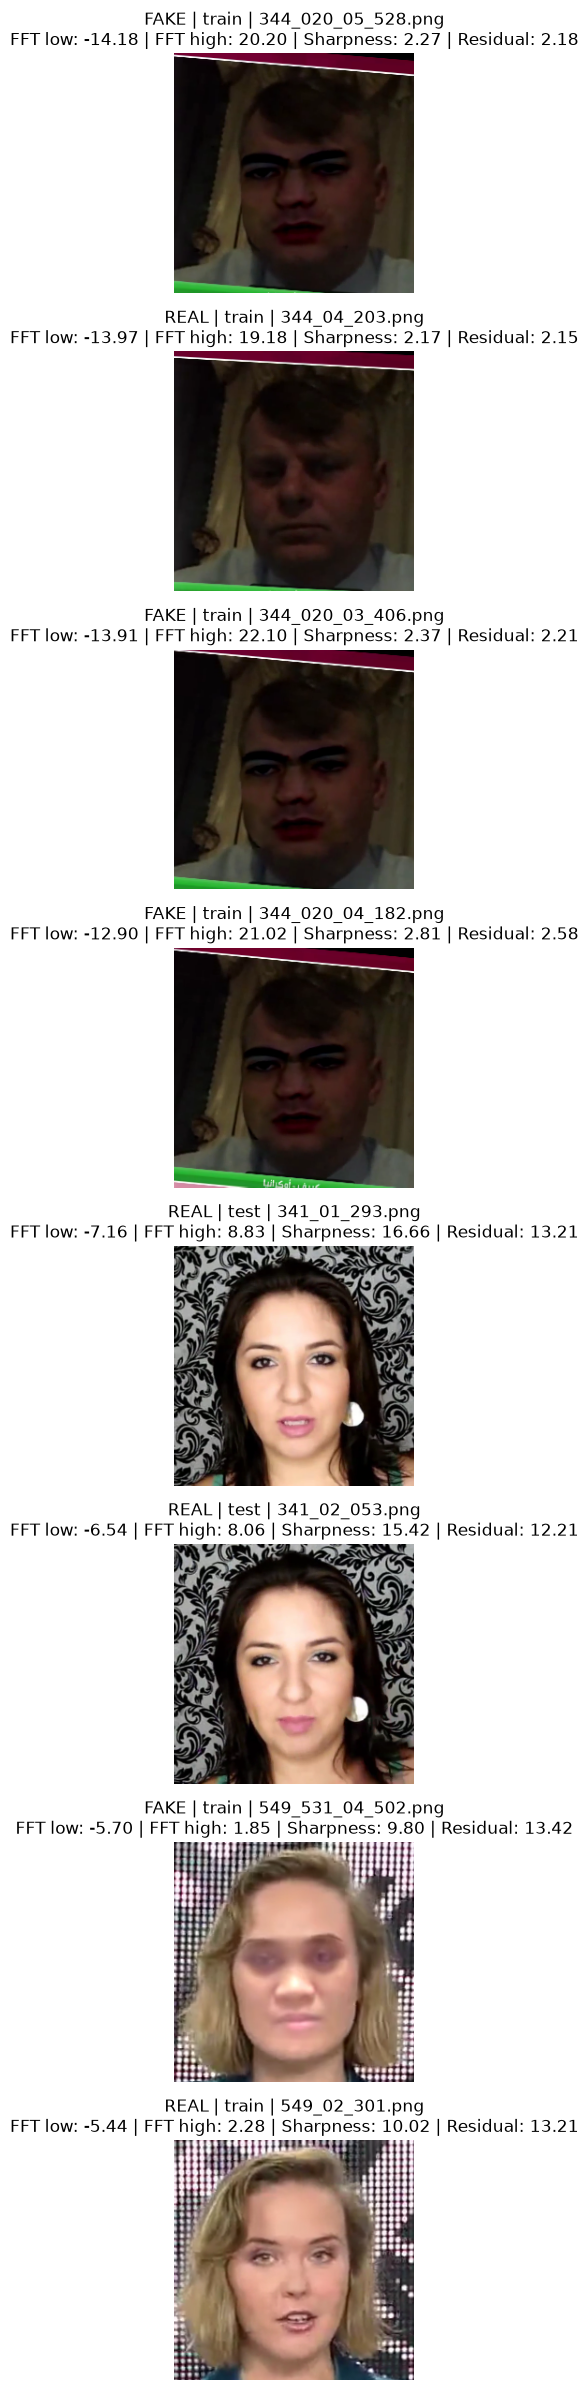

Images inspected: 8


In [7]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Connect descriptor records to the actual current dataset paths
inspection_df = normalized_df.copy()

inspection_df["image_path"] = inspection_df[
    "destination_image"
].apply(
    lambda x: str(DATASET_PATH / 
                  inspection_df.loc[
                      inspection_df["destination_image"] == x,
                      "class"
                  ].iloc[0].lower() / Path(x).name)
)

# Select representative extremes
selected_rows = []

for descriptor, direction in [
    ("fft_low", "lowest"),
    ("fft_high", "highest"),
    ("sharpness", "highest"),
    ("residual_energy", "highest"),
    ("absolute_residual", "highest")
]:
    if direction == "highest":
        selected_rows.append(
            inspection_df.nlargest(2, descriptor)
        )
    else:
        selected_rows.append(
            inspection_df.nsmallest(2, descriptor)
        )

extreme_images = pd.concat(selected_rows).drop_duplicates(
    subset=["destination_image"]
).reset_index(drop=True)

# Display images and descriptor values
fig, axes = plt.subplots(
    len(extreme_images), 1,
    figsize=(12, len(extreme_images) * 3)
)

if len(extreme_images) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, extreme_images.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        f'{row["class"]} | {row["split"]} | '
        f'{Path(row["image_path"]).name}\n'
        f'FFT low: {row["fft_low"]:.2f} | '
        f'FFT high: {row["fft_high"]:.2f} | '
        f'Sharpness: {row["sharpness"]:.2f} | '
        f'Residual: {row["residual_energy"]:.2f}'
    )

plt.tight_layout()
plt.show()

print("Images inspected:", len(extreme_images))


In [8]:

# Verify final descriptor files

raw_check = pd.read_csv(OUTPUT_CSV)
normalized_check = pd.read_csv(NORMALIZED_CSV)

with open(NORMALIZATION_JSON, "r") as f:
    params_check = json.load(f)

assert len(raw_check) == 10000
assert len(normalized_check) == 10000

assert raw_check["split"].value_counts().to_dict() == {
    "train": 7000,
    "test": 1500,
    "validation": 1500
}

assert params_check["fitted_on"] == "train"
assert params_check["training_sample_count"] == 7000

assert np.isfinite(
    normalized_check[descriptor_names].to_numpy()
).all()

# Confirm metadata consistency
metadata_columns = [
    "class",
    "source_subfolder",
    "source_image",
    "destination_image",
    "split"
]

assert raw_check[metadata_columns].equals(
    normalized_check[metadata_columns]
)

print("Raw descriptor rows:", len(raw_check))
print("Normalized descriptor rows:", len(normalized_check))
print("Descriptor count:", len(descriptor_names))
print("Training samples:", (normalized_check["split"] == "train").sum())
print("Validation samples:", (normalized_check["split"] == "validation").sum())
print("Test samples:", (normalized_check["split"] == "test").sum())
print("Normalization fitted on:", params_check["fitted_on"])
print("Metadata consistency: PASS")
print("Finite-value verification: PASS")

print("\nSTEP 30.8 FINAL VERIFICATION PASSED")


Raw descriptor rows: 10000
Normalized descriptor rows: 10000
Descriptor count: 8
Training samples: 7000
Validation samples: 1500
Test samples: 1500
Normalization fitted on: train
Metadata consistency: PASS
Finite-value verification: PASS

STEP 30.8 FINAL VERIFICATION PASSED


In [9]:

import torch
from torch.utils.data import Dataset
from PIL import Image
import pandas as pd
import numpy as np
from pathlib import Path

# Load normalized descriptor dataset
training_df = pd.read_csv(NORMALIZED_CSV)

# Exact descriptor order expected by the model
DESCRIPTOR_COLUMNS = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

# Explicit class mapping
CLASS_TO_LABEL = {
    "REAL": 0,
    "FAKE": 1
}

class AMSFDataset(Dataset):

    def __init__(self, dataframe, dataset_path):
        self.dataframe = dataframe.reset_index(drop=True)
        self.dataset_path = Path(dataset_path)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Reconstruct actual image path
        image_path = (
            self.dataset_path /
            row["class"].lower() /
            Path(row["destination_image"]).name
        )

        # Load and preprocess image
        image = Image.open(image_path).convert("RGB")

        image = image.resize(
            (160, 160),
            Image.Resampling.BILINEAR
        )

        image_array = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        # HWC -> CHW
        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        )

        # Load normalized degradation descriptors
        descriptor_array = row[
            DESCRIPTOR_COLUMNS
        ].to_numpy(dtype=np.float32)

        descriptor_tensor = torch.from_numpy(
            descriptor_array.copy()
        )

        # REAL = 0, FAKE = 1
        label = CLASS_TO_LABEL[row["class"]]
        label_tensor = torch.tensor(
            label,
            dtype=torch.long
        )

        return {
            "image": image_tensor,
            "descriptors": descriptor_tensor,
            "label": label_tensor
        }


# Create a small training dataset for verification
train_df = training_df[
    training_df["split"] == "train"
].copy()

train_dataset = AMSFDataset(
    train_df,
    DATASET_PATH
)

print("Training dataset size:", len(train_dataset))

# Inspect one sample
sample = train_dataset[0]

print("\nSAMPLE VERIFICATION")
print("Image shape:", sample["image"].shape)
print("Descriptor shape:", sample["descriptors"].shape)
print("Label:", sample["label"].item())

print("\nIMAGE RANGE")
print("Minimum:", sample["image"].min().item())
print("Maximum:", sample["image"].max().item())

print("\nDESCRIPTOR FINITE:", torch.isfinite(
    sample["descriptors"]
).all().item())

assert sample["image"].shape == (3, 160, 160)
assert sample["descriptors"].shape == (8,)
assert sample["image"].min() >= 0
assert sample["image"].max() <= 1
assert sample["label"].item() in [0, 1]
assert torch.isfinite(sample["descriptors"]).all()

print("\nSTEP 31.1 DATASET VERIFICATION PASSED")


Training dataset size: 7000

SAMPLE VERIFICATION
Image shape: torch.Size([3, 160, 160])
Descriptor shape: torch.Size([8])
Label: 0

IMAGE RANGE
Minimum: 0.03529411926865578
Maximum: 1.0

DESCRIPTOR FINITE: True

STEP 31.1 DATASET VERIFICATION PASSED


In [10]:

from torch.utils.data import DataLoader

# Separate all three splits
train_df = training_df[
    training_df["split"] == "train"
].copy()

val_df = training_df[
    training_df["split"] == "validation"
].copy()

test_df = training_df[
    training_df["split"] == "test"
].copy()

# Create datasets
train_dataset = AMSFDataset(train_df, DATASET_PATH)
val_dataset = AMSFDataset(val_df, DATASET_PATH)
test_dataset = AMSFDataset(test_df, DATASET_PATH)

# Initial conservative batch size
BATCH_SIZE = 4

# GPU configuration
PIN_MEMORY = torch.cuda.is_available()

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

print("DATASET SIZES")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

print("\nDATALOADER BATCH COUNTS")
print("Training:", len(train_loader))
print("Validation:", len(val_loader))
print("Testing:", len(test_loader))

print("\nBATCH SIZE:", BATCH_SIZE)
print("PIN MEMORY:", PIN_MEMORY)

# Inspect one batch from each loader
for split_name, loader in [
    ("TRAIN", train_loader),
    ("VALIDATION", val_loader),
    ("TEST", test_loader)
]:

    batch = next(iter(loader))

    print(f"\n{split_name} BATCH")
    print("Images:", batch["image"].shape)
    print("Descriptors:", batch["descriptors"].shape)
    print("Labels:", batch["label"].shape)

    assert batch["image"].shape[1:] == (3, 160, 160)
    assert batch["descriptors"].shape[1:] == (8,)
    assert batch["label"].dtype == torch.long

print("\nSTEP 31.2 DATALOADER VERIFICATION PASSED")


DATASET SIZES
Training: 7000
Validation: 1500
Testing: 1500

DATALOADER BATCH COUNTS
Training: 1750
Validation: 375
Testing: 375

BATCH SIZE: 4
PIN MEMORY: True

TRAIN BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

VALIDATION BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

TEST BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

STEP 31.2 DATALOADER VERIFICATION PASSED


In [11]:

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA available:", torch.cuda.is_available())
else:
    print("Running on CPU")


Selected device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA available: True


## Step 31.3 — Restore AMSF-GNet V2 architecture

The following cells reproduce the architecture implementation from `07_amsf_gnet_architecture.ipynb`. They are included here because Jupyter notebooks have independent Python kernels. The differentiable FFT + Haar frequency extractor is used; the older PyWavelets extractor is not used.

Run these cells from top to bottom. Model A includes learned degradation-conditioned node reliability. Model B removes only that learned reliability weighting.

In [12]:

import torch
import torch.nn as nn
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

# Select device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained MobileNetV3-Large
spatial_backbone = mobilenet_v3_large(
    weights=MobileNet_V3_Large_Weights.DEFAULT
)

# Remove original classification head
spatial_backbone.classifier = nn.Identity()

spatial_backbone = spatial_backbone.to(DEVICE)
spatial_backbone.eval()

print("Spatial backbone loaded successfully!")
print("Architecture: MobileNetV3-Large")
print("Device:", DEVICE)


Spatial backbone loaded successfully!
Architecture: MobileNetV3-Large
Device: cuda


In [13]:

class ResidualFeatureExtractor(nn.Module):

    def __init__(self):
        super().__init__()

        self.residual_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.output_layer = nn.Linear(128, 256)

    def forward(self, images):

        # Convert RGB to grayscale
        gray = images.mean(dim=1, keepdim=True)

        # Extract high-frequency residual
        blurred = nn.functional.avg_pool2d(
            gray,
            kernel_size=5,
            stride=1,
            padding=2
        )

        residual = gray - blurred

        # Learn residual features
        features = self.residual_conv(residual)

        features = features.flatten(1)

        features = self.output_layer(features)

        return features


residual_extractor = ResidualFeatureExtractor().to(DEVICE)

print("Residual feature extractor initialized!")


Residual feature extractor initialized!


In [14]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class DifferentiableFrequencyExtractor(nn.Module):

    def __init__(self):
        super().__init__()

        # Haar wavelet filters
        s = 1.0 / math.sqrt(2.0)

        haar_filters = torch.tensor([
            [[s * s,  s * s],
             [s * s,  s * s]],

            [[s * s, -s * s],
             [s * s, -s * s]],

            [[s * s,  s * s],
             [-s * s, -s * s]],

            [[s * s, -s * s],
             [-s * s,  s * s]]
        ], dtype=torch.float32).unsqueeze(1)

        self.register_buffer("haar_filters", haar_filters)

    def haar_transform(self, x):

        return F.conv2d(
            x,
            self.haar_filters,
            stride=2
        )

    def forward(self, images):

        # Grayscale conversion
        gray = images.mean(dim=1, keepdim=True)

        # FFT representation
        fft = torch.fft.fft2(gray)
        fft = torch.fft.fftshift(fft, dim=(-2, -1))
        fft_features = torch.log1p(torch.abs(fft))

        # First Haar decomposition
        level1 = self.haar_transform(gray)

        ll1 = level1[:, 0:1]
        detail1 = level1[:, 1:4]

        # Second Haar decomposition on approximation
        level2 = self.haar_transform(ll1)

        ll2 = level2[:, 0:1]
        detail2 = level2[:, 1:4]

        # Concatenate coefficients
        haar_features = torch.cat([
            ll2.flatten(1),
            detail2.flatten(1),
            detail1.flatten(1)
        ], dim=1)

        return fft_features, haar_features


frequency_extractor = DifferentiableFrequencyExtractor().to(DEVICE)

print("Differentiable frequency extractor initialized!")


Differentiable frequency extractor initialized!


In [15]:

class FrequencyEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        # FFT feature encoder
        self.fft_encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(64, 128),
            nn.ReLU(inplace=True)
        )

        # Haar feature encoder
        self.haar_encoder = nn.Sequential(
            nn.Linear(25600, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(512, 128),
            nn.ReLU(inplace=True)
        )

        # Combined frequency representation
        self.fusion = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(inplace=True)
        )

    def forward(self, fft_features, haar_features):

        fft_vector = self.fft_encoder(fft_features)
        haar_vector = self.haar_encoder(haar_features)

        combined = torch.cat(
            [fft_vector, haar_vector],
            dim=1
        )

        return self.fusion(combined)


frequency_encoder = FrequencyEncoder().to(DEVICE)

print("Frequency encoder initialized!")


Frequency encoder initialized!


In [16]:

class DegradationConditionedReliability(nn.Module):

    def __init__(self, descriptor_dim=8, hidden_dim=64):
        super().__init__()

        self.reliability_network = nn.Sequential(

            nn.Linear(descriptor_dim, hidden_dim),
            nn.ReLU(inplace=True),

            nn.Linear(hidden_dim, 32),
            nn.ReLU(inplace=True),

            nn.Linear(32, 3),
            nn.Sigmoid()
        )

    def forward(self, degradation_descriptors):

        reliability_scores = self.reliability_network(
            degradation_descriptors
        )

        return reliability_scores


reliability_module = DegradationConditionedReliability().to(DEVICE)

print("Degradation-conditioned reliability module initialized!")


Degradation-conditioned reliability module initialized!


In [17]:

class ReliabilityWeightedFusion(nn.Module):

    def __init__(self, feature_dim=256):
        super().__init__()

        # Project spatial features: 960 -> 256
        self.spatial_projection = nn.Sequential(
            nn.Linear(960, feature_dim),
            nn.LayerNorm(feature_dim),
            nn.ReLU(inplace=True)
        )

        # Frequency features: 256 -> 256
        self.frequency_projection = nn.Sequential(
            nn.Linear(256, feature_dim),
            nn.LayerNorm(feature_dim),
            nn.ReLU(inplace=True)
        )

        # Residual features: 256 -> 256
        self.residual_projection = nn.Sequential(
            nn.Linear(256, feature_dim),
            nn.LayerNorm(feature_dim),
            nn.ReLU(inplace=True)
        )

    def forward(self, features, reliability_scores):

        spatial = self.spatial_projection(
            features["spatial"]
        )

        frequency = self.frequency_projection(
            features["frequency"]
        )

        residual = self.residual_projection(
            features["residual"]
        )

        # Create three feature nodes
        nodes = torch.stack(
            [spatial, frequency, residual],
            dim=1
        )

        # Apply branch-specific reliability scores
        weighted_nodes = (
            nodes * reliability_scores.unsqueeze(-1)
        )

        return weighted_nodes


fusion_module = ReliabilityWeightedFusion().to(DEVICE)

print("Reliability-weighted fusion module initialized!")


Reliability-weighted fusion module initialized!


In [18]:

class MultiHeadGraphAttention(nn.Module):

    def __init__(self, feature_dim=256, num_heads=4):
        super().__init__()

        assert feature_dim % num_heads == 0

        self.feature_dim = feature_dim
        self.num_heads = num_heads
        self.head_dim = feature_dim // num_heads

        self.query = nn.Linear(feature_dim, feature_dim)
        self.key = nn.Linear(feature_dim, feature_dim)
        self.value = nn.Linear(feature_dim, feature_dim)

        self.output_projection = nn.Linear(
            feature_dim, feature_dim
        )

        self.norm = nn.LayerNorm(feature_dim)

        self.scale = self.head_dim ** -0.5

    def forward(self, nodes):

        batch_size, num_nodes, _ = nodes.shape

        Q = self.query(nodes)
        K = self.key(nodes)
        V = self.value(nodes)

        # Separate attention heads
        Q = Q.view(
            batch_size, num_nodes,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        K = K.view(
            batch_size, num_nodes,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        V = V.view(
            batch_size, num_nodes,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        # Attention calculation
        scores = torch.matmul(
            Q, K.transpose(-2, -1)
        ) * self.scale

        attention = torch.softmax(scores, dim=-1)

        attended = torch.matmul(attention, V)

        # Combine attention heads
        attended = attended.transpose(1, 2).contiguous()

        attended = attended.view(
            batch_size, num_nodes, self.feature_dim
        )

        output = self.output_projection(attended)

        output = self.norm(output + nodes)

        return output, attention


multihead_graph = MultiHeadGraphAttention(
    feature_dim=256,
    num_heads=4
).to(DEVICE)

print("Multi-head graph attention initialized!")


Multi-head graph attention initialized!


In [19]:

class AdaptiveBranchGating(nn.Module):

    def __init__(self, feature_dim=256, hidden_dim=128):
        super().__init__()

        self.gate_network = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(inplace=True),

            nn.Linear(hidden_dim, 64),
            nn.ReLU(inplace=True),

            nn.Linear(64, 1)
        )

    def forward(self, graph_nodes):

        # graph_nodes: (B, 3, 256)

        # Calculate importance score for each branch
        gate_logits = self.gate_network(
            graph_nodes
        ).squeeze(-1)

        # Normalize branch importance
        gate_weights = torch.softmax(
            gate_logits, dim=1
        )

        # Weighted feature fusion
        fused_features = torch.sum(
            graph_nodes * gate_weights.unsqueeze(-1),
            dim=1
        )

        return fused_features, gate_weights


adaptive_gating = AdaptiveBranchGating(
    feature_dim=256,
    hidden_dim=128
).to(DEVICE)

print("Adaptive Branch Gating initialized successfully!")


Adaptive Branch Gating initialized successfully!


In [20]:

class AMSFClassifier(nn.Module):

    def __init__(self, input_dim=256, num_classes=2):
        super().__init__()

        self.classifier = nn.Sequential(

            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, fused_features):
        logits = self.classifier(fused_features)
        return logits


classifier = AMSFClassifier(
    input_dim=256,
    num_classes=2
).to(DEVICE)

print("AMSF classifier initialized successfully!")


AMSF classifier initialized successfully!


In [21]:

import copy
import torch
import torch.nn as nn

class AMSFGNetV2(nn.Module):

    def __init__(
        self,
        spatial_backbone,
        frequency_extractor,
        frequency_encoder,
        residual_extractor,
        use_reliability=True
    ):
        super().__init__()

        self.use_reliability = use_reliability

        # Feature extraction branches
        self.spatial = spatial_backbone
        self.frequency_extractor = frequency_extractor
        self.frequency_encoder = frequency_encoder
        self.residual = residual_extractor

        # ImageNet normalization for spatial branch only
        self.register_buffer(
            "imagenet_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "imagenet_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

        # Degradation-conditioned reliability
        self.reliability = DegradationConditionedReliability(
            descriptor_dim=8,
            hidden_dim=64
        )

        # Project and combine the three branch features
        self.reliability_fusion = ReliabilityWeightedFusion(
            feature_dim=256
        )

        # Multi-head graph attention
        self.graph_attention = MultiHeadGraphAttention(
            feature_dim=256,
            num_heads=4
        )

        # Adaptive branch gating
        self.adaptive_gating = AdaptiveBranchGating(
            feature_dim=256,
            hidden_dim=128
        )

        # Final classifier
        self.classifier = AMSFClassifier(
            input_dim=256,
            num_classes=2
        )

    def forward(self, raw_images, degradation_descriptors):

        # raw_images must be RGB in [0, 1]
        # degradation_descriptors must have 8 normalized values

        # 1. Spatial branch: ImageNet-normalized input
        normalized_images = (
            raw_images - self.imagenet_mean
        ) / self.imagenet_std

        spatial_features = self.spatial(normalized_images)

        # 2. Frequency branch: raw image input
        fft_features, haar_features = self.frequency_extractor(
            raw_images
        )

        frequency_features = self.frequency_encoder(
            fft_features,
            haar_features
        )

        # 3. Residual branch: raw image input
        residual_features = self.residual(raw_images)

        branch_features = {
            "spatial": spatial_features,
            "frequency": frequency_features,
            "residual": residual_features
        }

        # 4. Reliability scores
        if self.use_reliability:
            reliability_scores = self.reliability(
                degradation_descriptors
            )
        else:
            # Ablation: no learned reliability weighting
            reliability_scores = torch.ones(
                raw_images.size(0),
                3,
                device=raw_images.device,
                dtype=raw_images.dtype
            )

        # 5. Reliability-weighted feature fusion
        nodes = self.reliability_fusion(
            branch_features,
            reliability_scores
        )

        # 6. Multi-head graph attention
        graph_nodes, graph_attention_weights = (
            self.graph_attention(nodes)
        )

        # 7. Adaptive branch gating
        fused_features, gate_weights = self.adaptive_gating(
            graph_nodes
        )

        # 8. REAL / FAKE classification
        logits = self.classifier(fused_features)

        return {
            "logits": logits,
            "reliability_scores": reliability_scores,
            "graph_attention": graph_attention_weights,
            "gate_weights": gate_weights,
            "fused_features": fused_features
        }


# Create Model A: Full AMSF-GNet V2
model_A = AMSFGNetV2(
    spatial_backbone=copy.deepcopy(spatial_backbone),
    frequency_extractor=copy.deepcopy(frequency_extractor),
    frequency_encoder=copy.deepcopy(frequency_encoder),
    residual_extractor=copy.deepcopy(residual_extractor),
    use_reliability=True
).to(DEVICE)


# Create Model B: Ablation without learned reliability
model_B = AMSFGNetV2(
    spatial_backbone=copy.deepcopy(spatial_backbone),
    frequency_extractor=copy.deepcopy(frequency_extractor),
    frequency_encoder=copy.deepcopy(frequency_encoder),
    residual_extractor=copy.deepcopy(residual_extractor),
    use_reliability=False
).to(DEVICE)


print("Model A initialized: Full AMSF-GNet V2")
print("Model B initialized: Reliability ablation")
print("Device:", DEVICE)


Model A initialized: Full AMSF-GNet V2
Model B initialized: Reliability ablation
Device: cuda


### Step 31.4 — Verify restored architecture

Run the following verification cells. All required architecture objects must be available before the real DataLoader forward-pass test.

In [22]:

required_variables = [
    "AMSFGNetV2",
    "spatial_backbone",
    "frequency_extractor",
    "frequency_encoder",
    "residual_extractor",
    "model_A",
    "model_B"
]

print("ARCHITECTURE VARIABLE CHECK")
print("=" * 50)

for variable in required_variables:
    exists = variable in globals()
    print(f"{variable}: {'AVAILABLE' if exists else 'MISSING'}")


ARCHITECTURE VARIABLE CHECK
AMSFGNetV2: AVAILABLE
spatial_backbone: AVAILABLE
frequency_extractor: AVAILABLE
frequency_encoder: AVAILABLE
residual_extractor: AVAILABLE
model_A: AVAILABLE
model_B: AVAILABLE


In [23]:
print("Model A available:", "model_A" in globals())
print("Model B available:", "model_B" in globals())

if "model_A" in globals() and "model_B" in globals():
    print("\nModel A parameters:",
          sum(p.numel() for p in model_A.parameters()))

    print("Model B parameters:",
          sum(p.numel() for p in model_B.parameters()))

    print("\nARCHITECTURE RESTORATION PASSED")

Model A available: True
Model B available: True

Model A parameters: 17093046
Model B parameters: 17093046

ARCHITECTURE RESTORATION PASSED


In [24]:

print("MODEL RESTORATION CHECK")
print("=" * 45)

print("AMSFGNetV2:", "AMSFGNetV2" in globals())
print("Model A:", "model_A" in globals())
print("Model B:", "model_B" in globals())

if "model_A" in globals() and "model_B" in globals():

    print("\nModel A parameters:",
          sum(p.numel() for p in model_A.parameters()))

    print("Model B parameters:",
          sum(p.numel() for p in model_B.parameters()))

    print("\nModel A device:",
          next(model_A.parameters()).device)

    print("Model B device:",
          next(model_B.parameters()).device)

    print("\nARCHITECTURE RESTORATION PASSED")


MODEL RESTORATION CHECK
AMSFGNetV2: True
Model A: True
Model B: True

Model A parameters: 17093046
Model B parameters: 17093046

Model A device: cuda:0
Model B device: cuda:0

ARCHITECTURE RESTORATION PASSED


In [25]:

import torch
import gc

# Get one real training batch
batch = next(iter(train_loader))

images = batch["image"].to(DEVICE)
descriptors = batch["descriptors"].to(DEVICE)
labels = batch["label"].to(DEVICE)

print("INPUT VERIFICATION")
print("Images:", images.shape)
print("Descriptors:", descriptors.shape)
print("Labels:", labels.shape)

models_to_test = {
    "Model A - Full AMSF-GNet V2": model_A,
    "Model B - Without Reliability": model_B
}

for model_name, model in models_to_test.items():

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    model = model.to(DEVICE)
    model.eval()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    with torch.inference_mode():
        output = model(images, descriptors)

    logits = output["logits"]

    print("Logits shape:", logits.shape)
    print("Predictions:", torch.argmax(logits, dim=1).cpu().tolist())
    print("Actual labels:", labels.cpu().tolist())

    print("Reliability shape:",
          output["reliability_scores"].shape)

    print("Graph attention shape:",
          output["graph_attention"].shape)

    print("Gate weights shape:",
          output["gate_weights"].shape)

    print("Finite logits:",
          torch.isfinite(logits).all().item())

    print("Gate weights sum:",
          output["gate_weights"].sum(dim=1).cpu().tolist())

    assert logits.shape == (4, 2)
    assert output["reliability_scores"].shape == (4, 3)
    assert output["graph_attention"].shape == (4, 4, 3, 3)
    assert output["gate_weights"].shape == (4, 3)
    assert torch.isfinite(logits).all()
    assert torch.allclose(
        output["gate_weights"].sum(dim=1),
        torch.ones(4, device=DEVICE),
        atol=1e-5
    )

    if torch.cuda.is_available():
        print("Peak GPU memory:",
              round(torch.cuda.max_memory_allocated() / 1024**3, 3),
              "GB")

    del output
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nSTEP 31.3 MODEL FORWARD VERIFICATION PASSED")


INPUT VERIFICATION
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

Model A - Full AMSF-GNet V2
Logits shape: torch.Size([4, 2])
Predictions: [0, 0, 0, 0]
Actual labels: [0, 0, 1, 0]
Reliability shape: torch.Size([4, 3])
Graph attention shape: torch.Size([4, 4, 3, 3])
Gate weights shape: torch.Size([4, 3])
Finite logits: True
Gate weights sum: [1.0, 1.0, 1.0000001192092896, 1.0]
Peak GPU memory: 0.255 GB

Model B - Without Reliability
Logits shape: torch.Size([4, 2])
Predictions: [0, 0, 0, 0]
Actual labels: [0, 0, 1, 0]
Reliability shape: torch.Size([4, 3])
Graph attention shape: torch.Size([4, 4, 3, 3])
Gate weights shape: torch.Size([4, 3])
Finite logits: True
Gate weights sum: [1.0, 0.9999998807907104, 1.0, 1.0]
Peak GPU memory: 0.255 GB

STEP 31.3 MODEL FORWARD VERIFICATION PASSED


In [26]:

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from pathlib import Path

# --------------------------------------------------
# 1. TRAINING CONFIGURATION
# --------------------------------------------------

EPOCHS = 20

LEARNING_RATE_SPATIAL = 1e-5
LEARNING_RATE_OTHER = 1e-4
WEIGHT_DECAY = 1e-4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = Path(r"D:\FINAL DFDT\checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. MOVE MODELS TO DEVICE
# --------------------------------------------------

model_A = model_A.to(DEVICE)
model_B = model_B.to(DEVICE)

# --------------------------------------------------
# 3. OPTIMIZER CREATION
# --------------------------------------------------

def create_optimizer(model):

    spatial_parameters = list(model.spatial.parameters())

    spatial_ids = {id(p) for p in spatial_parameters}

    other_parameters = [
        p for p in model.parameters()
        if id(p) not in spatial_ids and p.requires_grad
    ]

    return AdamW(
        [
            {
                "params": spatial_parameters,
                "lr": LEARNING_RATE_SPATIAL
            },
            {
                "params": other_parameters,
                "lr": LEARNING_RATE_OTHER
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

optimizer_A = create_optimizer(model_A)
optimizer_B = create_optimizer(model_B)

# --------------------------------------------------
# 4. LOSS FUNCTIONS
# --------------------------------------------------

criterion_A = nn.CrossEntropyLoss().to(DEVICE)
criterion_B = nn.CrossEntropyLoss().to(DEVICE)

# --------------------------------------------------
# 5. LEARNING RATE SCHEDULERS
# --------------------------------------------------

scheduler_A = ReduceLROnPlateau(
    optimizer_A,
    mode="max",
    factor=0.5,
    patience=2
)

scheduler_B = ReduceLROnPlateau(
    optimizer_B,
    mode="max",
    factor=0.5,
    patience=2
)

# --------------------------------------------------
# 6. AUTOMATIC MIXED PRECISION
# --------------------------------------------------

AMP_ENABLED = DEVICE.type == "cuda"

scaler_A = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)

scaler_B = torch.amp.GradScaler(
    "cuda",
    enabled=AMP_ENABLED
)

# --------------------------------------------------
# 7. PARAMETER COUNT
# --------------------------------------------------

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    return total, trainable

total_A, trainable_A = count_parameters(model_A)
total_B, trainable_B = count_parameters(model_B)

# --------------------------------------------------
# 8. VERIFICATION OUTPUT
# --------------------------------------------------

print("=" * 55)
print("STEP 32.1 - TRAINING CONFIGURATION")
print("=" * 55)

print("Device:", DEVICE)
print("AMP enabled:", AMP_ENABLED)
print("Epochs:", EPOCHS)

print("\nMODEL A")
print("Total parameters:", f"{total_A:,}")
print("Trainable parameters:", f"{trainable_A:,}")
print("Optimizer:", type(optimizer_A).__name__)

print("\nMODEL B")
print("Total parameters:", f"{total_B:,}")
print("Trainable parameters:", f"{trainable_B:,}")
print("Optimizer:", type(optimizer_B).__name__)

print("\nLEARNING RATES")
print("Spatial:", LEARNING_RATE_SPATIAL)
print("Other branches:", LEARNING_RATE_OTHER)

print("\nCHECKPOINT DIRECTORY:", CHECKPOINT_DIR)
print("Training loaders:", len(train_loader))
print("Validation loaders:", len(val_loader))

assert len(train_loader) > 0
assert len(val_loader) > 0
assert total_A > 0 and total_B > 0
assert trainable_A > 0 and trainable_B > 0

print("\nSTEP 32.1 CONFIGURATION VERIFICATION PASSED")


STEP 32.1 - TRAINING CONFIGURATION
Device: cuda
AMP enabled: True
Epochs: 20

MODEL A
Total parameters: 17,093,046
Trainable parameters: 17,093,046
Optimizer: AdamW

MODEL B
Total parameters: 17,093,046
Trainable parameters: 17,093,046
Optimizer: AdamW

LEARNING RATES
Spatial: 1e-05
Other branches: 0.0001

CHECKPOINT DIRECTORY: D:\FINAL DFDT\checkpoints
Training loaders: 1750
Validation loaders: 375

STEP 32.1 CONFIGURATION VERIFICATION PASSED


In [27]:

import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ==========================================================
# STEP 32.2 - TRAINING ENGINE
# ==========================================================

def run_training_epoch(model, loader, optimizer, criterion, scaler, device):

    model.train()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    progress = tqdm(loader, desc="Training", leave=False)

    for batch in progress:

        images = batch["image"].to(device, non_blocking=True)
        descriptors = batch["descriptors"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            outputs = model(images, descriptors)
            logits = outputs["logits"]
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

        predictions = torch.argmax(logits.detach(), dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    metrics = {
        "loss": total_loss / len(loader),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions, zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions, zero_division=0
        )
    }

    return metrics


# ==========================================================
# VALIDATION FUNCTION
# ==========================================================

@torch.no_grad()
def evaluate_model(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    for batch in tqdm(loader, desc="Validation", leave=False):

        images = batch["image"].to(device, non_blocking=True)
        descriptors = batch["descriptors"].to(device, non_blocking=True)
        labels = batch["label"].to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            outputs = model(images, descriptors)
            logits = outputs["logits"]
            loss = criterion(logits, labels)

        total_loss += loss.item()

        predictions = torch.argmax(logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    metrics = {
        "loss": total_loss / len(loader),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions, zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions, zero_division=0
        )
    }

    return metrics


# ==========================================================
# TRAINING HISTORY
# ==========================================================

history_A = {
    "train_loss": [],
    "train_accuracy": [],
    "train_precision": [],
    "train_recall": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

history_B = {
    "train_loss": [],
    "train_accuracy": [],
    "train_precision": [],
    "train_recall": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

# ==========================================================
# FUNCTION VERIFICATION
# ==========================================================

assert callable(run_training_epoch)
assert callable(evaluate_model)

assert len(history_A) == 10
assert len(history_B) == 10

print("Training function:", "AVAILABLE")
print("Validation function:", "AVAILABLE")
print("Model A history:", "INITIALIZED")
print("Model B history:", "INITIALIZED")
print("AMP:", AMP_ENABLED)
print("Gradient clipping:", "ENABLED")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\nSTEP 32.2 TRAINING ENGINE VERIFICATION PASSED")


Training function: AVAILABLE
Validation function: AVAILABLE
Model A history: INITIALIZED
Model B history: INITIALIZED
AMP: True
Gradient clipping: ENABLED
Training batches: 1750
Validation batches: 375

STEP 32.2 TRAINING ENGINE VERIFICATION PASSED


# Model A — Full AMSF-GNet V2

In [28]:

# ==========================================================
# STEP 32.3 - FIRST TRAINING EPOCH: MODEL A
# ==========================================================

import time
import torch

print("=" * 60)
print("MODEL A - FIRST TRAINING EPOCH")
print("=" * 60)

start_time = time.time()

# Train for one epoch
train_metrics_A = run_training_epoch(
    model=model_A,
    loader=train_loader,
    optimizer=optimizer_A,
    criterion=criterion_A,
    scaler=scaler_A,
    device=DEVICE
)

# Validate
val_metrics_A = evaluate_model(
    model=model_A,
    loader=val_loader,
    criterion=criterion_A,
    device=DEVICE
)

# Update scheduler using validation F1
scheduler_A.step(val_metrics_A["f1"])

# Save metrics in history
for metric in ["loss", "accuracy", "precision", "recall", "f1"]:
    history_A[f"train_{metric}"].append(train_metrics_A[metric])
    history_A[f"val_{metric}"].append(val_metrics_A[metric])

elapsed_time = time.time() - start_time

# Save first-epoch checkpoint
checkpoint_path_A = CHECKPOINT_DIR / "model_A_epoch_01.pth"

torch.save({
    "epoch": 1,
    "model_state_dict": model_A.state_dict(),
    "optimizer_state_dict": optimizer_A.state_dict(),
    "scaler_state_dict": scaler_A.state_dict(),
    "train_metrics": train_metrics_A,
    "val_metrics": val_metrics_A
}, checkpoint_path_A)

# Display results
print("\n" + "=" * 60)
print("MODEL A - EPOCH 1 RESULTS")
print("=" * 60)

print("\nTRAINING METRICS")
for key, value in train_metrics_A.items():
    print(f"{key.capitalize():12s}: {value:.4f}")

print("\nVALIDATION METRICS")
for key, value in val_metrics_A.items():
    print(f"{key.capitalize():12s}: {value:.4f}")

print("\nTraining time:", f"{elapsed_time / 60:.2f} minutes")
print("Checkpoint saved:", checkpoint_path_A)
print("Checkpoint exists:", checkpoint_path_A.exists())

if torch.cuda.is_available():
    print(
        "Peak GPU memory:",
        f"{torch.cuda.max_memory_allocated() / (1024**3):.3f} GB"
    )

assert np.isfinite(train_metrics_A["loss"])
assert np.isfinite(val_metrics_A["loss"])
assert checkpoint_path_A.exists()

print("\nSTEP 32.3 MODEL A FIRST EPOCH COMPLETED")


MODEL A - FIRST TRAINING EPOCH



MODEL A - EPOCH 1 RESULTS

TRAINING METRICS
Loss        : 0.6520
Accuracy    : 0.6189
Precision   : 0.6373
Recall      : 0.5517
F1          : 0.5914

VALIDATION METRICS
Loss        : 0.5094
Accuracy    : 0.7573
Precision   : 0.7494
Recall      : 0.7733
F1          : 0.7612

Training time: 2.72 minutes
Checkpoint saved: D:\FINAL DFDT\checkpoints\model_A_epoch_01.pth
Checkpoint exists: True
Peak GPU memory: 0.508 GB

STEP 32.3 MODEL A FIRST EPOCH COMPLETED


In [29]:

# ==========================================================
# STEP 32.4 - FIRST TRAINING EPOCH: MODEL B
# ==========================================================

import time
import torch

print("=" * 60)
print("MODEL B - FIRST TRAINING EPOCH")
print("=" * 60)

start_time = time.time()

train_metrics_B = run_training_epoch(
    model=model_B,
    loader=train_loader,
    optimizer=optimizer_B,
    criterion=criterion_B,
    scaler=scaler_B,
    device=DEVICE
)

val_metrics_B = evaluate_model(
    model=model_B,
    loader=val_loader,
    criterion=criterion_B,
    device=DEVICE
)

scheduler_B.step(val_metrics_B["f1"])

for metric in ["loss", "accuracy", "precision", "recall", "f1"]:
    history_B[f"train_{metric}"].append(train_metrics_B[metric])
    history_B[f"val_{metric}"].append(val_metrics_B[metric])

elapsed_time = time.time() - start_time

checkpoint_path_B = CHECKPOINT_DIR / "model_B_epoch_01.pth"

torch.save({
    "epoch": 1,
    "model_state_dict": model_B.state_dict(),
    "optimizer_state_dict": optimizer_B.state_dict(),
    "scaler_state_dict": scaler_B.state_dict(),
    "train_metrics": train_metrics_B,
    "val_metrics": val_metrics_B
}, checkpoint_path_B)

print("\n" + "=" * 60)
print("MODEL B - EPOCH 1 RESULTS")
print("=" * 60)

print("\nTRAINING METRICS")
for key, value in train_metrics_B.items():
    print(f"{key.capitalize():12s}: {value:.4f}")

print("\nVALIDATION METRICS")
for key, value in val_metrics_B.items():
    print(f"{key.capitalize():12s}: {value:.4f}")

print("\nTraining time:", f"{elapsed_time / 60:.2f} minutes")
print("Checkpoint saved:", checkpoint_path_B)
print("Checkpoint exists:", checkpoint_path_B.exists())

assert np.isfinite(train_metrics_B["loss"])
assert np.isfinite(val_metrics_B["loss"])
assert checkpoint_path_B.exists()

print("\nSTEP 32.4 MODEL B FIRST EPOCH COMPLETED")


MODEL B - FIRST TRAINING EPOCH



MODEL B - EPOCH 1 RESULTS

TRAINING METRICS
Loss        : 0.6423
Accuracy    : 0.6314
Precision   : 0.6454
Recall      : 0.5834
F1          : 0.6128

VALIDATION METRICS
Loss        : 0.5076
Accuracy    : 0.7507
Precision   : 0.7217
Recall      : 0.8160
F1          : 0.7660

Training time: 2.77 minutes
Checkpoint saved: D:\FINAL DFDT\checkpoints\model_B_epoch_01.pth
Checkpoint exists: True

STEP 32.4 MODEL B FIRST EPOCH COMPLETED


In [30]:

# ==========================================================
# STEP 32.5 - COMPLETE TRAINING: MODEL A AND MODEL B
# ==========================================================

import time
import copy
import torch
import numpy as np

# Initialize best validation F1 from epoch 1
best_f1_A = max(history_A["val_f1"])
best_f1_B = max(history_B["val_f1"])

best_epoch_A = 1
best_epoch_B = 1

best_state_A = copy.deepcopy(model_A.state_dict())
best_state_B = copy.deepcopy(model_B.state_dict())

# Save initial best checkpoints
def save_best_checkpoint(model, optimizer, scaler, epoch, metrics, name):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "val_metrics": metrics
    }, CHECKPOINT_DIR / f"{name}_best.pth")

save_best_checkpoint(
    model_A, optimizer_A, scaler_A, 1,
    val_metrics_A, "model_A"
)

save_best_checkpoint(
    model_B, optimizer_B, scaler_B, 1,
    val_metrics_B, "model_B"
)

# ----------------------------------------------------------
# TRAINING LOOP
# ----------------------------------------------------------

for epoch in range(2, EPOCHS + 1):

    print("\n" + "=" * 65)
    print(f"EPOCH {epoch}/{EPOCHS}")
    print("=" * 65)

    # ---------------- MODEL A ----------------

    print("\nMODEL A - FULL AMSF-GNET V2")

    start_time = time.time()

    train_A = run_training_epoch(
        model_A, train_loader, optimizer_A,
        criterion_A, scaler_A, DEVICE
    )

    val_A = evaluate_model(
        model_A, val_loader, criterion_A, DEVICE
    )

    scheduler_A.step(val_A["f1"])

    for metric in ["loss", "accuracy", "precision", "recall", "f1"]:
        history_A[f"train_{metric}"].append(train_A[metric])
        history_A[f"val_{metric}"].append(val_A[metric])

    if val_A["f1"] > best_f1_A:
        best_f1_A = val_A["f1"]
        best_epoch_A = epoch
        best_state_A = copy.deepcopy(model_A.state_dict())

        save_best_checkpoint(
            model_A, optimizer_A, scaler_A,
            epoch, val_A, "model_A"
        )

    print("Train loss:", round(train_A["loss"], 4))
    print("Train accuracy:", round(train_A["accuracy"], 4))
    print("Validation loss:", round(val_A["loss"], 4))
    print("Validation accuracy:", round(val_A["accuracy"], 4))
    print("Validation F1:", round(val_A["f1"], 4))
    print("Best F1:", round(best_f1_A, 4), "at epoch", best_epoch_A)
    print("Time:", round((time.time() - start_time) / 60, 2), "minutes")

    # ---------------- MODEL B ----------------

    print("\nMODEL B - WITHOUT RELIABILITY")

    start_time = time.time()

    train_B = run_training_epoch(
        model_B, train_loader, optimizer_B,
        criterion_B, scaler_B, DEVICE
    )

    val_B = evaluate_model(
        model_B, val_loader, criterion_B, DEVICE
    )

    scheduler_B.step(val_B["f1"])

    for metric in ["loss", "accuracy", "precision", "recall", "f1"]:
        history_B[f"train_{metric}"].append(train_B[metric])
        history_B[f"val_{metric}"].append(val_B[metric])

    if val_B["f1"] > best_f1_B:
        best_f1_B = val_B["f1"]
        best_epoch_B = epoch
        best_state_B = copy.deepcopy(model_B.state_dict())

        save_best_checkpoint(
            model_B, optimizer_B, scaler_B,
            epoch, val_B, "model_B"
        )

    print("Train loss:", round(train_B["loss"], 4))
    print("Train accuracy:", round(train_B["accuracy"], 4))
    print("Validation loss:", round(val_B["loss"], 4))
    print("Validation accuracy:", round(val_B["accuracy"], 4))
    print("Validation F1:", round(val_B["f1"], 4))
    print("Best F1:", round(best_f1_B, 4), "at epoch", best_epoch_B)
    print("Time:", round((time.time() - start_time) / 60, 2), "minutes")

    # Save latest epoch checkpoints
    torch.save({
        "epoch": epoch,
        "model_state_dict": model_A.state_dict(),
        "optimizer_state_dict": optimizer_A.state_dict(),
        "scaler_state_dict": scaler_A.state_dict(),
        "val_metrics": val_A
    }, CHECKPOINT_DIR / "model_A_latest.pth")

    torch.save({
        "epoch": epoch,
        "model_state_dict": model_B.state_dict(),
        "optimizer_state_dict": optimizer_B.state_dict(),
        "scaler_state_dict": scaler_B.state_dict(),
        "val_metrics": val_B
    }, CHECKPOINT_DIR / "model_B_latest.pth")

# ----------------------------------------------------------
# FINAL TRAINING SUMMARY
# ----------------------------------------------------------

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)

print("Model A best validation F1:", round(best_f1_A, 4))
print("Model A best epoch:", best_epoch_A)

print("Model B best validation F1:", round(best_f1_B, 4))
print("Model B best epoch:", best_epoch_B)

print("\nModel A history length:", len(history_A["val_f1"]))
print("Model B history length:", len(history_B["val_f1"]))

assert len(history_A["val_f1"]) == EPOCHS
assert len(history_B["val_f1"]) == EPOCHS
assert np.isfinite(history_A["val_loss"]).all()
assert np.isfinite(history_B["val_loss"]).all()

print("\nSTEP 32.5 COMPLETE TRAINING PASSED")



EPOCH 2/20

MODEL A - FULL AMSF-GNET V2


Train loss: 0.4912
Train accuracy: 0.7866
Validation loss: 0.325
Validation accuracy: 0.8633
Validation F1: 0.8616
Best F1: 0.8616 at epoch 2
Time: 2.8 minutes

MODEL B - WITHOUT RELIABILITY


Train loss: 0.49
Train accuracy: 0.8
Validation loss: 0.3463
Validation accuracy: 0.848
Validation F1: 0.8591
Best F1: 0.8591 at epoch 2
Time: 2.82 minutes

EPOCH 3/20

MODEL A - FULL AMSF-GNET V2


Train loss: 0.4927
Train accuracy: 0.8303
Validation loss: 0.297
Validation accuracy: 0.884
Validation F1: 0.8863
Best F1: 0.8863 at epoch 3
Time: 2.8 minutes

MODEL B - WITHOUT RELIABILITY


Train loss: 0.4786
Train accuracy: 0.834
Validation loss: 0.2889
Validation accuracy: 0.884
Validation F1: 0.8854
Best F1: 0.8854 at epoch 3
Time: 2.75 minutes

EPOCH 4/20

MODEL A - FULL AMSF-GNET V2


Train loss: 0.4801
Train accuracy: 0.8633
Validation loss: 0.3261
Validation accuracy: 0.8827
Validation F1: 0.8778
Best F1: 0.8863 at epoch 3
Time: 2.78 minutes

MODEL B - WITHOUT RELIABILITY


... (29 outputs left out)

Train loss: 0.3364
Train accuracy: 0.9216
Validation loss: 0.3059
Validation accuracy: 0.928
Validation F1: 0.9246
Best F1: 0.9362 at epoch 15
Time: 3.0 minutes

MODEL B - WITHOUT RELIABILITY


Train loss: 0.2305
Train accuracy: 0.9234
Validation loss: 0.2046
Validation accuracy: 0.938
Validation F1: 0.9357
Best F1: 0.9366 at epoch 18
Time: 3.15 minutes

EPOCH 20/20

MODEL A - FULL AMSF-GNET V2


Train loss: 0.3105
Train accuracy: 0.9224
Validation loss: 0.4702
Validation accuracy: 0.9347
Validation F1: 0.9348
Best F1: 0.9362 at epoch 15
Time: 2.91 minutes

MODEL B - WITHOUT RELIABILITY


Train loss: 0.2153
Train accuracy: 0.9257
Validation loss: 0.1383
Validation accuracy: 0.9513
Validation F1: 0.9502
Best F1: 0.9502 at epoch 20
Time: 2.83 minutes

TRAINING COMPLETED
Model A best validation F1: 0.9362
Model A best epoch: 15
Model B best validation F1: 0.9502
Model B best epoch: 20

Model A history length: 20
Model B history length: 20

STEP 32.5 COMPLETE TRAINING PASSED


In [31]:

# ==========================================================
# STEP 33.1 - FINAL TEST SET EVALUATION
# ==========================================================

import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ----------------------------------------------------------
# 1. LOAD BEST VALIDATION CHECKPOINTS
# ----------------------------------------------------------

checkpoint_A = torch.load(
    CHECKPOINT_DIR / "model_A_best.pth",
    map_location=DEVICE,
    weights_only=False
)

checkpoint_B = torch.load(
    CHECKPOINT_DIR / "model_B_best.pth",
    map_location=DEVICE,
    weights_only=False
)

model_A.load_state_dict(checkpoint_A["model_state_dict"])
model_B.load_state_dict(checkpoint_B["model_state_dict"])

model_A.eval()
model_B.eval()

print("Model A best epoch:", checkpoint_A["epoch"])
print("Model B best epoch:", checkpoint_B["epoch"])

# ----------------------------------------------------------
# 2. TEST EVALUATION FUNCTION
# ----------------------------------------------------------

@torch.no_grad()
def evaluate_test_set(model, loader, model_name):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    for batch in loader:

        images = batch["image"].to(DEVICE, non_blocking=True)
        descriptors = batch["descriptors"].to(
            DEVICE, non_blocking=True
        )
        labels = batch["label"].to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=AMP_ENABLED
        ):
            outputs = model(images, descriptors)
            logits = outputs["logits"]

        probabilities = torch.softmax(logits.float(), dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

    y_true = np.array(all_labels)
    y_pred = np.array(all_predictions)
    y_prob = np.array(all_probabilities)

    results = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "confusion_matrix": confusion_matrix(y_true, y_pred)
    }

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print("Test samples:", len(y_true))
    print("Accuracy :", round(results["accuracy"], 4))
    print("Precision:", round(results["precision"], 4))
    print("Recall   :", round(results["recall"], 4))
    print("F1-score :", round(results["f1"], 4))
    print("ROC-AUC  :", round(results["roc_auc"], 4))

    print("\nConfusion Matrix")
    print("Rows = Actual [REAL, FAKE]")
    print("Columns = Predicted [REAL, FAKE]")
    print(results["confusion_matrix"])

    print("\nClassification Report")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["REAL", "FAKE"],
        zero_division=0
    ))

    return results


# ----------------------------------------------------------
# 3. EVALUATE MODEL A
# ----------------------------------------------------------

test_results_A = evaluate_test_set(
    model_A,
    test_loader,
    "MODEL A - WITH RELIABILITY"
)

# ----------------------------------------------------------
# 4. EVALUATE MODEL B
# ----------------------------------------------------------

test_results_B = evaluate_test_set(
    model_B,
    test_loader,
    "MODEL B - WITHOUT RELIABILITY"
)

# ----------------------------------------------------------
# 5. COMPARISON
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL TEST SET COMPARISON")
print("=" * 60)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:

    print(
        f"{metric.upper():12s} | "
        f"Model A: {test_results_A[metric]:.4f} | "
        f"Model B: {test_results_B[metric]:.4f}"
    )

print("\nSTEP 33.1 TEST EVALUATION COMPLETED")


Model A best epoch: 15
Model B best epoch: 20

MODEL A - WITH RELIABILITY
Test samples: 1500
Accuracy : 0.9553
Precision: 0.9646
Recall   : 0.9453
F1-score : 0.9549
ROC-AUC  : 0.967

Confusion Matrix
Rows = Actual [REAL, FAKE]
Columns = Predicted [REAL, FAKE]
[[724  26]
 [ 41 709]]

Classification Report
              precision    recall  f1-score   support

        REAL       0.95      0.97      0.96       750
        FAKE       0.96      0.95      0.95       750

    accuracy                           0.96      1500
   macro avg       0.96      0.96      0.96      1500
weighted avg       0.96      0.96      0.96      1500


MODEL B - WITHOUT RELIABILITY
Test samples: 1500
Accuracy : 0.9627
Precision: 0.9874
Recall   : 0.9373
F1-score : 0.9617
ROC-AUC  : 0.9901

Confusion Matrix
Rows = Actual [REAL, FAKE]
Columns = Predicted [REAL, FAKE]
[[741   9]
 [ 47 703]]

Classification Report
              precision    recall  f1-score   support

        REAL       0.94      0.99      0.96     

In [32]:

import torch
import pandas as pd
import numpy as np
import json
from pathlib import Path
from PIL import Image

# Project paths
PROJECT_PATH = Path(r"D:\FINAL DFDT")
DATASET_PATH = PROJECT_PATH / "SELECTED_DATASET"

CHECKPOINT_DIR = PROJECT_PATH / "checkpoints"

DEGRADATION_DIR = DATASET_PATH / "degradation_testing"
DEGRADATION_DIR.mkdir(parents=True, exist_ok=True)

# Load test dataset
test_df = pd.read_csv(
    DATASET_PATH / "degradation_features_160" /
    "degradation_features_160_normalized.csv"
)

test_df = test_df[test_df["split"] == "test"].reset_index(drop=True)

# Load training-only descriptor normalization
with open(
    DATASET_PATH / "degradation_features_160" /
    "descriptor_normalization_160.json",
    "r"
) as f:
    descriptor_stats = json.load(f)

# Verify checkpoints
model_A_checkpoint = CHECKPOINT_DIR / "model_A_best.pth"
model_B_checkpoint = CHECKPOINT_DIR / "model_B_best.pth"

print("TEST DATASET:", len(test_df))
print("REAL:", (test_df["class"] == "REAL").sum())
print("FAKE:", (test_df["class"] == "FAKE").sum())

print("\nMODEL A CHECKPOINT:", model_A_checkpoint.exists())
print("MODEL B CHECKPOINT:", model_B_checkpoint.exists())

print("\nDEGRADATION OUTPUT:", DEGRADATION_DIR)
print("NORMALIZATION METADATA:", "Loaded")

assert len(test_df) == 1500
assert model_A_checkpoint.exists()
assert model_B_checkpoint.exists()

print("\nSTEP 34.1 PREPARATION PASSED")


TEST DATASET: 1500
REAL: 750
FAKE: 750

MODEL A CHECKPOINT: True
MODEL B CHECKPOINT: True

DEGRADATION OUTPUT: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing
NORMALIZATION METADATA: Loaded

STEP 34.1 PREPARATION PASSED


In [33]:

import cv2
import numpy as np
from pathlib import Path

# Input: RGB uint8 image, shape (160, 160, 3)
def gaussian_noise(image, rng, sigma):
    noise = rng.normal(0, sigma, image.shape)
    return np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def gaussian_blur(image, kernel_size):
    return cv2.GaussianBlur(image, (kernel_size, kernel_size), 0)

def motion_blur(image, kernel_size=9):
    kernel = np.zeros((kernel_size, kernel_size), dtype=np.float32)
    kernel[kernel_size // 2, :] = 1.0 / kernel_size
    return cv2.filter2D(image, -1, kernel)

def jpeg_compression(image, quality):
    success, encoded = cv2.imencode(
        ".jpg",
        cv2.cvtColor(image, cv2.COLOR_RGB2BGR),
        [cv2.IMWRITE_JPEG_QUALITY, quality]
    )
    if not success:
        raise ValueError("JPEG encoding failed")
    decoded = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    return cv2.cvtColor(decoded, cv2.COLOR_BGR2RGB)

def adjust_brightness(image, factor):
    return np.clip(image.astype(np.float32) * factor, 0, 255).astype(np.uint8)

def adjust_contrast(image, factor):
    mean = image.astype(np.float32).mean(axis=(0, 1), keepdims=True)
    result = (image.astype(np.float32) - mean) * factor + mean
    return np.clip(result, 0, 255).astype(np.uint8)

def downsample(image, scale):
    h, w = image.shape[:2]
    small = cv2.resize(
        image, (int(w * scale), int(h * scale)),
        interpolation=cv2.INTER_AREA
    )
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)

def salt_pepper_noise(image, rng, amount=0.02):
    result = image.copy()
    h, w = image.shape[:2]
    count = int(amount * h * w)

    ys = rng.integers(0, h, count)
    xs = rng.integers(0, w, count)
    result[ys, xs] = 0

    ys = rng.integers(0, h, count)
    xs = rng.integers(0, w, count)
    result[ys, xs] = 255

    return result

def gamma_correction(image, gamma):
    lookup = np.array([
        ((i / 255.0) ** gamma) * 255
        for i in range(256)
    ]).clip(0, 255).astype(np.uint8)
    return cv2.LUT(image, lookup)

def reduce_saturation(image, factor=0.3):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hsv[:, :, 1] = np.clip(
        hsv[:, :, 1].astype(np.float32) * factor, 0, 255
    ).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


# Fifteen fixed degradation conditions
DEGRADATION_NAMES = [
    "gaussian_noise_sigma10",
    "gaussian_noise_sigma25",
    "gaussian_blur_k3",
    "gaussian_blur_k7",
    "motion_blur_k9",
    "jpeg_quality90",
    "jpeg_quality50",
    "brightness_070",
    "brightness_130",
    "contrast_070",
    "contrast_130",
    "downsample_050",
    "downsample_025",
    "salt_pepper_002",
    "gamma_150"
]

def apply_degradation(image, name, rng):
    if name == "gaussian_noise_sigma10":
        return gaussian_noise(image, rng, 10)
    elif name == "gaussian_noise_sigma25":
        return gaussian_noise(image, rng, 25)
    elif name == "gaussian_blur_k3":
        return gaussian_blur(image, 3)
    elif name == "gaussian_blur_k7":
        return gaussian_blur(image, 7)
    elif name == "motion_blur_k9":
        return motion_blur(image, 9)
    elif name == "jpeg_quality90":
        return jpeg_compression(image, 90)
    elif name == "jpeg_quality50":
        return jpeg_compression(image, 50)
    elif name == "brightness_070":
        return adjust_brightness(image, 0.70)
    elif name == "brightness_130":
        return adjust_brightness(image, 1.30)
    elif name == "contrast_070":
        return adjust_contrast(image, 0.70)
    elif name == "contrast_130":
        return adjust_contrast(image, 1.30)
    elif name == "downsample_050":
        return downsample(image, 0.50)
    elif name == "downsample_025":
        return downsample(image, 0.25)
    elif name == "salt_pepper_002":
        return salt_pepper_noise(image, rng, 0.02)
    elif name == "gamma_150":
        return gamma_correction(image, 1.50)
    else:
        raise ValueError(f"Unknown degradation: {name}")


# Test all transformations on one test image
sample_row = test_df.iloc[0]

sample_path = (
    DATASET_PATH /
    sample_row["class"].lower() /
    Path(sample_row["destination_image"]).name
)

sample_image = cv2.imread(str(sample_path))
if sample_image is None:
    raise ValueError(f"Cannot read image: {sample_path}")

sample_image = cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB)
sample_image = cv2.resize(
    sample_image, (160, 160),
    interpolation=cv2.INTER_LINEAR
)

print("ORIGINAL IMAGE:", sample_image.shape, sample_image.dtype)

for index, name in enumerate(DEGRADATION_NAMES):
    rng = np.random.default_rng(3400 + index)
    degraded = apply_degradation(sample_image, name, rng)

    assert degraded.shape == (160, 160, 3)
    assert degraded.dtype == np.uint8
    assert np.isfinite(degraded).all()

    print(f"PASS: {name} | Range: {degraded.min()}–{degraded.max()}")

assert len(DEGRADATION_NAMES) == 15
assert len(set(DEGRADATION_NAMES)) == 15

print("\nTOTAL CONDITIONS:", len(DEGRADATION_NAMES))
print("STEP 34.2 TRANSFORMATION VERIFICATION PASSED")


ORIGINAL IMAGE: (160, 160, 3) uint8
PASS: gaussian_noise_sigma10 | Range: 0–255
PASS: gaussian_noise_sigma25 | Range: 0–255
PASS: gaussian_blur_k3 | Range: 3–255
PASS: gaussian_blur_k7 | Range: 8–255
PASS: motion_blur_k9 | Range: 10–255
PASS: jpeg_quality90 | Range: 0–255
PASS: jpeg_quality50 | Range: 0–255
PASS: brightness_070 | Range: 0–178
PASS: brightness_130 | Range: 0–255
PASS: contrast_070 | Range: 25–213
PASS: contrast_130 | Range: 0–255
PASS: downsample_050 | Range: 0–255
PASS: downsample_025 | Range: 7–255
PASS: salt_pepper_002 | Range: 0–255
PASS: gamma_150 | Range: 0–255

TOTAL CONDITIONS: 15
STEP 34.2 TRANSFORMATION VERIFICATION PASSED


In [34]:

import cv2
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm

# Output directory
DEGRADED_IMAGES_DIR = DEGRADATION_DIR / "degraded_images"
DEGRADED_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

records = []

for image_index, row in tqdm(
    test_df.iterrows(),
    total=len(test_df),
    desc="Generating degraded test images"
):
    class_name = row["class"].lower()
    original_name = Path(row["destination_image"]).name

    original_path = DATASET_PATH / class_name / original_name

    image = cv2.imread(str(original_path))

    if image is None:
        raise ValueError(f"Cannot read image: {original_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (160, 160),
        interpolation=cv2.INTER_LINEAR
    )

    for condition_index, condition in enumerate(DEGRADATION_NAMES):

        # Independent, reproducible seed for each image and condition
        rng = np.random.default_rng(
            np.random.SeedSequence(
                [3400, int(image_index), int(condition_index)]
            )
        )

        degraded_image = apply_degradation(
            image.copy(),
            condition,
            rng
        )

        condition_dir = (
            DEGRADED_IMAGES_DIR /
            condition /
            class_name
        )
        condition_dir.mkdir(parents=True, exist_ok=True)

        output_name = f"{Path(original_name).stem}.png"
        output_path = condition_dir / output_name

        # Save RGB image
        Image.fromarray(degraded_image).save(output_path)

        records.append({
            "condition": condition,
            "class": row["class"],
            "original_filename": original_name,
            "degraded_filename": output_name,
            "degraded_path": str(output_path)
        })


# Save metadata
degraded_manifest = pd.DataFrame(records)

MANIFEST_PATH = DEGRADATION_DIR / "degraded_test_manifest.csv"
degraded_manifest.to_csv(MANIFEST_PATH, index=False)

print("\nGENERATION SUMMARY")
print("Original test images:", len(test_df))
print("Degradation conditions:", len(DEGRADATION_NAMES))
print("Expected degraded images:", len(test_df) * len(DEGRADATION_NAMES))
print("Generated images:", len(degraded_manifest))
print("Missing output files:", sum(
    not Path(p).exists()
    for p in degraded_manifest["degraded_path"]
))

print("\nIMAGES PER CONDITION")
print(
    degraded_manifest.groupby(["condition", "class"])
    .size()
    .unstack(fill_value=0)
)

assert len(degraded_manifest) == 22500
assert degraded_manifest["degraded_path"].map(
    lambda p: Path(p).exists()
).all()

assert degraded_manifest.groupby("condition").size().eq(1500).all()
assert degraded_manifest.groupby(["condition", "class"]).size().eq(750).all()

print("\nMANIFEST:", MANIFEST_PATH)
print("STEP 34.3 IMAGE GENERATION PASSED")


Generating degraded test images: 100%|██████████| 1500/1500 [01:38<00:00, 15.28it/s]



GENERATION SUMMARY
Original test images: 1500
Degradation conditions: 15
Expected degraded images: 22500
Generated images: 22500
Missing output files: 0

IMAGES PER CONDITION
class                   FAKE  REAL
condition                         
brightness_070           750   750
brightness_130           750   750
contrast_070             750   750
contrast_130             750   750
downsample_025           750   750
downsample_050           750   750
gamma_150                750   750
gaussian_blur_k3         750   750
gaussian_blur_k7         750   750
gaussian_noise_sigma10   750   750
gaussian_noise_sigma25   750   750
jpeg_quality50           750   750
jpeg_quality90           750   750
motion_blur_k9           750   750
salt_pepper_002          750   750

MANIFEST: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\degraded_test_manifest.csv
STEP 34.3 IMAGE GENERATION PASSED


In [37]:

import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm

DESCRIPTOR_COLUMNS = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

def extract_degradation_descriptors_160(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Images are already 160x160; verify rather than resize again
    if image.shape[:2] != (160, 160):
        raise ValueError(f"Unexpected image size: {image.shape}")

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray_float = gray.astype(np.float32) / 255.0

    brightness = np.mean(gray_float)
    contrast = np.std(gray_float)

    sharpness = cv2.Laplacian(
        gray_float, cv2.CV_32F
    ).var()

    blurred = cv2.GaussianBlur(gray_float, (5, 5), 0)
    residual = gray_float - blurred

    residual_energy = np.mean(residual ** 2)
    absolute_residual = np.mean(np.abs(residual))

    fft = np.fft.fftshift(np.fft.fft2(gray_float))
    magnitude = np.abs(fft) ** 2

    height, width = gray.shape
    center_y = height // 2
    center_x = width // 2

    y, x = np.ogrid[:height, :width]
    distance = np.sqrt(
        (y - center_y) ** 2 + (x - center_x) ** 2
    )

    max_distance = np.sqrt(center_y ** 2 + center_x ** 2)
    normalized_distance = distance / max_distance

    low_mask = normalized_distance < 0.15
    mid_mask = (
        (normalized_distance >= 0.15) &
        (normalized_distance < 0.50)
    )
    high_mask = normalized_distance >= 0.50

    total_energy = np.sum(magnitude) + 1e-8

    low_frequency_energy = np.sum(magnitude[low_mask]) / total_energy
    mid_frequency_energy = np.sum(magnitude[mid_mask]) / total_energy
    high_frequency_energy = np.sum(magnitude[high_mask]) / total_energy

    return np.array([
        brightness,
        contrast,
        sharpness,
        residual_energy,
        absolute_residual,
        low_frequency_energy,
        mid_frequency_energy,
        high_frequency_energy
    ], dtype=np.float32)


# Extract descriptors for all degraded images
descriptor_records = []

for _, row in tqdm(
    degraded_manifest.iterrows(),
    total=len(degraded_manifest),
    desc="Extracting degraded descriptors"
):
    values = extract_degradation_descriptors_160(
        row["degraded_path"]
    )

    record = {
        "condition": row["condition"],
        "class": row["class"],
        "original_filename": row["original_filename"],
        "degraded_filename": row["degraded_filename"],
        "degraded_path": row["degraded_path"]
    }

    for column, value in zip(DESCRIPTOR_COLUMNS, values):
        record[column] = float(value)

    descriptor_records.append(record)

degraded_features_df = pd.DataFrame(descriptor_records)

RAW_FEATURES_PATH = (
    DEGRADATION_DIR / "degraded_test_features_raw.csv"
)

degraded_features_df.to_csv(RAW_FEATURES_PATH, index=False)

print("Extracted rows:", len(degraded_features_df))
print("REAL:", (degraded_features_df["class"] == "REAL").sum())
print("FAKE:", (degraded_features_df["class"] == "FAKE").sum())
print("Missing values:", degraded_features_df.isna().sum().sum())

descriptor_values = degraded_features_df[DESCRIPTOR_COLUMNS].to_numpy()

print("NaN:", np.isnan(descriptor_values).sum())
print("Infinite:", np.isinf(descriptor_values).sum())

assert len(degraded_features_df) == 22500
assert np.isfinite(descriptor_values).all()
assert degraded_features_df.groupby("condition").size().eq(1500).all()

print("\nSTEP 34.4 DESCRIPTOR EXTRACTION PASSED")
print("Saved:", RAW_FEATURES_PATH)

# Verification
print("\nRAW DESCRIPTOR SUMMARY")
print("Rows:", len(degraded_features_df))
print("Descriptor count:", len(DESCRIPTOR_COLUMNS))
print("Missing values:", degraded_features_df[DESCRIPTOR_COLUMNS].isna().sum().sum())

descriptor_values = degraded_features_df[DESCRIPTOR_COLUMNS].to_numpy()

print("NaN values:", np.isnan(descriptor_values).sum())
print("Infinite values:", np.isinf(descriptor_values).sum())

print("\nCONDITION COUNTS")
print(degraded_features_df.groupby("condition").size())

assert len(degraded_features_df) == 22500
assert not np.isnan(descriptor_values).any()
assert np.isfinite(descriptor_values).all()
assert degraded_features_df.groupby("condition").size().eq(1500).all()

print("\nSAVED:", RAW_FEATURES_PATH)
print("STEP 34.4 DESCRIPTOR EXTRACTION PASSED")


Extracting degraded descriptors:   0%|          | 0/22500 [00:00<?, ?it/s]

Extracting degraded descriptors: 100%|██████████| 22500/22500 [00:56<00:00, 398.24it/s]


Extracted rows: 22500
REAL: 11250
FAKE: 11250
Missing values: 0
NaN: 0
Infinite: 0

STEP 34.4 DESCRIPTOR EXTRACTION PASSED
Saved: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\degraded_test_features_raw.csv

RAW DESCRIPTOR SUMMARY
Rows: 22500
Descriptor count: 8
Missing values: 0
NaN values: 0
Infinite values: 0

CONDITION COUNTS
condition
brightness_070            1500
brightness_130            1500
contrast_070              1500
contrast_130              1500
downsample_025            1500
downsample_050            1500
gamma_150                 1500
gaussian_blur_k3          1500
gaussian_blur_k7          1500
gaussian_noise_sigma10    1500
gaussian_noise_sigma25    1500
jpeg_quality50            1500
jpeg_quality90            1500
motion_blur_k9            1500
salt_pepper_002           1500
dtype: int64

SAVED: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\degraded_test_features_raw.csv
STEP 34.4 DESCRIPTOR EXTRACTION PASSED


In [38]:

import json
import numpy as np
import pandas as pd

# Load raw degraded descriptors
degraded_features_df = pd.read_csv(RAW_FEATURES_PATH)

# Load original training-only normalization statistics
with open(
    DATASET_PATH / "degradation_features_160" /
    "descriptor_normalization_160.json",
    "r"
) as f:
    descriptor_stats = json.load(f)

# Inspect metadata structure if needed
print("Normalization metadata keys:", list(descriptor_stats.keys()))

# Extract training mean and standard deviation
# This supports the mean/std dictionary structure used in the project.
if "mean" in descriptor_stats and "std" in descriptor_stats:
    means = descriptor_stats["mean"]
    stds = descriptor_stats["std"]
else:
    raise KeyError(
        "Expected 'mean' and 'std' in normalization JSON. "
        "Inspect the printed keys before proceeding."
    )

# Normalize using training-only statistics
for column in DESCRIPTOR_COLUMNS:
    mean_value = float(means[column])
    std_value = float(stds[column])

    if std_value == 0:
        raise ValueError(f"Zero standard deviation: {column}")

    degraded_features_df[column] = (
        degraded_features_df[column] - mean_value
    ) / std_value

# Verify normalized descriptors
normalized_values = degraded_features_df[
    DESCRIPTOR_COLUMNS
].to_numpy(dtype=np.float32)

NORMALIZED_FEATURES_PATH = (
    DEGRADATION_DIR / "degraded_test_features_normalized.csv"
)

degraded_features_df.to_csv(
    NORMALIZED_FEATURES_PATH,
    index=False
)

print("\nNORMALIZATION VERIFICATION")
print("Rows:", len(degraded_features_df))
print("Descriptor count:", len(DESCRIPTOR_COLUMNS))
print("NaN:", np.isnan(normalized_values).sum())
print("Inf:", np.isinf(normalized_values).sum())
print("All finite:", np.isfinite(normalized_values).all())

print("\nNORMALIZED DESCRIPTOR SUMMARY")
print(
    degraded_features_df[DESCRIPTOR_COLUMNS]
    .describe()
    .round(4)
)

assert len(degraded_features_df) == 22500
assert np.isfinite(normalized_values).all()

print("\nSAVED:", NORMALIZED_FEATURES_PATH)
print("STEP 34.5 NORMALIZATION PASSED")


Normalization metadata keys: ['image_size', 'descriptor_names', 'normalization_method', 'standard_deviation_ddof', 'fitted_on', 'training_sample_count', 'mean', 'std']

NORMALIZATION VERIFICATION
Rows: 22500
Descriptor count: 8
NaN: 0
Inf: 0
All finite: True

NORMALIZED DESCRIPTOR SUMMARY
       brightness    contrast   sharpness  residual_energy  absolute_residual  \
count  22500.0000  22500.0000  22500.0000       22500.0000         22500.0000   
mean      -0.0401      0.0261      4.6000           1.8440             0.9589   
std        1.0536      1.1235     13.4920           5.8896             3.2526   
min       -2.9006     -2.9155     -1.0068          -1.1693            -2.1960   
25%       -0.8049     -0.7599     -0.8283          -0.8807            -1.1828   
50%       -0.1400     -0.0594     -0.4407          -0.4143            -0.3621   
75%        0.5880      0.7324      1.3246           0.8982             1.5642   
max        4.1318      4.4030     74.2728          36.4435    

In [39]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch
import numpy as np
import pandas as pd

# Load normalized degraded feature records
degraded_features_df = pd.read_csv(NORMALIZED_FEATURES_PATH)

CLASS_TO_LABEL = {"REAL": 0, "FAKE": 1}

class DegradedAMSFTestDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        # Load degraded RGB image
        image = Image.open(row["degraded_path"]).convert("RGB")
        image_array = np.asarray(image, dtype=np.float32) / 255.0

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        )

        # Normalized degradation descriptors
        descriptor_array = row[DESCRIPTOR_COLUMNS].to_numpy(
            dtype=np.float32
        )
        descriptor_tensor = torch.from_numpy(
            descriptor_array.copy()
        )

        label_tensor = torch.tensor(
            CLASS_TO_LABEL[row["class"]],
            dtype=torch.long
        )

        return {
            "image": image_tensor,
            "descriptors": descriptor_tensor,
            "label": label_tensor,
            "condition": row["condition"]
        }


degraded_dataset = DegradedAMSFTestDataset(degraded_features_df)

degraded_loader = DataLoader(
    degraded_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

# Verify one batch
sample_batch = next(iter(degraded_loader))

print("DATASET SIZE:", len(degraded_dataset))
print("DATALOADER BATCHES:", len(degraded_loader))

print("\nSAMPLE BATCH")
print("Images:", sample_batch["image"].shape)
print("Descriptors:", sample_batch["descriptors"].shape)
print("Labels:", sample_batch["label"].shape)
print("Conditions:", sample_batch["condition"])

print("\nIMAGE RANGE:",
      sample_batch["image"].min().item(),
      sample_batch["image"].max().item())

print("DESCRIPTORS FINITE:",
      torch.isfinite(sample_batch["descriptors"]).all().item())

print("IMAGE FINITE:",
      torch.isfinite(sample_batch["image"]).all().item())

assert len(degraded_dataset) == 22500
assert sample_batch["image"].shape == (4, 3, 160, 160)
assert sample_batch["descriptors"].shape == (4, 8)
assert torch.isfinite(sample_batch["image"]).all()
assert torch.isfinite(sample_batch["descriptors"]).all()

print("\nSTEP 34.6 DATALOADER VERIFICATION PASSED")


DATASET SIZE: 22500
DATALOADER BATCHES: 5625

SAMPLE BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])
Conditions: ['gaussian_noise_sigma10', 'gaussian_noise_sigma25', 'gaussian_blur_k3', 'gaussian_blur_k7']

IMAGE RANGE: 0.0 1.0
DESCRIPTORS FINITE: True
IMAGE FINITE: True

STEP 34.6 DATALOADER VERIFICATION PASSED


In [40]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from collections import defaultdict
import torch
import pandas as pd
import numpy as np

# Reload the best validation checkpoints
checkpoint_A = torch.load(
    CHECKPOINT_DIR / "model_A_best.pth",
    map_location=DEVICE,
    weights_only=False
)

checkpoint_B = torch.load(
    CHECKPOINT_DIR / "model_B_best.pth",
    map_location=DEVICE,
    weights_only=False
)

model_A.load_state_dict(checkpoint_A["model_state_dict"])
model_B.load_state_dict(checkpoint_B["model_state_dict"])

model_A = model_A.to(DEVICE).eval()
model_B = model_B.to(DEVICE).eval()

print("MODEL A best checkpoint loaded.")
print("MODEL B best checkpoint loaded.")


def evaluate_degradation_conditions(model, model_name):
    results = defaultdict(
        lambda: {"labels": [], "predictions": [], "probabilities": []}
    )

    with torch.inference_mode():
        for batch in tqdm(
            degraded_loader,
            total=len(degraded_loader),
            desc=f"Evaluating {model_name}"
        ):
            images = batch["image"].to(DEVICE)
            descriptors = batch["descriptors"].to(DEVICE)
            labels = batch["label"].to(DEVICE)
            conditions = batch["condition"]

            with torch.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):
                outputs = model(images, descriptors)
                logits = outputs["logits"]

            probabilities = torch.softmax(logits.float(), dim=1)[:, 1]
            predictions = torch.argmax(logits, dim=1)

            labels_np = labels.cpu().numpy()
            predictions_np = predictions.cpu().numpy()
            probabilities_np = probabilities.cpu().numpy()

            for i, condition in enumerate(conditions):
                results[condition]["labels"].append(int(labels_np[i]))
                results[condition]["predictions"].append(
                    int(predictions_np[i])
                )
                results[condition]["probabilities"].append(
                    float(probabilities_np[i])
                )

    metric_rows = []

    for condition in DEGRADATION_NAMES:
        y_true = np.array(results[condition]["labels"])
        y_pred = np.array(results[condition]["predictions"])
        y_prob = np.array(results[condition]["probabilities"])

        metric_rows.append({
            "condition": condition,
            "samples": len(y_true),
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_true, y_prob)
        })

    return pd.DataFrame(metric_rows)


# Evaluate both models on the exact same degraded images
results_A = evaluate_degradation_conditions(
    model_A, "MODEL A"
)

results_B = evaluate_degradation_conditions(
    model_B, "MODEL B"
)

# Combine results
comparison = results_A.merge(
    results_B,
    on="condition",
    suffixes=("_A", "_B")
)

# Save results
RESULTS_PATH = DEGRADATION_DIR / "degradation_model_comparison.csv"

comparison.to_csv(RESULTS_PATH, index=False)

print("\nDEGRADATION ROBUSTNESS RESULTS")
print(
    comparison[
        [
            "condition",
            "accuracy_A", "accuracy_B",
            "f1_A", "f1_B",
            "roc_auc_A", "roc_auc_B"
        ]
    ].round(4).to_string(index=False)
)

print("\nAVERAGE PERFORMANCE ACROSS 15 CONDITIONS")
print("Model A:")
print(results_A[
    ["accuracy", "precision", "recall", "f1", "roc_auc"]
].mean().round(4))

print("\nModel B:")
print(results_B[
    ["accuracy", "precision", "recall", "f1", "roc_auc"]
].mean().round(4))

assert len(results_A) == 15
assert len(results_B) == 15
assert (comparison["samples_A"] == 1500).all()
assert (comparison["samples_B"] == 1500).all()
assert np.isfinite(
    comparison.select_dtypes(include=[np.number]).to_numpy()
).all()

print("\nSAVED:", RESULTS_PATH)
print("STEP 34.7 ROBUSTNESS EVALUATION PASSED")


MODEL A best checkpoint loaded.
MODEL B best checkpoint loaded.


Evaluating MODEL B: 100%|██████████| 5625/5625 [03:13<00:00, 29.14it/s]



DEGRADATION ROBUSTNESS RESULTS
             condition  accuracy_A  accuracy_B   f1_A   f1_B  roc_auc_A  roc_auc_B
gaussian_noise_sigma10      0.5067      0.5013 0.0263 0.0053     0.7561     0.7331
gaussian_noise_sigma25      0.5000      0.5460 0.0183 0.3433     0.5581     0.5583
      gaussian_blur_k3      0.8007      0.8360 0.8312 0.8580     0.8731     0.9638
      gaussian_blur_k7      0.5873      0.5860 0.7048 0.7044     0.7882     0.8890
        motion_blur_k9      0.5633      0.6233 0.6944 0.7243     0.8149     0.8925
        jpeg_quality90      0.8167      0.7567 0.7770 0.6784     0.9598     0.9757
        jpeg_quality50      0.5467      0.5173 0.1707 0.0670     0.8743     0.9077
        brightness_070      0.9407      0.9400 0.9377 0.9363     0.9823     0.9947
        brightness_130      0.8840      0.8347 0.8703 0.8038     0.9669     0.9821
          contrast_070      0.9520      0.9433 0.9501 0.9400     0.9858     0.9928
          contrast_130      0.9073      0.8780 0.8986 0

In [41]:

from collections import defaultdict
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm

def detailed_degradation_evaluation(model, model_name):
    condition_results = defaultdict(
        lambda: {"labels": [], "predictions": [], "probabilities": []}
    )

    model.eval()

    with torch.inference_mode():
        for batch in tqdm(
            degraded_loader,
            desc=f"Detailed analysis: {model_name}"
        ):
            images = batch["image"].to(DEVICE)
            descriptors = batch["descriptors"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):
                outputs = model(images, descriptors)

            probabilities = torch.softmax(
                outputs["logits"].float(), dim=1
            )[:, 1]

            predictions = torch.argmax(
                outputs["logits"], dim=1
            )

            for i, condition in enumerate(batch["condition"]):
                condition_results[condition]["labels"].append(
                    int(labels[i].item())
                )
                condition_results[condition]["predictions"].append(
                    int(predictions[i].item())
                )
                condition_results[condition]["probabilities"].append(
                    float(probabilities[i].item())
                )

    rows = []

    for condition in DEGRADATION_NAMES:
        y_true = np.array(condition_results[condition]["labels"])
        y_pred = np.array(condition_results[condition]["predictions"])
        y_prob = np.array(condition_results[condition]["probabilities"])

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "condition": condition,
            "TN_REAL_CORRECT": tn,
            "FP_REAL_AS_FAKE": fp,
            "FN_FAKE_AS_REAL": fn,
            "TP_FAKE_CORRECT": tp,
            "fake_prediction_rate": np.mean(y_pred == 1),
            "mean_fake_probability": np.mean(y_prob)
        })

    result_df = pd.DataFrame(rows)
    result_df["model"] = model_name

    return result_df


detailed_A = detailed_degradation_evaluation(model_A, "Model A")
detailed_B = detailed_degradation_evaluation(model_B, "Model B")

detailed_comparison = detailed_A.merge(
    detailed_B,
    on="condition",
    suffixes=("_A", "_B")
)

DETAILS_PATH = (
    DEGRADATION_DIR / "degradation_failure_analysis.csv"
)

detailed_comparison.to_csv(DETAILS_PATH, index=False)

print("\nDEGRADATION FAILURE ANALYSIS")

columns_to_show = [
    "condition",
    "FN_FAKE_AS_REAL_A",
    "FN_FAKE_AS_REAL_B",
    "fake_prediction_rate_A",
    "fake_prediction_rate_B"
]

print(
    detailed_comparison[columns_to_show]
    .round(4)
    .to_string(index=False)
)

print("\nSAVED:", DETAILS_PATH)
print("STEP 34.8 FAILURE ANALYSIS COMPLETED")


Detailed analysis: Model B: 100%|██████████| 5625/5625 [02:53<00:00, 32.41it/s]


DEGRADATION FAILURE ANALYSIS
             condition  FN_FAKE_AS_REAL_A  FN_FAKE_AS_REAL_B  fake_prediction_rate_A  fake_prediction_rate_B
gaussian_noise_sigma10                740                748                  0.0067                  0.0013
gaussian_noise_sigma25                743                572                  0.0093                  0.1913
      gaussian_blur_k3                 14                  7                  0.6807                  0.6547
      gaussian_blur_k7                 11                 10                  0.8980                  0.9007
        motion_blur_k9                  6                  8                  0.9287                  0.8660
        jpeg_quality90                271                365                  0.3220                  0.2567
        jpeg_quality50                680                724                  0.0467                  0.0173
        brightness_070                 80                 89                  0.4527              

In [42]:
import pandas as pd
from pathlib import Path

VALIDATION_DF = training_df[
    training_df["split"] == "validation"
].copy().reset_index(drop=True)

print("VALIDATION DATASET")
print("Total images:", len(VALIDATION_DF))
print("\nClass distribution:")
print(VALIDATION_DF["class"].value_counts())

assert len(VALIDATION_DF) == 1500
assert VALIDATION_DF["class"].value_counts()["REAL"] == 750
assert VALIDATION_DF["class"].value_counts()["FAKE"] == 750

VALIDATION_DEGRADATION_DIR = (
    DEGRADATION_DIR / "validation_degraded_images"
)
VALIDATION_DEGRADATION_DIR.mkdir(
    parents=True, exist_ok=True
)

print("\nOutput directory:", VALIDATION_DEGRADATION_DIR)
print("Directory exists:", VALIDATION_DEGRADATION_DIR.exists())
print("\nSTEP 35.1 PREPARATION PASSED")

VALIDATION DATASET
Total images: 1500

Class distribution:
class
REAL    750
FAKE    750
Name: count, dtype: int64

Output directory: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_degraded_images
Directory exists: True

STEP 35.1 PREPARATION PASSED


In [43]:
import cv2
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm

validation_records = []

for row_index, row in tqdm(
    VALIDATION_DF.iterrows(),
    total=len(VALIDATION_DF),
    desc="Generating validation degradations"
):
    source_path = (
        DATASET_PATH /
        row["class"].lower() /
        Path(row["destination_image"]).name
    )

    image = cv2.imread(str(source_path))

    if image is None:
        raise ValueError(f"Cannot read image: {source_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image,
        (160, 160),
        interpolation=cv2.INTER_LINEAR
    )

    for condition_index, condition in enumerate(DEGRADATION_NAMES):

        rng = np.random.default_rng(
            3400 + row_index * len(DEGRADATION_NAMES)
            + condition_index
        )

        degraded = apply_degradation(image, condition, rng)

        output_dir = (
            VALIDATION_DEGRADATION_DIR /
            condition /
            row["class"].lower()
        )
        output_dir.mkdir(parents=True, exist_ok=True)

        filename = (
            f"{Path(row['destination_image']).stem}.png"
        )
        output_path = output_dir / filename

        success = cv2.imwrite(
            str(output_path),
            cv2.cvtColor(degraded, cv2.COLOR_RGB2BGR)
        )

        if not success:
            raise ValueError(f"Failed to save: {output_path}")

        validation_records.append({
            "class": row["class"],
            "label": 0 if row["class"] == "REAL" else 1,
            "source_subfolder": row["source_subfolder"],
            "source_image": row["source_image"],
            "destination_image": row["destination_image"],
            "condition": condition,
            "degraded_image_path": str(output_path)
        })

validation_manifest = pd.DataFrame(validation_records)

VALIDATION_MANIFEST_PATH = (
    DEGRADATION_DIR / "validation_degraded_manifest.csv"
)

validation_manifest.to_csv(
    VALIDATION_MANIFEST_PATH,
    index=False
)

print("\nVALIDATION DEGRADATION GENERATION")
print("Total images:", len(validation_manifest))
print("\nCondition distribution:")
print(validation_manifest["condition"].value_counts())

print("\nClass distribution:")
print(
    validation_manifest.groupby(
        ["condition", "class"]
    ).size().unstack()
)

existing_files = sum(
    Path(p).exists()
    for p in validation_manifest["degraded_image_path"]
)

print("\nExisting files:", existing_files)
print("Missing files:", len(validation_manifest) - existing_files)
print("Saved manifest:", VALIDATION_MANIFEST_PATH)

assert len(validation_manifest) == 22500
assert existing_files == 22500
assert validation_manifest["condition"].nunique() == 15
assert not validation_manifest["degraded_image_path"].duplicated().any()

print("\nSTEP 35.2 GENERATION PASSED")

Generating validation degradations: 100%|██████████| 1500/1500 [00:52<00:00, 28.82it/s]



VALIDATION DEGRADATION GENERATION
Total images: 22500

Condition distribution:
condition
gaussian_noise_sigma10    1500
gaussian_noise_sigma25    1500
gaussian_blur_k3          1500
gaussian_blur_k7          1500
motion_blur_k9            1500
jpeg_quality90            1500
jpeg_quality50            1500
brightness_070            1500
brightness_130            1500
contrast_070              1500
contrast_130              1500
downsample_050            1500
downsample_025            1500
salt_pepper_002           1500
gamma_150                 1500
Name: count, dtype: int64

Class distribution:
class                   FAKE  REAL
condition                         
brightness_070           750   750
brightness_130           750   750
contrast_070             750   750
contrast_130             750   750
downsample_025           750   750
downsample_050           750   750
gamma_150                750   750
gaussian_blur_k3         750   750
gaussian_blur_k7         750   750
gaussian_nois

In [44]:
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

def extract_validation_descriptors(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray_float = gray.astype(np.float32) / 255.0

    brightness = np.mean(gray_float)
    contrast = np.std(gray_float)

    sharpness = cv2.Laplacian(
        gray_float, cv2.CV_32F
    ).var()

    blurred = cv2.GaussianBlur(
        gray_float, (5, 5), 0
    )

    residual = gray_float - blurred

    residual_energy = np.mean(residual ** 2)
    absolute_residual = np.mean(np.abs(residual))

    fft = np.fft.fftshift(
        np.fft.fft2(gray_float)
    )

    magnitude = np.abs(fft) ** 2

    height, width = gray.shape
    center_y = height // 2
    center_x = width // 2

    y, x = np.ogrid[:height, :width]

    distance = np.sqrt(
        (y - center_y) ** 2 +
        (x - center_x) ** 2
    )

    max_distance = np.sqrt(
        center_y ** 2 + center_x ** 2
    )

    normalized_distance = distance / max_distance

    low_mask = normalized_distance < 0.15
    mid_mask = (
        (normalized_distance >= 0.15) &
        (normalized_distance < 0.50)
    )
    high_mask = normalized_distance >= 0.50

    total_energy = np.sum(magnitude) + 1e-8

    low_frequency_energy = (
        np.sum(magnitude[low_mask]) / total_energy
    )
    mid_frequency_energy = (
        np.sum(magnitude[mid_mask]) / total_energy
    )
    high_frequency_energy = (
        np.sum(magnitude[high_mask]) / total_energy
    )

    return np.array([
        brightness,
        contrast,
        sharpness,
        residual_energy,
        absolute_residual,
        low_frequency_energy,
        mid_frequency_energy,
        high_frequency_energy
    ], dtype=np.float32)


DESCRIPTOR_COLUMNS = [
    "brightness",
    "contrast",
    "sharpness",
    "residual_energy",
    "absolute_residual",
    "fft_low",
    "fft_mid",
    "fft_high"
]

validation_descriptor_rows = []

for _, row in tqdm(
    validation_manifest.iterrows(),
    total=len(validation_manifest),
    desc="Extracting validation descriptors"
):
    features = extract_validation_descriptors(
        row["degraded_image_path"]
    )

    record = row.to_dict()

    for column, value in zip(
        DESCRIPTOR_COLUMNS, features
    ):
        record[column] = float(value)

    validation_descriptor_rows.append(record)


validation_features_df = pd.DataFrame(
    validation_descriptor_rows
)

VALIDATION_RAW_FEATURES_PATH = (
    DEGRADATION_DIR /
    "validation_degraded_features_raw.csv"
)

validation_features_df.to_csv(
    VALIDATION_RAW_FEATURES_PATH,
    index=False
)

feature_values = validation_features_df[
    DESCRIPTOR_COLUMNS
].to_numpy(dtype=np.float32)

print("\nVALIDATION DESCRIPTOR EXTRACTION")
print("Rows:", len(validation_features_df))
print("Descriptor count:", len(DESCRIPTOR_COLUMNS))
print("Conditions:", validation_features_df["condition"].nunique())
print("NaN:", np.isnan(feature_values).sum())
print("Infinite:", np.isinf(feature_values).sum())
print("All finite:", np.isfinite(feature_values).all())
print("Saved:", VALIDATION_RAW_FEATURES_PATH)

assert len(validation_features_df) == 22500
assert np.isfinite(feature_values).all()

print("\nSTEP 35.3 DESCRIPTOR EXTRACTION PASSED")


Extracting validation descriptors: 100%|██████████| 22500/22500 [00:40<00:00, 561.01it/s]



VALIDATION DESCRIPTOR EXTRACTION
Rows: 22500
Descriptor count: 8
Conditions: 15
NaN: 0
Infinite: 0
All finite: True
Saved: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_degraded_features_raw.csv

STEP 35.3 DESCRIPTOR EXTRACTION PASSED


In [47]:
import json
from pprint import pprint

with open(NORMALIZATION_JSON, "r") as f:
    normalization_data = json.load(f)

print("NORMALIZATION JSON STRUCTURE")
print("\nMean:")
pprint(normalization_data["mean"])

print("\nStandard deviation:")
pprint(normalization_data["std"])

print("\nMetadata keys:")
print(normalization_data.keys())

NORMALIZATION JSON STRUCTURE

Mean:
{'absolute_residual': 0.011005291320516595,
 'brightness': 0.40894430358707906,
 'contrast': 0.2017056718234505,
 'fft_high': 0.0009101585524471634,
 'fft_low': 0.9879857433268002,
 'fft_mid': 0.011104096860699688,
 'residual_energy': 0.0005314542108208115,
 'sharpness': 0.004845635010524088}

Standard deviation:
{'absolute_residual': 0.003971196191403928,
 'brightness': 0.11397859652114117,
 'contrast': 0.046284708789763034,
 'fft_high': 0.0009640497630422855,
 'fft_low': 0.007505265744529723,
 'fft_mid': 0.0067803706428098505,
 'residual_energy': 0.00044410509154543413,
 'sharpness': 0.004731452784336169}

Metadata keys:
dict_keys(['image_size', 'descriptor_names', 'normalization_method', 'standard_deviation_ddof', 'fitted_on', 'training_sample_count', 'mean', 'std'])


In [49]:
import json
import numpy as np
import pandas as pd

# Load original training-only normalization metadata
with open(NORMALIZATION_JSON, "r") as f:
    normalization_data = json.load(f)

assert normalization_data["fitted_on"] == "train"
assert normalization_data["training_sample_count"] == 7000

# Preserve exact descriptor order
train_mean = np.array(
    [normalization_data["mean"][col] for col in DESCRIPTOR_COLUMNS],
    dtype=np.float32
)

train_std = np.array(
    [normalization_data["std"][col] for col in DESCRIPTOR_COLUMNS],
    dtype=np.float32
)

assert len(train_mean) == 8
assert len(train_std) == 8
assert np.all(train_std > 0)

# Apply original training statistics
validation_normalized = validation_features_df.copy()

raw_values = validation_normalized[
    DESCRIPTOR_COLUMNS
].to_numpy(dtype=np.float32)

normalized_values = (
    raw_values - train_mean
) / train_std

validation_normalized.loc[:, DESCRIPTOR_COLUMNS] = normalized_values

# Verification
normalized_array = validation_normalized[
    DESCRIPTOR_COLUMNS
].to_numpy(dtype=np.float32)

print("NORMALIZATION SOURCE:", normalization_data["fitted_on"])
print("TRAINING SAMPLES:", normalization_data["training_sample_count"])

print("\nVALIDATION NORMALIZATION")
print("Rows:", len(validation_normalized))
print("Descriptors:", normalized_array.shape[1])
print("NaN:", np.isnan(normalized_array).sum())
print("Infinite:", np.isinf(normalized_array).sum())
print("All finite:", np.isfinite(normalized_array).all())

print("\nDESCRIPTOR SUMMARY")
print(
    validation_normalized[DESCRIPTOR_COLUMNS]
    .describe()
    .round(4)
)

VALIDATION_NORMALIZED_PATH = (
    DEGRADATION_DIR /
    "validation_degraded_features_normalized.csv"
)

validation_normalized.to_csv(
    VALIDATION_NORMALIZED_PATH,
    index=False
)

assert len(validation_normalized) == 22500
assert np.isfinite(normalized_array).all()

print("\nSAVED:", VALIDATION_NORMALIZED_PATH)
print("\nSTEP 35.4 NORMALIZATION PASSED")

NORMALIZATION SOURCE: train
TRAINING SAMPLES: 7000

VALIDATION NORMALIZATION
Rows: 22500
Descriptors: 8
NaN: 0
Infinite: 0
All finite: True

DESCRIPTOR SUMMARY
       brightness    contrast   sharpness  residual_energy  absolute_residual  \
count  22500.0000  22500.0000  22500.0000       22500.0000         22500.0000   
mean      -0.0148      0.0034      4.5044           1.7451             0.8621   
std        1.0527      1.2322     13.4313           5.8164             3.2187   
min       -2.5515     -3.2224     -1.0122          -1.1793            -2.2935   
25%       -0.7921     -0.8589     -0.8537          -0.9227            -1.2676   
50%       -0.1766     -0.1324     -0.5132          -0.4952            -0.4599   
75%        0.6974      0.7417      1.3972           0.7823             1.5097   
max        3.8819      4.7624     69.0648          30.0492            13.4738   

          fft_low     fft_mid    fft_high  
count  22500.0000  22500.0000  22500.0000  
mean      -0.4641     

In [50]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from pathlib import Path

class ValidationDegradedDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(
            row["degraded_image_path"]
        ).convert("RGB")

        image_array = (
            np.asarray(image, dtype=np.float32) / 255.0
        )

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        )

        descriptor_tensor = torch.tensor(
            row[DESCRIPTOR_COLUMNS].to_numpy(dtype=np.float32).copy(),
            dtype=torch.float32
        )

        label_tensor = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return {
            "image": image_tensor,
            "descriptors": descriptor_tensor,
            "label": label_tensor,
            "condition": row["condition"]
        }


validation_degraded_dataset = ValidationDegradedDataset(
    validation_normalized
)

validation_degraded_loader = DataLoader(
    validation_degraded_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

batch = next(iter(validation_degraded_loader))

print("VALIDATION DATASET:", len(validation_degraded_dataset))
print("DATALOADER BATCHES:", len(validation_degraded_loader))

print("\nSAMPLE BATCH")
print("Images:", batch["image"].shape)
print("Descriptors:", batch["descriptors"].shape)
print("Labels:", batch["label"].shape)
print("Conditions:", batch["condition"])

print("\nIMAGE RANGE:",
      batch["image"].min().item(),
      batch["image"].max().item())

print("IMAGE FINITE:", torch.isfinite(batch["image"]).all().item())
print("DESCRIPTORS FINITE:",
      torch.isfinite(batch["descriptors"]).all().item())

assert len(validation_degraded_dataset) == 22500
assert batch["image"].shape == (4, 3, 160, 160)
assert batch["descriptors"].shape == (4, 8)
assert torch.isfinite(batch["image"]).all()
assert torch.isfinite(batch["descriptors"]).all()

print("\nSTEP 35.5 DATALOADER VERIFICATION PASSED")

VALIDATION DATASET: 22500
DATALOADER BATCHES: 5625

SAMPLE BATCH
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])
Conditions: ['gaussian_noise_sigma10', 'gaussian_noise_sigma25', 'gaussian_blur_k3', 'gaussian_blur_k7']

IMAGE RANGE: 0.0 1.0
IMAGE FINITE: True
DESCRIPTORS FINITE: True

STEP 35.5 DATALOADER VERIFICATION PASSED


In [51]:
from collections import defaultdict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm

def evaluate_validation_degradations(model, model_name):

    results = defaultdict(
        lambda: {"labels": [], "probabilities": [], "predictions": []}
    )

    model.eval()

    with torch.inference_mode():

        for batch in tqdm(
            validation_degraded_loader,
            desc=f"Evaluating {model_name}"
        ):

            images = batch["image"].to(DEVICE)
            descriptors = batch["descriptors"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):
                outputs = model(images, descriptors)

            logits = outputs["logits"].float()
            probabilities = torch.softmax(logits, dim=1)[:, 1]
            predictions = torch.argmax(logits, dim=1)

            for i, condition in enumerate(batch["condition"]):

                results[condition]["labels"].append(
                    int(labels[i].item())
                )

                results[condition]["probabilities"].append(
                    float(probabilities[i].item())
                )

                results[condition]["predictions"].append(
                    int(predictions[i].item())
                )

    rows = []

    for condition in DEGRADATION_NAMES:

        y_true = np.array(results[condition]["labels"])
        y_prob = np.array(results[condition]["probabilities"])
        y_pred = np.array(results[condition]["predictions"])

        rows.append({
            "condition": condition,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_true, y_prob)
        })

    result_df = pd.DataFrame(rows)
    result_df["model"] = model_name

    return result_df


# Evaluate both models
validation_results_A = evaluate_validation_degradations(
    model_A, "Model A"
)

validation_results_B = evaluate_validation_degradations(
    model_B, "Model B"
)

validation_comparison = validation_results_A.merge(
    validation_results_B,
    on="condition",
    suffixes=("_A", "_B")
)

# Save results
VALIDATION_RESULTS_PATH = (
    DEGRADATION_DIR /
    "validation_degradation_comparison.csv"
)

validation_comparison.to_csv(
    VALIDATION_RESULTS_PATH,
    index=False
)

print("\nVALIDATION DEGRADATION RESULTS")

print(
    validation_comparison[
        [
            "condition",
            "accuracy_A", "accuracy_B",
            "f1_A", "f1_B",
            "roc_auc_A", "roc_auc_B"
        ]
    ].round(4).to_string(index=False)
)

print("\nAVERAGE VALIDATION PERFORMANCE")

print("\nMODEL A")
print(validation_results_A[
    ["accuracy", "precision", "recall", "f1", "roc_auc"]
].mean().round(4))

print("\nMODEL B")
print(validation_results_B[
    ["accuracy", "precision", "recall", "f1", "roc_auc"]
].mean().round(4))

print("\nSAVED:", VALIDATION_RESULTS_PATH)
print("\nSTEP 35.6 VALIDATION EVALUATION COMPLETED")

Evaluating Model B: 100%|██████████| 5625/5625 [03:02<00:00, 30.79it/s]



VALIDATION DEGRADATION RESULTS
             condition  accuracy_A  accuracy_B   f1_A   f1_B  roc_auc_A  roc_auc_B
gaussian_noise_sigma10      0.5227      0.5000 0.0867 0.0000     0.7531     0.7342
gaussian_noise_sigma25      0.5047      0.5660 0.0338 0.3818     0.5842     0.6050
      gaussian_blur_k3      0.7487      0.7807 0.7954 0.8181     0.8409     0.9449
      gaussian_blur_k7      0.5700      0.5720 0.6970 0.7000     0.7284     0.8378
        motion_blur_k9      0.5633      0.6080 0.6935 0.7170     0.7676     0.8592
        jpeg_quality90      0.8007      0.7567 0.7535 0.6795     0.9567     0.9717
        jpeg_quality50      0.5693      0.5327 0.2471 0.1227     0.8533     0.8804
        brightness_070      0.9327      0.9307 0.9297 0.9261     0.9706     0.9931
        brightness_130      0.9140      0.8480 0.9070 0.8213     0.9805     0.9904
          contrast_070      0.9387      0.9367 0.9364 0.9328     0.9739     0.9945
          contrast_130      0.9027      0.8727 0.8934 0

In [52]:

import json
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def collect_validation_probabilities(model, model_name):
    all_labels = []
    all_probabilities = []

    model.eval()

    with torch.inference_mode():
        for batch in tqdm(
            validation_degraded_loader,
            desc=f"Collecting {model_name} probabilities"
        ):
            images = batch["image"].to(DEVICE)
            descriptors = batch["descriptors"].to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):
                outputs = model(images, descriptors)

            probabilities = torch.softmax(
                outputs["logits"].float(), dim=1
            )[:, 1]

            all_labels.extend(batch["label"].cpu().numpy().tolist())
            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )

    return (
        np.asarray(all_labels, dtype=np.int64),
        np.asarray(all_probabilities, dtype=np.float32)
    )


# Collect probabilities
y_val_A, prob_val_A = collect_validation_probabilities(
    model_A, "Model A"
)

y_val_B, prob_val_B = collect_validation_probabilities(
    model_B, "Model B"
)

# Verify collected data
assert len(y_val_A) == 22500
assert len(y_val_B) == 22500
assert np.array_equal(y_val_A, y_val_B)
assert np.isfinite(prob_val_A).all()
assert np.isfinite(prob_val_B).all()

# Search thresholds using validation data only
thresholds = np.arange(0.05, 0.951, 0.01)

def find_best_threshold(y_true, probabilities, model_name):
    rows = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        rows.append({
            "threshold": float(threshold),
            "accuracy": accuracy_score(y_true, predictions),
            "precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_true, predictions, zero_division=0
            )
        })

    results = pd.DataFrame(rows)

    # If multiple thresholds have the same best F1,
    # choose the one closest to the default 0.50.
    best_f1 = results["f1"].max()
    best_candidates = results[
        np.isclose(results["f1"], best_f1)
    ].copy()

    best_row = best_candidates.iloc[
        (best_candidates["threshold"] - 0.50).abs().argmin()
    ]

    default_row = results.iloc[
        (results["threshold"] - 0.50).abs().argmin()
    ]

    print(f"\n{model_name}")
    print("DEFAULT THRESHOLD (0.50)")
    print(default_row.round(4).to_string())

    print("\nBEST VALIDATION THRESHOLD")
    print(best_row.round(4).to_string())

    print(
        "\nROC-AUC:",
        round(roc_auc_score(y_true, probabilities), 4)
    )

    return results, float(best_row["threshold"])


threshold_results_A, BEST_THRESHOLD_A = find_best_threshold(
    y_val_A, prob_val_A, "MODEL A"
)

threshold_results_B, BEST_THRESHOLD_B = find_best_threshold(
    y_val_B, prob_val_B, "MODEL B"
)

# Save threshold analysis
threshold_summary = {
    "threshold_selection_data": "degraded_validation",
    "validation_sample_count": int(len(y_val_A)),
    "conditions": 15,
    "selection_metric": "F1-score",
    "model_A_threshold": BEST_THRESHOLD_A,
    "model_B_threshold": BEST_THRESHOLD_B
}

THRESHOLD_JSON = DEGRADATION_DIR / "validation_thresholds.json"

with open(THRESHOLD_JSON, "w") as f:
    json.dump(threshold_summary, f, indent=4)

threshold_comparison = pd.DataFrame([
    {
        "model": "Model A",
        "default_threshold": 0.50,
        "best_threshold": BEST_THRESHOLD_A
    },
    {
        "model": "Model B",
        "default_threshold": 0.50,
        "best_threshold": BEST_THRESHOLD_B
    }
])

THRESHOLD_CSV = DEGRADATION_DIR / "validation_threshold_comparison.csv"
threshold_comparison.to_csv(THRESHOLD_CSV, index=False)

print("\nTHRESHOLD COMPARISON")
print(threshold_comparison.to_string(index=False))

print("\nSAVED:", THRESHOLD_JSON)
print("SAVED:", THRESHOLD_CSV)
print("\nSTEP 35.7 THRESHOLD ANALYSIS COMPLETED")



MODEL A
DEFAULT THRESHOLD (0.50)
threshold    0.5000
accuracy     0.7156
precision    0.7367
recall       0.6712
f1           0.7024

BEST VALIDATION THRESHOLD
threshold    0.0500
accuracy     0.7165
precision    0.7325
recall       0.6822
f1           0.7065

ROC-AUC: 0.759

MODEL B
DEFAULT THRESHOLD (0.50)
threshold    0.5000
accuracy     0.7210
precision    0.7462
recall       0.6697
f1           0.7059

BEST VALIDATION THRESHOLD
threshold    0.0500
accuracy     0.7277
precision    0.7147
recall       0.7580
f1           0.7357

ROC-AUC: 0.7964

THRESHOLD COMPARISON
  model  default_threshold  best_threshold
Model A                0.5            0.05
Model B                0.5            0.05

SAVED: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_thresholds.json
SAVED: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_threshold_comparison.csv

STEP 35.7 THRESHOLD ANALYSIS COMPLETED


In [53]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Search a wider threshold range
fine_thresholds = np.unique(
    np.concatenate([
        np.arange(0.001, 0.101, 0.001),
        np.arange(0.11, 0.501, 0.01)
    ])
)

def refine_threshold(y_true, probabilities, model_name):
    rows = []

    for threshold in fine_thresholds:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, predictions, labels=[0, 1]
        ).ravel()

        rows.append({
            "threshold": threshold,
            "accuracy": accuracy_score(y_true, predictions),
            "precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_true, predictions, zero_division=0
            ),
            "true_negative": tn,
            "false_positive": fp,
            "false_negative": fn,
            "true_positive": tp,
            "fake_prediction_rate": predictions.mean()
        })

    results = pd.DataFrame(rows)

    best_f1 = results["f1"].max()
    candidates = results[
        np.isclose(results["f1"], best_f1)
    ].copy()

    best = candidates.iloc[
        (candidates["threshold"] - 0.50).abs().argmin()
    ]

    print(f"\n{model_name} - REFINED THRESHOLD")
    print(best.round(4).to_string())

    print("\nTOP 10 THRESHOLDS BY F1")
    print(
        results.sort_values("f1", ascending=False)
        .head(10)
        .round(4)
        .to_string(index=False)
    )

    return results, float(best["threshold"])


refined_results_A, REFINED_THRESHOLD_A = refine_threshold(
    y_val_A, prob_val_A, "MODEL A"
)

refined_results_B, REFINED_THRESHOLD_B = refine_threshold(
    y_val_B, prob_val_B, "MODEL B"
)

print("\nREFINED THRESHOLDS")
print("Model A:", REFINED_THRESHOLD_A)
print("Model B:", REFINED_THRESHOLD_B)

# Save detailed results
refined_results_A.to_csv(
    DEGRADATION_DIR / "model_A_threshold_search.csv",
    index=False
)

refined_results_B.to_csv(
    DEGRADATION_DIR / "model_B_threshold_search.csv",
    index=False
)

print("\nSTEP 35.8 REFINED THRESHOLD SEARCH COMPLETED")



MODEL A - REFINED THRESHOLD
threshold                  0.0020
accuracy                   0.7017
precision                  0.6660
recall                     0.8093
f1                         0.7307
true_negative           6683.0000
false_positive          4567.0000
false_negative          2145.0000
true_positive           9105.0000
fake_prediction_rate       0.6076

TOP 10 THRESHOLDS BY F1
 threshold  accuracy  precision  recall     f1  true_negative  false_positive  false_negative  true_positive  fake_prediction_rate
     0.002    0.7017     0.6660  0.8093 0.7307           6683            4567            2145           9105                0.6076
     0.003    0.7115     0.6930  0.7594 0.7247           7465            3785            2707           8543                0.5479
     0.004    0.7123     0.7028  0.7357 0.7189           7750            3500            2973           8277                0.5234
     0.005    0.7134     0.7087  0.7248 0.7166           7898            3352     

In [55]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import pandas as pd

# Recover the exact row order used by the validation dataset
validation_order_df = (
    validation_degraded_dataset.dataframe.reset_index(drop=True)
)

# Verify alignment
assert len(validation_order_df) == len(y_val_A) == 22500
assert len(y_val_B) == 22500

assert np.array_equal(y_val_A, y_val_B)

condition_values = validation_order_df["condition"].to_numpy()

print("VALIDATION ORDER VERIFICATION")
print("Total rows:", len(condition_values))
print("\nActual condition distribution:")
print(pd.Series(condition_values).value_counts().to_string())

# Check all expected conditions exist
assert set(condition_values) == set(DEGRADATION_NAMES)

def evaluate_threshold_by_condition(
    y_true,
    probabilities,
    condition_values,
    threshold,
    model_name
):
    rows = []

    for condition in DEGRADATION_NAMES:
        mask = condition_values == condition

        labels = y_true[mask]
        probs = probabilities[mask]
        predictions = (probs >= threshold).astype(int)

        rows.append({
            "condition": condition,
            "accuracy": accuracy_score(labels, predictions),
            "precision": precision_score(
                labels, predictions, zero_division=0
            ),
            "recall": recall_score(
                labels, predictions, zero_division=0
            ),
            "f1": f1_score(
                labels, predictions, zero_division=0
            ),
            "fake_prediction_rate": predictions.mean(),
            "sample_count": int(mask.sum())
        })

    result = pd.DataFrame(rows)
    result["model"] = model_name
    result["threshold"] = threshold

    return result


condition_A = evaluate_threshold_by_condition(
    y_val_A,
    prob_val_A,
    condition_values,
    REFINED_THRESHOLD_A,
    "Model A"
)

condition_B = evaluate_threshold_by_condition(
    y_val_B,
    prob_val_B,
    condition_values,
    REFINED_THRESHOLD_B,
    "Model B"
)

condition_comparison = condition_A.merge(
    condition_B,
    on="condition",
    suffixes=("_A", "_B")
)

print("\nTHRESHOLD PERFORMANCE BY DEGRADATION")
print(
    condition_comparison[
        [
            "condition",
            "accuracy_A", "accuracy_B",
            "precision_A", "precision_B",
            "recall_A", "recall_B",
            "f1_A", "f1_B"
        ]
    ].round(4).to_string(index=False)
)

CONDITION_THRESHOLD_PATH = (
    DEGRADATION_DIR / "threshold_per_condition_validation.csv"
)

condition_comparison.to_csv(
    CONDITION_THRESHOLD_PATH,
    index=False
)

print("\nSAVED:", CONDITION_THRESHOLD_PATH)
print("\nSTEP 35.9 CONDITION-WISE THRESHOLD ANALYSIS COMPLETED")


VALIDATION ORDER VERIFICATION
Total rows: 22500

Actual condition distribution:
gaussian_noise_sigma10    1500
gaussian_noise_sigma25    1500
gaussian_blur_k3          1500
gaussian_blur_k7          1500
motion_blur_k9            1500
jpeg_quality90            1500
jpeg_quality50            1500
brightness_070            1500
brightness_130            1500
contrast_070              1500
contrast_130              1500
downsample_050            1500
downsample_025            1500
salt_pepper_002           1500
gamma_150                 1500

THRESHOLD PERFORMANCE BY DEGRADATION
             condition  accuracy_A  accuracy_B  precision_A  precision_B  recall_A  recall_B   f1_A   f1_B
gaussian_noise_sigma10      0.5760      0.5533       0.9385       0.9651    0.1627    0.1107 0.2773 0.1986
gaussian_noise_sigma25      0.5607      0.5907       0.6201       0.5876    0.3133    0.6080 0.4163 0.5976
      gaussian_blur_k3      0.5620      0.5713       0.5330       0.5384    1.0000    1.0000 0.6

In [56]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

def find_balanced_threshold(
    y_true,
    probabilities,
    model_name,
    min_precision=0.80,
    min_recall=0.75
):
    thresholds = np.arange(0.001, 0.951, 0.001)
    rows = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        rows.append({
            "threshold": threshold,
            "accuracy": accuracy_score(y_true, predictions),
            "precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_true, predictions, zero_division=0
            )
        })

    results = pd.DataFrame(rows)

    eligible = results[
        (results["precision"] >= min_precision) &
        (results["recall"] >= min_recall)
    ].copy()

    print(f"\n{model_name}")
    print("Total thresholds tested:", len(results))
    print("Thresholds satisfying constraints:", len(eligible))

    if eligible.empty:
        print("NO THRESHOLD SATISFIES BOTH CONSTRAINTS.")
        print("\nTOP 5 BY F1:")
        print(
            results.sort_values("f1", ascending=False)
            .head(5).round(4).to_string(index=False)
        )
        return results, None

    best = eligible.sort_values(
        ["f1", "accuracy"],
        ascending=False
    ).iloc[0]

    print("\nBEST BALANCED THRESHOLD")
    print(best.round(4).to_string())

    print("\nTOP 10 ELIGIBLE THRESHOLDS")
    print(
        eligible.sort_values("f1", ascending=False)
        .head(10).round(4).to_string(index=False)
    )

    return results, float(best["threshold"])


balanced_results_A, BALANCED_THRESHOLD_A = find_balanced_threshold(
    y_val_A, prob_val_A, "MODEL A"
)

balanced_results_B, BALANCED_THRESHOLD_B = find_balanced_threshold(
    y_val_B, prob_val_B, "MODEL B"
)

print("\nBALANCED THRESHOLDS")
print("Model A:", BALANCED_THRESHOLD_A)
print("Model B:", BALANCED_THRESHOLD_B)

balanced_results_A.to_csv(
    DEGRADATION_DIR / "model_A_balanced_threshold_search.csv",
    index=False
)

balanced_results_B.to_csv(
    DEGRADATION_DIR / "model_B_balanced_threshold_search.csv",
    index=False
)

print("\nSTEP 35.10 BALANCED THRESHOLD ANALYSIS COMPLETED")



MODEL A
Total thresholds tested: 950
Thresholds satisfying constraints: 0
NO THRESHOLD SATISFIES BOTH CONSTRAINTS.

TOP 5 BY F1:
 threshold  accuracy  precision  recall     f1
     0.002    0.7017     0.6660  0.8093 0.7307
     0.003    0.7115     0.6930  0.7594 0.7247
     0.004    0.7123     0.7028  0.7357 0.7189
     0.005    0.7134     0.7087  0.7248 0.7166
     0.006    0.7136     0.7121  0.7170 0.7145

MODEL B
Total thresholds tested: 950
Thresholds satisfying constraints: 0
NO THRESHOLD SATISFIES BOTH CONSTRAINTS.

TOP 5 BY F1:
 threshold  accuracy  precision  recall     f1
     0.017    0.7176     0.6780  0.8290 0.7459
     0.016    0.7151     0.6735  0.8352 0.7457
     0.015    0.7123     0.6684  0.8427 0.7455
     0.018    0.7188     0.6810  0.8233 0.7454
     0.022    0.7242     0.6926  0.8062 0.7451

BALANCED THRESHOLDS
Model A: None
Model B: None

STEP 35.10 BALANCED THRESHOLD ANALYSIS COMPLETED


In [57]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import pandas as pd
import torch

def evaluate_clean_validation(model, model_name):
    labels_all = []
    probabilities_all = []
    predictions_all = []

    model.eval()

    with torch.inference_mode():
        for batch in val_loader:
            images = batch["image"].to(DEVICE)
            descriptors = batch["descriptors"].to(DEVICE)
            labels = batch["label"].to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):
                outputs = model(images, descriptors)

            logits = outputs["logits"].float()
            probabilities = torch.softmax(logits, dim=1)[:, 1]
            predictions = torch.argmax(logits, dim=1)

            labels_all.extend(labels.cpu().numpy())
            probabilities_all.extend(probabilities.cpu().numpy())
            predictions_all.extend(predictions.cpu().numpy())

    y_true = np.asarray(labels_all)
    y_prob = np.asarray(probabilities_all)
    y_pred = np.asarray(predictions_all)

    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "samples": len(y_true)
    }

    return metrics


clean_A = evaluate_clean_validation(model_A, "Model A")
clean_B = evaluate_clean_validation(model_B, "Model B")

clean_validation_comparison = pd.DataFrame([
    clean_A,
    clean_B
])

print("\nCLEAN VALIDATION PERFORMANCE")
print(clean_validation_comparison.round(4).to_string(index=False))

print("\nDEGRADED VALIDATION PERFORMANCE")
print(
    pd.DataFrame([
        {
            "model": "Model A",
            "accuracy": 0.7156,
            "precision": 0.8090,
            "recall": 0.6712,
            "f1": 0.6336,
            "roc_auc": 0.8298
        },
        {
            "model": "Model B",
            "accuracy": 0.7210,
            "precision": 0.7577,
            "recall": 0.6697,
            "f1": 0.6544,
            "roc_auc": 0.8756
        }
    ]).round(4).to_string(index=False)
)

CLEAN_VALIDATION_PATH = (
    DEGRADATION_DIR / "clean_validation_comparison.csv"
)

clean_validation_comparison.to_csv(
    CLEAN_VALIDATION_PATH,
    index=False
)

print("\nSAVED:", CLEAN_VALIDATION_PATH)
print("\nSTEP 35.11 CLEAN VALIDATION EVALUATION COMPLETED")



CLEAN VALIDATION PERFORMANCE
  model  accuracy  precision  recall     f1  roc_auc  samples
Model A    0.9360     0.9337  0.9387 0.9362   0.9501     1500
Model B    0.9513     0.9734  0.9280 0.9502   0.9919     1500

DEGRADED VALIDATION PERFORMANCE
  model  accuracy  precision  recall     f1  roc_auc
Model A    0.7156     0.8090  0.6712 0.6336   0.8298
Model B    0.7210     0.7577  0.6697 0.6544   0.8756

SAVED: D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\clean_validation_comparison.csv

STEP 35.11 CLEAN VALIDATION EVALUATION COMPLETED


In [58]:

print("TRAINING DATA INSPECTION")

print("Training samples:", len(train_df))
print("\nClass distribution:")
print(train_df["class"].value_counts())

print("\nSplit distribution:")
print(training_df["split"].value_counts())

print("\nTraining dataset columns:")
print(train_df.columns.tolist())

print("\nSample training records:")
display(
    train_df[
        ["class", "source_subfolder", "destination_image"]
    ].head()
)

print("\nTRAINING LOADER")
print("Batch size:", train_loader.batch_size)
print("Number of batches:", len(train_loader))

print("\nSTEP 35.12 TRAINING DATA INSPECTION COMPLETED")


TRAINING DATA INSPECTION
Training samples: 7000

Class distribution:
class
REAL    3500
FAKE    3500
Name: count, dtype: int64

Split distribution:
split
train         7000
test          1500
validation    1500
Name: count, dtype: int64

Training dataset columns:
['class', 'source_subfolder', 'source_image', 'destination_image', 'split', 'brightness', 'contrast', 'sharpness', 'residual_energy', 'absolute_residual', 'fft_low', 'fft_mid', 'fft_high']

Sample training records:


,class,source_subfolder,destination_image
0,REAL,000,E:\FINAL DATA1\SELECTED_DATASET\real\000_01_19...
1,REAL,000,E:\FINAL DATA1\SELECTED_DATASET\real\000_02_17...
2,REAL,000,E:\FINAL DATA1\SELECTED_DATASET\real\000_03_10...
3,REAL,000,E:\FINAL DATA1\SELECTED_DATASET\real\000_04_07...
4,REAL,000,E:\FINAL DATA1\SELECTED_DATASET\real\000_05_06...



TRAINING LOADER
Batch size: 4
Number of batches: 1750

STEP 35.12 TRAINING DATA INSPECTION COMPLETED


In [59]:

from pathlib import Path
import pandas as pd

print("DATASET PATH:", DATASET_PATH)
print("DATASET EXISTS:", DATASET_PATH.exists())

# Reconstruct paths exactly as the Dataset class does
verified_paths = train_df.apply(
    lambda row: (
        DATASET_PATH
        / row["class"].lower()
        / Path(row["destination_image"]).name
    ),
    axis=1
)

exists_flags = verified_paths.apply(lambda p: p.is_file())

print("\nTRAINING IMAGE PATH VERIFICATION")
print("Total records:", len(verified_paths))
print("Existing images:", int(exists_flags.sum()))
print("Missing images:", int((~exists_flags).sum()))

print("\nExample reconstructed paths:")
for path in verified_paths.head(5):
    print(path)

assert exists_flags.all(), "Some training images are missing!"

print("\nSTEP 35.13 IMAGE PATH VERIFICATION PASSED")


DATASET PATH: D:\FINAL DFDT\SELECTED_DATASET
DATASET EXISTS: True

TRAINING IMAGE PATH VERIFICATION
Total records: 7000
Existing images: 7000
Missing images: 0

Example reconstructed paths:
D:\FINAL DFDT\SELECTED_DATASET\real\000_01_191.png
D:\FINAL DFDT\SELECTED_DATASET\real\000_02_178.png
D:\FINAL DFDT\SELECTED_DATASET\real\000_03_101.png
D:\FINAL DFDT\SELECTED_DATASET\real\000_04_076.png
D:\FINAL DFDT\SELECTED_DATASET\real\000_05_063.png

STEP 35.13 IMAGE PATH VERIFICATION PASSED


In [61]:

from pathlib import Path
import json

# Define project paths explicitly
PROJECT_DIR = Path(r"D:\FINAL DFDT")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

EXPERIMENT_V3_DIR = PROJECT_DIR / "experiment_v3_degradation_aware"

V3_CHECKPOINT_DIR = EXPERIMENT_V3_DIR / "checkpoints"
V3_LOG_DIR = EXPERIMENT_V3_DIR / "logs"
V3_CONFIG_DIR = EXPERIMENT_V3_DIR / "config"

for folder in [
    EXPERIMENT_V3_DIR,
    V3_CHECKPOINT_DIR,
    V3_LOG_DIR,
    V3_CONFIG_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

ORIGINAL_CHECKPOINTS = {
    "model_A_best": CHECKPOINT_DIR / "model_A_best.pth",
    "model_B_best": CHECKPOINT_DIR / "model_B_best.pth"
}

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("PROJECT EXISTS:", PROJECT_DIR.exists())

print("\nV3 FOLDER VERIFICATION")
for folder in [
    EXPERIMENT_V3_DIR,
    V3_CHECKPOINT_DIR,
    V3_LOG_DIR,
    V3_CONFIG_DIR
]:
    print(folder, folder.exists())

print("\nORIGINAL CHECKPOINT VERIFICATION")
for name, path in ORIGINAL_CHECKPOINTS.items():
    print(name, path.exists(), path)

assert PROJECT_DIR.exists()
assert all(path.exists() for path in ORIGINAL_CHECKPOINTS.values())

print("\nSTEP 36.1 EXPERIMENT SETUP PASSED")


PROJECT DIRECTORY: D:\FINAL DFDT
PROJECT EXISTS: True

V3 FOLDER VERIFICATION
D:\FINAL DFDT\experiment_v3_degradation_aware True
D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints True
D:\FINAL DFDT\experiment_v3_degradation_aware\logs True
D:\FINAL DFDT\experiment_v3_degradation_aware\config True

ORIGINAL CHECKPOINT VERIFICATION
model_A_best True D:\FINAL DFDT\checkpoints\model_A_best.pth
model_B_best True D:\FINAL DFDT\checkpoints\model_B_best.pth

STEP 36.1 EXPERIMENT SETUP PASSED


In [62]:

import json
from pathlib import Path
import numpy as np

DESCRIPTOR_METADATA_PATH = (
    Path(r"D:\FINAL DFDT\SELECTED_DATASET")
    / "degradation_features_160"
    / "descriptor_normalization_160.json"
)

assert DESCRIPTOR_METADATA_PATH.exists(), (
    f"Metadata file not found: {DESCRIPTOR_METADATA_PATH}"
)

with open(DESCRIPTOR_METADATA_PATH, "r") as f:
    descriptor_metadata = json.load(f)

print("DESCRIPTOR METADATA:", DESCRIPTOR_METADATA_PATH)
print("\nMETADATA CONTENT:")
print(json.dumps(descriptor_metadata, indent=4))

print("\nMETADATA KEYS:")
print(list(descriptor_metadata.keys()))

print("\nSTEP 36.2 METADATA VERIFICATION COMPLETED")


DESCRIPTOR METADATA: D:\FINAL DFDT\SELECTED_DATASET\degradation_features_160\descriptor_normalization_160.json

METADATA CONTENT:
{
    "image_size": 160,
    "descriptor_names": [
        "brightness",
        "contrast",
        "sharpness",
        "residual_energy",
        "absolute_residual",
        "fft_low",
        "fft_mid",
        "fft_high"
    ],
    "normalization_method": "z-score",
    "standard_deviation_ddof": 0,
    "fitted_on": "train",
    "training_sample_count": 7000,
    "mean": {
        "brightness": 0.40894430358707906,
        "contrast": 0.2017056718234505,
        "sharpness": 0.004845635010524088,
        "residual_energy": 0.0005314542108208115,
        "absolute_residual": 0.011005291320516595,
        "fft_low": 0.9879857433268002,
        "fft_mid": 0.011104096860699688,
        "fft_high": 0.0009101585524471634
    },
    "std": {
        "brightness": 0.11397859652114117,
        "contrast": 0.046284708789763034,
        "sharpness": 0.00473145278

In [63]:

import json

V3_AUGMENTATION_CONFIG = {
    "experiment": "AMSF-GNet_V3_Degradation_Aware",

    "image_size": 160,

    "augmentation_probabilities": {
        "clean": 0.30,
        "gaussian_noise": 0.15,
        "gaussian_blur": 0.10,
        "motion_blur": 0.05,
        "jpeg_compression": 0.10,
        "brightness": 0.10,
        "contrast": 0.05,
        "downsampling": 0.10,
        "salt_pepper": 0.05
    },

    "strength_ranges": {
        "gaussian_noise_sigma": [5, 25],
        "gaussian_blur_kernel": [3, 7],
        "motion_blur_kernel": [5, 9],
        "jpeg_quality": [40, 90],
        "brightness_factor": [0.70, 1.30],
        "contrast_factor": [0.70, 1.30],
        "downsample_factor": [0.25, 0.75],
        "salt_pepper_probability": [0.005, 0.02]
    },

    "seed": 42,

    "descriptor_source": "augmented_image",

    "normalization_source": "original_training_metadata",

    "validation_augmentation": False,
    "test_augmentation": False
}

probability_sum = sum(
    V3_AUGMENTATION_CONFIG["augmentation_probabilities"].values()
)

print("AUGMENTATION PROBABILITY SUM:", probability_sum)

for name, probability in V3_AUGMENTATION_CONFIG[
    "augmentation_probabilities"
].items():
    print(f"{name:20s}: {probability:.2f}")

assert abs(probability_sum - 1.0) < 1e-9

config_path = V3_CONFIG_DIR / "augmentation_config.json"

with open(config_path, "w") as f:
    json.dump(V3_AUGMENTATION_CONFIG, f, indent=4)

print("\nCONFIG SAVED:", config_path)
print("STEP 36.3 CONFIGURATION COMPLETED")


AUGMENTATION PROBABILITY SUM: 1.0
clean               : 0.30
gaussian_noise      : 0.15
gaussian_blur       : 0.10
motion_blur         : 0.05
jpeg_compression    : 0.10
brightness          : 0.10
contrast            : 0.05
downsampling        : 0.10
salt_pepper         : 0.05

CONFIG SAVED: D:\FINAL DFDT\experiment_v3_degradation_aware\config\augmentation_config.json
STEP 36.3 CONFIGURATION COMPLETED


In [72]:

import cv2
import numpy as np
import random

def apply_random_degradation(image, rng=None):
    """
    Input: RGB uint8 image, 160x160
    Output: RGB uint8 image and augmentation name
    """
    if rng is None:
        rng = np.random.default_rng()

    probabilities = V3_AUGMENTATION_CONFIG[
        "augmentation_probabilities"
    ]

    names = list(probabilities.keys())
    weights = list(probabilities.values())

    degradation = rng.choice(names, p=weights)
    output = image.copy()

    if degradation == "clean":
        pass

    elif degradation == "gaussian_noise":
        sigma = rng.uniform(5, 25)
        noise = rng.normal(0, sigma, output.shape)
        output = np.clip(output.astype(np.float32) + noise, 0, 255)
        output = output.astype(np.uint8)

    elif degradation == "gaussian_blur":
        kernel = int(rng.choice([3, 5, 7]))
        output = cv2.GaussianBlur(output, (kernel, kernel), 0)

    elif degradation == "motion_blur":
        kernel = int(rng.choice([5, 7, 9]))
        motion_kernel = np.zeros((kernel, kernel), dtype=np.float32)
        motion_kernel[kernel // 2, :] = 1.0 / kernel
        output = cv2.filter2D(output, -1, motion_kernel)

    elif degradation == "jpeg_compression":

    # Random JPEG quality between 40 and 90
       quality = int(rng.integers(40, 91))

    # Convert RGB to BGR for OpenCV
    image_bgr = cv2.cvtColor(
        output, cv2.COLOR_RGB2BGR
    )

    encode_params = [
        cv2.IMWRITE_JPEG_QUALITY,
        quality
    ]

    success, encoded = cv2.imencode(
        ".jpg",
        image_bgr,
        encode_params
    )

    if success:
        decoded_bgr = cv2.imdecode(
            encoded,
            cv2.IMREAD_COLOR
        )

        output = cv2.cvtColor(
            decoded_bgr,
            cv2.COLOR_BGR2RGB
        )
    elif degradation == "brightness":
        factor = rng.uniform(0.70, 1.30)
        output = np.clip(output.astype(np.float32) * factor, 0, 255)
        output = output.astype(np.uint8)

    elif degradation == "contrast":
        factor = rng.uniform(0.70, 1.30)
        mean = np.mean(output, axis=(0, 1), keepdims=True)
        output = (output.astype(np.float32) - mean) * factor + mean
        output = np.clip(output, 0, 255).astype(np.uint8)

    elif degradation == "downsampling":
        factor = rng.uniform(0.25, 0.75)
        new_size = max(1, int(160 * factor))
        small = cv2.resize(
            output, (new_size, new_size),
            interpolation=cv2.INTER_AREA
        )
        output = cv2.resize(
            small, (160, 160),
            interpolation=cv2.INTER_LINEAR
        )

    elif degradation == "salt_pepper":
        probability = rng.uniform(0.005, 0.02)
        random_map = rng.random(output.shape[:2])
        output[random_map < probability / 2] = 0
        output[random_map > 1 - probability / 2] = 255

    return output.astype(np.uint8), degradation


def extract_v3_descriptors(image):
    """
    Extract the same eight descriptors used in Notebook 06/Step 30.
    Input: RGB uint8 image, 160x160.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = gray.astype(np.float32) / 255.0

    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))
    sharpness = float(cv2.Laplacian(
        gray, cv2.CV_32F
    ).var())

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    residual = gray - blurred

    residual_energy = float(np.mean(residual ** 2))
    absolute_residual = float(np.mean(np.abs(residual)))

    fft = np.fft.fftshift(np.fft.fft2(gray))
    magnitude = np.abs(fft)

    h, w = gray.shape
    y, x = np.ogrid[:h, :w]
    cy, cx = h // 2, w // 2

    radius = np.sqrt((y - cy) ** 2 + (x - cx) ** 2)
    normalized_radius = radius / (np.sqrt(cy**2 + cx**2))

    low_mask = normalized_radius < 0.15
    mid_mask = (normalized_radius >= 0.15) & (normalized_radius < 0.5)
    high_mask = normalized_radius >= 0.5

    total_energy = np.sum(magnitude ** 2) + 1e-12
    fft_energy = magnitude ** 2

    fft_low = float(np.sum(fft_energy[low_mask]) / total_energy)
    fft_mid = float(np.sum(fft_energy[mid_mask]) / total_energy)
    fft_high = float(np.sum(fft_energy[high_mask]) / total_energy)

    return np.array([
        brightness,
        contrast,
        sharpness,
        residual_energy,
        absolute_residual,
        fft_low,
        fft_mid,
        fft_high
    ], dtype=np.float32)


def normalize_v3_descriptors(raw_descriptors):
    names = descriptor_metadata["descriptor_names"]

    means = np.array([
        descriptor_metadata["mean"][name] for name in names
    ], dtype=np.float32)

    stds = np.array([
        descriptor_metadata["std"][name] for name in names
    ], dtype=np.float32)

    return (raw_descriptors - means) / (stds + 1e-8)


print("Augmentation functions defined.")
print("Descriptor extraction function defined.")
print("Descriptor normalization function defined.")


Augmentation functions defined.
Descriptor extraction function defined.
Descriptor normalization function defined.


In [73]:

import pandas as pd
import numpy as np
import cv2
from pathlib import Path

RAW_FEATURES_PATH = (
    Path(r"D:\FINAL DFDT\SELECTED_DATASET")
    / "degradation_features_160"
    / "degradation_features_160_raw.csv"
)

assert RAW_FEATURES_PATH.exists(), "Original raw descriptor CSV not found."

original_features_df = pd.read_csv(RAW_FEATURES_PATH)

descriptor_names = descriptor_metadata["descriptor_names"]

print("ORIGINAL CSV COLUMNS:")
print(original_features_df.columns.tolist())

print("\nORIGINAL CSV SAMPLE:")
display(original_features_df.head(2))

print("\nTRAINING IMAGE SAMPLE:")
sample_row = train_df.iloc[0]

sample_path = (
    DATASET_PATH
    / sample_row["class"].lower()
    / Path(sample_row["destination_image"]).name
)

image_bgr = cv2.imread(str(sample_path))
assert image_bgr is not None

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
image_rgb = cv2.resize(
    image_rgb,
    (160, 160),
    interpolation=cv2.INTER_LINEAR
)

new_descriptors = extract_v3_descriptors(image_rgb)

print("\nNEW EXTRACTOR VALUES:")
for name, value in zip(descriptor_names, new_descriptors):
    print(f"{name}: {value:.10f}")

print("\nSTEP 36.5 DIAGNOSTIC COMPLETED")


ORIGINAL CSV COLUMNS:
['class', 'source_subfolder', 'source_image', 'destination_image', 'split', 'brightness', 'contrast', 'sharpness', 'residual_energy', 'absolute_residual', 'fft_low', 'fft_mid', 'fft_high']

ORIGINAL CSV SAMPLE:


,class,source_subfolder,source_image,destination_image,split,brightness,contrast,sharpness,residual_energy,absolute_residual,fft_low,fft_mid,fft_high
0,REAL,000,E:\FINAL DATA1\real\000\191.png,E:\FINAL DATA1\SELECTED_DATASET\real\000_01_19...,train,0.639353,0.237681,0.005520,0.000688,0.013158,0.993316,0.006350,0.000333
1,REAL,000,E:\FINAL DATA1\real\000\178.png,E:\FINAL DATA1\SELECTED_DATASET\real\000_02_17...,train,0.661053,0.241018,0.007307,0.000863,0.014580,0.992872,0.006674,0.000454



TRAINING IMAGE SAMPLE:

NEW EXTRACTOR VALUES:
brightness: 0.6393527985
contrast: 0.2376811802
sharpness: 0.0055201952
residual_energy: 0.0006878257
absolute_residual: 0.0131575633
fft_low: 0.9933164716
fft_mid: 0.0063502900
fft_high: 0.0003330469

STEP 36.5 DIAGNOSTIC COMPLETED


In [74]:

# Find the matching original descriptor record
matching_original = original_features_df[
    (original_features_df["class"] == sample_row["class"]) &
    (original_features_df["source_subfolder"].astype(str) ==
     str(sample_row["source_subfolder"])) &
    (original_features_df["source_image"] ==
     sample_row["source_image"])
]

assert len(matching_original) == 1, (
    f"Expected exactly one matching row, found {len(matching_original)}"
)

original_values = matching_original.iloc[0][
    descriptor_names
].to_numpy(dtype=np.float64)

new_values = new_descriptors.astype(np.float64)

comparison = pd.DataFrame({
    "descriptor": descriptor_names,
    "original_value": original_values,
    "new_value": new_values,
    "absolute_difference": np.abs(original_values - new_values)
})

display(comparison)

max_difference = np.max(
    np.abs(original_values - new_values)
)

print("MAXIMUM ABSOLUTE DIFFERENCE:", max_difference)

assert np.allclose(
    original_values,
    new_values,
    rtol=1e-5,
    atol=1e-7
), "Descriptor extraction mismatch detected!"

print("\nSTEP 36.6 DESCRIPTOR CONSISTENCY PASSED")


,descriptor,original_value,new_value,absolute_difference
0,brightness,0.639353,0.639353,0.0
1,contrast,0.237681,0.237681,0.0
2,sharpness,0.005520,0.005520,0.0
3,residual_energy,0.000688,0.000688,0.0
4,absolute_residual,0.013158,0.013158,0.0
5,fft_low,0.993316,0.993316,0.0
6,fft_mid,0.006350,0.006350,0.0
7,fft_high,0.000333,0.000333,0.0


MAXIMUM ABSOLUTE DIFFERENCE: 0.0

STEP 36.6 DESCRIPTOR CONSISTENCY PASSED


In [76]:

def apply_random_degradation(image, rng=None):

    if rng is None:
        rng = np.random.default_rng()

    probabilities = V3_AUGMENTATION_CONFIG[
        "augmentation_probabilities"
    ]

    names = list(probabilities.keys())
    weights = list(probabilities.values())

    degradation = rng.choice(names, p=weights)
    output = image.copy()

    if degradation == "clean":
        pass

    elif degradation == "gaussian_noise":
        sigma = rng.uniform(5, 25)
        noise = rng.normal(0, sigma, output.shape)
        output = np.clip(
            output.astype(np.float32) + noise, 0, 255
        ).astype(np.uint8)

    elif degradation == "gaussian_blur":
        kernel = int(rng.choice([3, 5, 7]))
        output = cv2.GaussianBlur(
            output, (kernel, kernel), 0
        )

    elif degradation == "motion_blur":
        kernel = int(rng.choice([5, 7, 9]))
        motion_kernel = np.zeros(
            (kernel, kernel), dtype=np.float32
        )
        motion_kernel[kernel // 2, :] = 1.0 / kernel
        output = cv2.filter2D(output, -1, motion_kernel)

    elif degradation == "jpeg_compression":
        quality = int(rng.integers(40, 91))

        image_bgr = cv2.cvtColor(
            output, cv2.COLOR_RGB2BGR
        )

        encode_params = [
            cv2.IMWRITE_JPEG_QUALITY, quality
        ]

        success, encoded = cv2.imencode(
            ".jpg", image_bgr, encode_params
        )

        if success:
            decoded_bgr = cv2.imdecode(
                encoded, cv2.IMREAD_COLOR
            )
            output = cv2.cvtColor(
                decoded_bgr, cv2.COLOR_BGR2RGB
            )

    elif degradation == "brightness":
        factor = rng.uniform(0.70, 1.30)
        output = np.clip(
            output.astype(np.float32) * factor, 0, 255
        ).astype(np.uint8)

    elif degradation == "contrast":
        factor = rng.uniform(0.70, 1.30)
        mean = np.mean(
            output, axis=(0, 1), keepdims=True
        )
        output = np.clip(
            (output.astype(np.float32) - mean) * factor + mean,
            0, 255
        ).astype(np.uint8)

    elif degradation == "downsampling":
        factor = rng.uniform(0.25, 0.75)
        new_size = max(1, int(160 * factor))

        small = cv2.resize(
            output, (new_size, new_size),
            interpolation=cv2.INTER_AREA
        )

        output = cv2.resize(
            small, (160, 160),
            interpolation=cv2.INTER_LINEAR
        )

    elif degradation == "salt_pepper":
        probability = rng.uniform(0.005, 0.02)
        random_map = rng.random(output.shape[:2])

        output[random_map < probability / 2] = 0
        output[random_map > 1 - probability / 2] = 255

    return output.astype(np.uint8), degradation


print("Complete augmentation function redefined successfully.")


Complete augmentation function redefined successfully.


In [77]:

import numpy as np
import pandas as pd

# Fixed random seed for reproducibility
test_rng = np.random.default_rng(42)

# Get all nine augmentation types
original_probabilities = V3_AUGMENTATION_CONFIG[
    "augmentation_probabilities"
].copy()

augmentation_names = list(original_probabilities.keys())

test_results = []

try:
    for name in augmentation_names:

        # Force the current augmentation for testing
        V3_AUGMENTATION_CONFIG[
            "augmentation_probabilities"
        ] = {
            key: float(key == name)
            for key in original_probabilities
        }

        # Apply augmentation
        augmented_image, selected_name = apply_random_degradation(
            image_rgb.copy(),
            rng=test_rng
        )

        # Extract descriptors from augmented image
        raw_desc = extract_v3_descriptors(augmented_image)

        # Normalize using original training statistics
        normalized_desc = normalize_v3_descriptors(raw_desc)

        # Record results
        test_results.append({
            "augmentation": selected_name,
            "image_shape": augmented_image.shape,
            "image_dtype": str(augmented_image.dtype),
            "raw_finite": bool(np.isfinite(raw_desc).all()),
            "normalized_finite": bool(
                np.isfinite(normalized_desc).all()
            ),
            "pixel_min": int(augmented_image.min()),
            "pixel_max": int(augmented_image.max()),
            "descriptor_count": len(raw_desc)
        })

finally:
    # Always restore original augmentation probabilities
    V3_AUGMENTATION_CONFIG[
        "augmentation_probabilities"
    ] = original_probabilities


# Display results
test_results_df = pd.DataFrame(test_results)

print("AUGMENTATION TEST RESULTS")
display(test_results_df)

# Validation checks
assert len(test_results_df) == 9
assert test_results_df["raw_finite"].all()
assert test_results_df["normalized_finite"].all()
assert (test_results_df["descriptor_count"] == 8).all()

assert all(
    shape == (160, 160, 3)
    for shape in test_results_df["image_shape"]
)

assert (test_results_df["pixel_min"] >= 0).all()
assert (test_results_df["pixel_max"] <= 255).all()

assert set(test_results_df["augmentation"]) == set(
    augmentation_names
)

print("\nALL NINE AUGMENTATIONS VERIFIED")
print("Image size: 160 x 160")
print("Channels: RGB")
print("Data type: uint8")
print("Descriptors: 8")
print("NaN/Inf values: None")
print("\nSTEP 36.7 PASSED")


AUGMENTATION TEST RESULTS


,augmentation,image_shape,image_dtype,raw_finite,normalized_finite,pixel_min,pixel_max,descriptor_count
0,clean,"(160, 160, 3)",uint8,True,True,2,255,8
1,gaussian_noise,"(160, 160, 3)",uint8,True,True,0,255,8
2,gaussian_blur,"(160, 160, 3)",uint8,True,True,16,255,8
3,motion_blur,"(160, 160, 3)",uint8,True,True,20,255,8
4,jpeg_compression,"(160, 160, 3)",uint8,True,True,0,255,8
5,brightness,"(160, 160, 3)",uint8,True,True,2,255,8
6,contrast,"(160, 160, 3)",uint8,True,True,19,245,8
7,downsampling,"(160, 160, 3)",uint8,True,True,18,255,8
8,salt_pepper,"(160, 160, 3)",uint8,True,True,0,255,8



ALL NINE AUGMENTATIONS VERIFIED
Image size: 160 x 160
Channels: RGB
Data type: uint8
Descriptors: 8
NaN/Inf values: None

STEP 36.7 PASSED


In [78]:

from collections import Counter
import numpy as np
import pandas as pd

distribution_rng = np.random.default_rng(2026)

original_probabilities = V3_AUGMENTATION_CONFIG[
    "augmentation_probabilities"
].copy()

augmentation_counts = Counter()

try:
    # Restore configured probabilities
    V3_AUGMENTATION_CONFIG[
        "augmentation_probabilities"
    ] = original_probabilities.copy()

    for i in range(1000):
        _, selected_name = apply_random_degradation(
            image_rgb,
            rng=distribution_rng
        )
        augmentation_counts[selected_name] += 1

finally:
    V3_AUGMENTATION_CONFIG[
        "augmentation_probabilities"
    ] = original_probabilities

distribution_df = pd.DataFrame([
    {
        "augmentation": name,
        "expected_probability": probability,
        "expected_count": probability * 1000,
        "actual_count": augmentation_counts[name],
        "actual_percentage": augmentation_counts[name] / 10
    }
    for name, probability in original_probabilities.items()
])

display(distribution_df)

print("TOTAL SAMPLES:", sum(augmentation_counts.values()))
print("UNIQUE AUGMENTATIONS:", len(augmentation_counts))

assert sum(augmentation_counts.values()) == 1000
assert len(augmentation_counts) == 9

print("\nSTEP 36.8 AUGMENTATION DISTRIBUTION TEST PASSED")


,augmentation,expected_probability,expected_count,actual_count,actual_percentage
0,clean,1.0,1000.0,1000,100.0
1,gaussian_noise,0.0,0.0,0,0.0
2,gaussian_blur,0.0,0.0,0,0.0
3,motion_blur,0.0,0.0,0,0.0
4,jpeg_compression,0.0,0.0,0,0.0
5,brightness,0.0,0.0,0,0.0
6,contrast,0.0,0.0,0,0.0
7,downsampling,0.0,0.0,0,0.0
8,salt_pepper,0.0,0.0,0,0.0


TOTAL SAMPLES: 1000
UNIQUE AUGMENTATIONS: 1


AssertionError: 

In [80]:

print("AUGMENTATION COUNTS:")
for name, probability in original_probabilities.items():
    count = augmentation_counts.get(name, 0)
    print(
        f"{name:20s} "
        f"Count: {count:4d} | "
        f"Actual: {count / 10:.1f}% | "
        f"Expected: {probability * 100:.1f}%"
    )

print("\nTOTAL:", sum(augmentation_counts.values()))
print("AUGMENTATION TYPES OBSERVED:", len(augmentation_counts))
print("AUGMENTATION TYPES MISSING:", 
      set(original_probabilities) - set(augmentation_counts))

print("\nSTEP 36.8 DIAGNOSTIC COMPLETED")


AUGMENTATION COUNTS:
clean                Count: 1000 | Actual: 100.0% | Expected: 100.0%
gaussian_noise       Count:    0 | Actual: 0.0% | Expected: 0.0%
gaussian_blur        Count:    0 | Actual: 0.0% | Expected: 0.0%
motion_blur          Count:    0 | Actual: 0.0% | Expected: 0.0%
jpeg_compression     Count:    0 | Actual: 0.0% | Expected: 0.0%
brightness           Count:    0 | Actual: 0.0% | Expected: 0.0%
contrast             Count:    0 | Actual: 0.0% | Expected: 0.0%
downsampling         Count:    0 | Actual: 0.0% | Expected: 0.0%
salt_pepper          Count:    0 | Actual: 0.0% | Expected: 0.0%

TOTAL: 1000
AUGMENTATION TYPES OBSERVED: 1
AUGMENTATION TYPES MISSING: {'brightness', 'contrast', 'motion_blur', 'jpeg_compression', 'gaussian_noise', 'downsampling', 'salt_pepper', 'gaussian_blur'}

STEP 36.8 DIAGNOSTIC COMPLETED


In [81]:

import json

# Reload the original saved configuration
CONFIG_PATH = V3_CONFIG_DIR / "augmentation_config.json"

with open(CONFIG_PATH, "r") as f:
    saved_config = json.load(f)

# Restore the complete configuration
V3_AUGMENTATION_CONFIG.clear()
V3_AUGMENTATION_CONFIG.update(saved_config)

print("RESTORED AUGMENTATION PROBABILITIES")

for name, probability in V3_AUGMENTATION_CONFIG[
    "augmentation_probabilities"
].items():
    print(f"{name:20s}: {probability:.2f}")

probability_sum = sum(
    V3_AUGMENTATION_CONFIG["augmentation_probabilities"].values()
)

assert abs(probability_sum - 1.0) < 1e-9
assert len(V3_AUGMENTATION_CONFIG["augmentation_probabilities"]) == 9

print("\nCONFIGURATION RESTORED SUCCESSFULLY")


RESTORED AUGMENTATION PROBABILITIES
clean               : 0.30
gaussian_noise      : 0.15
gaussian_blur       : 0.10
motion_blur         : 0.05
jpeg_compression    : 0.10
brightness          : 0.10
contrast            : 0.05
downsampling        : 0.10
salt_pepper         : 0.05

CONFIGURATION RESTORED SUCCESSFULLY


In [82]:

from collections import Counter
import numpy as np
import pandas as pd

distribution_rng = np.random.default_rng(2026)

probabilities = V3_AUGMENTATION_CONFIG[
    "augmentation_probabilities"
]

augmentation_counts = Counter()

for i in range(1000):
    _, selected_name = apply_random_degradation(
        image_rgb.copy(),
        rng=distribution_rng
    )
    augmentation_counts[selected_name] += 1

distribution_df = pd.DataFrame([
    {
        "augmentation": name,
        "expected_percentage": probability * 100,
        "actual_count": augmentation_counts[name],
        "actual_percentage": augmentation_counts[name] / 10
    }
    for name, probability in probabilities.items()
])

display(distribution_df)

print("TOTAL SAMPLES:", sum(augmentation_counts.values()))

assert sum(augmentation_counts.values()) == 1000
assert len(augmentation_counts) == 9

print("\nSTEP 36.8 PASSED")


,augmentation,expected_percentage,actual_count,actual_percentage
0,clean,30.0,295,29.5
1,gaussian_noise,15.0,157,15.7
2,gaussian_blur,10.0,82,8.2
3,motion_blur,5.0,40,4.0
4,jpeg_compression,10.0,109,10.9
5,brightness,10.0,109,10.9
6,contrast,5.0,53,5.3
7,downsampling,10.0,102,10.2
8,salt_pepper,5.0,53,5.3


TOTAL SAMPLES: 1000

STEP 36.8 PASSED


In [83]:

import pandas as pd
from pathlib import Path

# Load original split manifest
SPLIT_MANIFEST_PATH = (
    DATASET_PATH / "splits" / "dataset_split_manifest.csv"
)

split_manifest = pd.read_csv(SPLIT_MANIFEST_PATH)

# Select training records only
train_df_v3 = split_manifest[
    split_manifest["split"] == "train"
].copy().reset_index(drop=True)

# Reconstruct image paths from the current dataset location
train_df_v3["image_path"] = train_df_v3.apply(
    lambda row: str(
        DATASET_PATH
        / row["class"].lower()
        / Path(row["destination_image"]).name
    ),
    axis=1
)

print("V3 TRAINING DATAFRAME")
print("Total images:", len(train_df_v3))
print("\nClass distribution:")
print(train_df_v3["class"].value_counts())

print("\nMissing image paths:",
      (~train_df_v3["image_path"].map(
          lambda p: Path(p).is_file()
      )).sum())

assert len(train_df_v3) == 7000
assert train_df_v3["class"].value_counts().to_dict() == {
    "REAL": 3500,
    "FAKE": 3500
}
assert train_df_v3["image_path"].map(
    lambda p: Path(p).is_file()
).all()

print("\nSTEP 37.1 PASSED")


V3 TRAINING DATAFRAME
Total images: 7000

Class distribution:
class
REAL    3500
FAKE    3500
Name: count, dtype: int64

Missing image paths: 0

STEP 37.1 PASSED


In [84]:

import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np
from pathlib import Path

class AMSFV3TrainingDataset(Dataset):

    def __init__(self, dataframe, seed=42):
        self.dataframe = dataframe.reset_index(drop=True)
        self.rng = np.random.default_rng(seed)

        self.label_mapping = {
            "REAL": 0,
            "FAKE": 1
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load original RGB image
        image = Image.open(
            row["image_path"]
        ).convert("RGB").resize((160, 160))

        image_rgb = np.array(image, dtype=np.uint8)

        # Apply random degradation
        augmented_image, degradation_name = (
            apply_random_degradation(
                image_rgb,
                rng=self.rng
            )
        )

        # Extract descriptors from the augmented image
        raw_descriptors = extract_v3_descriptors(
            augmented_image
        )

        # Normalize using original training metadata
        normalized_descriptors = normalize_v3_descriptors(
            raw_descriptors
        )

        # Convert image to [3, 160, 160], range [0, 1]
        image_tensor = torch.from_numpy(
            augmented_image.astype(np.float32) / 255.0
        ).permute(2, 0, 1).contiguous()

        descriptor_tensor = torch.tensor(
            normalized_descriptors,
            dtype=torch.float32
        )

        label = self.label_mapping[row["class"]]

        label_tensor = torch.tensor(
            label,
            dtype=torch.long
        )

        return (
            image_tensor,
            descriptor_tensor,
            label_tensor
        )


print("V3 training Dataset class created successfully.")


V3 training Dataset class created successfully.


In [85]:

v3_train_dataset = AMSFV3TrainingDataset(
    train_df_v3,
    seed=42
)

sample_image, sample_descriptors, sample_label = (
    v3_train_dataset[0]
)

print("IMAGE SHAPE:", sample_image.shape)
print("IMAGE DTYPE:", sample_image.dtype)
print("IMAGE RANGE:", sample_image.min().item(),
      sample_image.max().item())

print("\nDESCRIPTOR SHAPE:", sample_descriptors.shape)
print("DESCRIPTOR DTYPE:", sample_descriptors.dtype)
print("DESCRIPTORS FINITE:",
      torch.isfinite(sample_descriptors).all().item())

print("\nLABEL:", sample_label.item())
print("LABEL CLASS:",
      "REAL" if sample_label.item() == 0 else "FAKE")

assert sample_image.shape == (3, 160, 160)
assert sample_descriptors.shape == (8,)
assert sample_label.item() in [0, 1]
assert torch.isfinite(sample_image).all()
assert torch.isfinite(sample_descriptors).all()

print("\nSTEP 37.3 PASSED")


IMAGE SHAPE: torch.Size([3, 160, 160])
IMAGE DTYPE: torch.float32
IMAGE RANGE: 0.0117647061124444 0.9607843160629272

DESCRIPTOR SHAPE: torch.Size([8])
DESCRIPTOR DTYPE: torch.float32
DESCRIPTORS FINITE: True

LABEL: 0
LABEL CLASS: REAL

STEP 37.3 PASSED


In [86]:

from torch.utils.data import DataLoader

V3_BATCH_SIZE = 4

v3_train_loader = DataLoader(
    v3_train_dataset,
    batch_size=V3_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

print("V3 TRAINING DATALOADER")
print("Dataset samples:", len(v3_train_dataset))
print("Batch size:", V3_BATCH_SIZE)
print("Total batches:", len(v3_train_loader))
print("Workers: 0")
print("Shuffle: True")
print("Drop last: True")

assert len(v3_train_loader) == 1750

print("\nSTEP 37.4 PASSED")


V3 TRAINING DATALOADER
Dataset samples: 7000
Batch size: 4
Total batches: 1750
Workers: 0
Shuffle: True
Drop last: True

STEP 37.4 PASSED


In [87]:


batch_images, batch_descriptors, batch_labels = next(
    iter(v3_train_loader)
)

print("BATCH IMAGE SHAPE:", batch_images.shape)
print("BATCH DESCRIPTOR SHAPE:", batch_descriptors.shape)
print("BATCH LABEL SHAPE:", batch_labels.shape)

print("\nIMAGE FINITE:",
      torch.isfinite(batch_images).all().item())
print("DESCRIPTORS FINITE:",
      torch.isfinite(batch_descriptors).all().item())

print("\nBATCH CLASS COUNTS:")
print("REAL:", (batch_labels == 0).sum().item())
print("FAKE:", (batch_labels == 1).sum().item())

assert batch_images.shape == (4, 3, 160, 160)
assert batch_descriptors.shape == (4, 8)
assert batch_labels.shape == (4,)
assert torch.isfinite(batch_images).all()
assert torch.isfinite(batch_descriptors).all()

print("\nSTEP 37.5 PASSED")


BATCH IMAGE SHAPE: torch.Size([4, 3, 160, 160])
BATCH DESCRIPTOR SHAPE: torch.Size([4, 8])
BATCH LABEL SHAPE: torch.Size([4])

IMAGE FINITE: True
DESCRIPTORS FINITE: True

BATCH CLASS COUNTS:
REAL: 2
FAKE: 2

STEP 37.5 PASSED


In [88]:

from pathlib import Path
import torch

V2_MODEL_A_PATH = CHECKPOINT_DIR / "model_A_best.pth"
V2_MODEL_B_PATH = CHECKPOINT_DIR / "model_B_best.pth"

V3_CHECKPOINT_DIR = (
    PROJECT_DIR / "experiment_v3_degradation_aware" / "checkpoints"
)

V3_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("V2 MODEL A:", V2_MODEL_A_PATH.exists())
print("V2 MODEL B:", V2_MODEL_B_PATH.exists())

print("\nV3 CHECKPOINT DIRECTORY:")
print(V3_CHECKPOINT_DIR)

assert V2_MODEL_A_PATH.exists()
assert V2_MODEL_B_PATH.exists()

assert V2_MODEL_A_PATH.parent == CHECKPOINT_DIR
assert V2_MODEL_B_PATH.parent == CHECKPOINT_DIR

print("\nSTEP 38.1 PASSED")


V2 MODEL A: True
V2 MODEL B: True

V3 CHECKPOINT DIRECTORY:
D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints

STEP 38.1 PASSED


In [89]:

print("MODEL A AVAILABLE:", "model_A" in globals())
print("MODEL B AVAILABLE:", "model_B" in globals())

if "model_A" in globals():
    print("MODEL A PARAMETERS:",
          sum(p.numel() for p in model_A.parameters()))

if "model_B" in globals():
    print("MODEL B PARAMETERS:",
          sum(p.numel() for p in model_B.parameters()))

print("\nDEVICE:", DEVICE)

assert "model_A" in globals()
assert "model_B" in globals()
assert sum(p.numel() for p in model_A.parameters()) == 17093046
assert sum(p.numel() for p in model_B.parameters()) == 17093046

print("\nSTEP 38.2 PASSED")


MODEL A AVAILABLE: True
MODEL B AVAILABLE: True
MODEL A PARAMETERS: 17093046
MODEL B PARAMETERS: 17093046

DEVICE: cuda

STEP 38.2 PASSED


In [90]:

# Load original V2 best checkpoints
checkpoint_A = torch.load(
    V2_MODEL_A_PATH,
    map_location=DEVICE,
    weights_only=False
)

checkpoint_B = torch.load(
    V2_MODEL_B_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("MODEL A CHECKPOINT KEYS:", checkpoint_A.keys())
print("MODEL B CHECKPOINT KEYS:", checkpoint_B.keys())


MODEL A CHECKPOINT KEYS: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'val_metrics'])
MODEL B CHECKPOINT KEYS: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'val_metrics'])


In [91]:

# Load V2 best weights into the existing model architectures
model_A.load_state_dict(
    checkpoint_A["model_state_dict"],
    strict=True
)

model_B.load_state_dict(
    checkpoint_B["model_state_dict"],
    strict=True
)

# Move models to GPU
model_A = model_A.to(DEVICE)
model_B = model_B.to(DEVICE)

# Set training mode
model_A.train()
model_B.train()

print("MODEL A INITIALIZED FROM V2 EPOCH:",
      checkpoint_A["epoch"])

print("MODEL B INITIALIZED FROM V2 EPOCH:",
      checkpoint_B["epoch"])

print("\nMODEL A DEVICE:",
      next(model_A.parameters()).device)

print("MODEL B DEVICE:",
      next(model_B.parameters()).device)

print("\nMODEL A PARAMETERS:",
      sum(p.numel() for p in model_A.parameters()))

print("MODEL B PARAMETERS:",
      sum(p.numel() for p in model_B.parameters()))

print("\nSTEP 38.4 PASSED")


MODEL A INITIALIZED FROM V2 EPOCH: 15
MODEL B INITIALIZED FROM V2 EPOCH: 20

MODEL A DEVICE: cuda:0
MODEL B DEVICE: cuda:0

MODEL A PARAMETERS: 17093046
MODEL B PARAMETERS: 17093046

STEP 38.4 PASSED


In [92]:

V3_TRAINING_CONFIG = {
    "epochs": 20,
    "spatial_lr": 5e-6,
    "other_lr": 5e-5,
    "weight_decay": 1e-4,
    "batch_size": 4,
    "gradient_clip": 1.0,
    "loss": "CrossEntropyLoss",
    "mixed_precision": True,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "max",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "checkpoint_metric": "degraded_validation_macro_f1"
}

import json

V3_TRAINING_CONFIG_PATH = (
    PROJECT_DIR
    / "experiment_v3_degradation_aware"
    / "config"
    / "training_config.json"
)

with open(V3_TRAINING_CONFIG_PATH, "w") as f:
    json.dump(V3_TRAINING_CONFIG, f, indent=4)

print("V3 TRAINING CONFIGURATION")
print(json.dumps(V3_TRAINING_CONFIG, indent=4))

print("\nSAVED TO:", V3_TRAINING_CONFIG_PATH)

assert V3_TRAINING_CONFIG["epochs"] == 20
assert V3_TRAINING_CONFIG["batch_size"] == 4

print("\nSTEP 38.5 PASSED")


V3 TRAINING CONFIGURATION
{
    "epochs": 20,
    "spatial_lr": 5e-06,
    "other_lr": 5e-05,
    "weight_decay": 0.0001,
    "batch_size": 4,
    "gradient_clip": 1.0,
    "loss": "CrossEntropyLoss",
    "mixed_precision": true,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "max",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "checkpoint_metric": "degraded_validation_macro_f1"
}

SAVED TO: D:\FINAL DFDT\experiment_v3_degradation_aware\config\training_config.json

STEP 38.5 PASSED


In [93]:

import torch
import torch.nn as nn

def create_v3_optimizer(model):

    spatial_parameters = [
        parameter
        for name, parameter in model.named_parameters()
        if name.startswith("spatial.") and parameter.requires_grad
    ]

    other_parameters = [
        parameter
        for name, parameter in model.named_parameters()
        if not name.startswith("spatial.") and parameter.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        [
            {
                "params": spatial_parameters,
                "lr": V3_TRAINING_CONFIG["spatial_lr"]
            },
            {
                "params": other_parameters,
                "lr": V3_TRAINING_CONFIG["other_lr"]
            }
        ],
        weight_decay=V3_TRAINING_CONFIG["weight_decay"]
    )

    return optimizer


# Independent optimizers
optimizer_A_v3 = create_v3_optimizer(model_A)
optimizer_B_v3 = create_v3_optimizer(model_B)

# Independent learning-rate schedulers
scheduler_A_v3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_A_v3,
    mode="max",
    factor=0.5,
    patience=2
)

scheduler_B_v3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_B_v3,
    mode="max",
    factor=0.5,
    patience=2
)

# Loss function
criterion_v3 = nn.CrossEntropyLoss()

# Independent AMP gradient scalers
scaler_A_v3 = torch.amp.GradScaler("cuda")
scaler_B_v3 = torch.amp.GradScaler("cuda")


# Verify parameter groups
for model_name, optimizer in [
    ("Model A", optimizer_A_v3),
    ("Model B", optimizer_B_v3)
]:
    print(f"\n{model_name}")
    print("Spatial LR:", optimizer.param_groups[0]["lr"])
    print("Other LR:", optimizer.param_groups[1]["lr"])
    print(
        "Spatial parameters:",
        sum(p.numel() for p in optimizer.param_groups[0]["params"])
    )
    print(
        "Other parameters:",
        sum(p.numel() for p in optimizer.param_groups[1]["params"])
    )

print("\nLOSS:", criterion_v3)
print("AMP enabled:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

print("\nSTEP 38.6 PASSED")



Model A
Spatial LR: 5e-06
Other LR: 5e-05
Spatial parameters: 2971952
Other parameters: 14121094

Model B
Spatial LR: 5e-06
Other LR: 5e-05
Spatial parameters: 2971952
Other parameters: 14121094

LOSS: CrossEntropyLoss()
AMP enabled: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

STEP 38.6 PASSED


In [94]:

import torch

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

gpu_properties = torch.cuda.get_device_properties(0)

print("GPU:", gpu_properties.name)
print("TOTAL GPU MEMORY:",
      round(gpu_properties.total_memory / 1024**3, 2), "GB")

print("ALLOCATED MEMORY:",
      round(torch.cuda.memory_allocated() / 1024**3, 3), "GB")

print("RESERVED MEMORY:",
      round(torch.cuda.memory_reserved() / 1024**3, 3), "GB")

print("\nSTEP 38.7 COMPLETED")


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
TOTAL GPU MEMORY: 8.0 GB
ALLOCATED MEMORY: 1.101 GB
RESERVED MEMORY: 1.168 GB

STEP 38.7 COMPLETED


In [95]:

def v3_single_batch_test(model, optimizer, scaler, model_name):

    model.train()
    optimizer.zero_grad(set_to_none=True)

    images = batch_images.to(DEVICE, non_blocking=True)
    descriptors = batch_descriptors.to(DEVICE, non_blocking=True)
    labels = batch_labels.to(DEVICE, non_blocking=True)

    with torch.amp.autocast("cuda", enabled=True):

        outputs = model(images, descriptors)
        logits = outputs["logits"]

        loss = criterion_v3(logits, labels)

    scaler.scale(loss).backward()

    scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=V3_TRAINING_CONFIG["gradient_clip"]
    )

    scaler.step(optimizer)
    scaler.update()

    print(f"\n{model_name}")
    print("Logits shape:", logits.shape)
    print("Loss:", loss.item())
    print("Loss finite:", torch.isfinite(loss).item())

    print(
        "Gradient scale:",
        scaler.get_scale()
    )

    assert logits.shape == (4, 2)
    assert torch.isfinite(loss).item()

    return loss.item()


loss_A_test = v3_single_batch_test(
    model_A,
    optimizer_A_v3,
    scaler_A_v3,
    "V3 MODEL A"
)

loss_B_test = v3_single_batch_test(
    model_B,
    optimizer_B_v3,
    scaler_B_v3,
    "V3 MODEL B"
)

print("\nGPU PEAK MEMORY:",
      round(torch.cuda.max_memory_allocated() / 1024**3, 3),
      "GB")

print("\nSTEP 38.8 PASSED")



V3 MODEL A
Logits shape: torch.Size([4, 2])
Loss: 4.481212615966797
Loss finite: True
Gradient scale: 65536.0

V3 MODEL B
Logits shape: torch.Size([4, 2])
Loss: 4.785177230834961
Loss finite: True
Gradient scale: 32768.0

GPU PEAK MEMORY: 1.336 GB

STEP 38.8 PASSED


In [96]:

# Restore exact V2 best weights
model_A.load_state_dict(
    checkpoint_A["model_state_dict"],
    strict=True
)

model_B.load_state_dict(
    checkpoint_B["model_state_dict"],
    strict=True
)

# Reset V3 optimizers
optimizer_A_v3 = create_v3_optimizer(model_A)
optimizer_B_v3 = create_v3_optimizer(model_B)

# Reset AMP scalers
scaler_A_v3 = torch.amp.GradScaler("cuda")
scaler_B_v3 = torch.amp.GradScaler("cuda")

# Recreate schedulers
scheduler_A_v3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_A_v3, mode="max", factor=0.5, patience=2
)

scheduler_B_v3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_B_v3, mode="max", factor=0.5, patience=2
)

model_A.train()
model_B.train()

print("MODEL A restored from V2 epoch:", checkpoint_A["epoch"])
print("MODEL B restored from V2 epoch:", checkpoint_B["epoch"])

print("MODEL A optimizer state:", len(optimizer_A_v3.state))
print("MODEL B optimizer state:", len(optimizer_B_v3.state))

print("\nSTEP 39.1 PASSED")


MODEL A restored from V2 epoch: 15
MODEL B restored from V2 epoch: 20
MODEL A optimizer state: 0
MODEL B optimizer state: 0

STEP 39.1 PASSED


In [97]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from tqdm import tqdm
import numpy as np
import torch

def train_v3_epoch(
    model,
    loader,
    optimizer,
    scaler,
    model_name
):
    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    progress = tqdm(
        loader,
        desc=f"{model_name} Training",
        leave=False
    )

    for images, descriptors, labels in progress:

        images = images.to(DEVICE, non_blocking=True)
        descriptors = descriptors.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=True):
            outputs = model(images, descriptors)
            logits = outputs["logits"]
            loss = criterion_v3(logits, labels)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=V3_TRAINING_CONFIG["gradient_clip"]
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

        predictions = torch.argmax(logits.detach(), dim=1)

        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    metrics = {
        "loss": total_loss / len(loader),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions, zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions, zero_division=0
        )
    }

    return metrics


print("V3 training function created successfully.")


V3 training function created successfully.


In [98]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np
import torch

def evaluate_v3_clean(model, loader, model_name):

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, descriptors, labels in tqdm(
            loader,
            desc=f"{model_name} Clean Validation",
            leave=False
        ):

            images = images.to(DEVICE, non_blocking=True)
            descriptors = descriptors.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=True):
                outputs = model(images, descriptors)
                logits = outputs["logits"]
                loss = criterion_v3(logits, labels)

            probabilities = torch.softmax(logits.float(), dim=1)[:, 1]
            predictions = torch.argmax(logits, dim=1)

            total_loss += loss.item()

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    metrics = {
        "loss": total_loss / len(loader),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions, zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(all_labels, all_probabilities)
    }

    return metrics


print("V3 clean validation function created successfully.")
print("Validation loader batches:", len(val_loader))


V3 clean validation function created successfully.
Validation loader batches: 375


In [99]:

print("CLEAN VALIDATION LOADER")
print("Batches:", len(val_loader))

print("\nDEGRADED VALIDATION DATASET AVAILABLE:",
      "validation_degraded_dataset" in globals())

print("DEGRADED VALIDATION LOADER AVAILABLE:",
      "validation_degraded_loader" in globals())

if "validation_degraded_dataset" in globals():
    print(
        "Degraded validation samples:",
        len(validation_degraded_dataset)
    )

if "validation_degraded_loader" in globals():
    print(
        "Degraded validation batches:",
        len(validation_degraded_loader)
    )

assert len(val_loader) == 375
assert "validation_degraded_dataset" in globals()
assert "validation_degraded_loader" in globals()
assert len(validation_degraded_dataset) == 22500
assert len(validation_degraded_loader) == 5625

print("\nSTEP 39.4 PASSED")


CLEAN VALIDATION LOADER
Batches: 375

DEGRADED VALIDATION DATASET AVAILABLE: True
DEGRADED VALIDATION LOADER AVAILABLE: True
Degraded validation samples: 22500
Degraded validation batches: 5625

STEP 39.4 PASSED


In [100]:

import pandas as pd
import numpy as np
import torch

def evaluate_v3_degraded(model, loader, dataset, model_name):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, descriptors, labels in tqdm(
            loader,
            desc=f"{model_name} Degraded Validation",
            leave=False
        ):

            images = images.to(DEVICE, non_blocking=True)
            descriptors = descriptors.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=True):
                outputs = model(images, descriptors)
                logits = outputs["logits"]

            probabilities = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            predictions = torch.argmax(logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    results_df = dataset.dataframe.copy()

    results_df["true_label"] = np.asarray(all_labels)
    results_df["prediction"] = np.asarray(all_predictions)
    results_df["fake_probability"] = np.asarray(all_probabilities)

    condition_column = "condition"

    if condition_column not in results_df.columns:
        raise ValueError(
            f"Missing '{condition_column}' column in degraded validation dataframe."
        )

    condition_metrics = []

    for condition, group in results_df.groupby(
        condition_column, sort=False
    ):

        y_true = group["true_label"].to_numpy()
        y_pred = group["prediction"].to_numpy()
        y_prob = group["fake_probability"].to_numpy()

        condition_metrics.append({
            "condition": condition,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "samples": len(group)
        })

    condition_df = pd.DataFrame(condition_metrics)

    summary = {
        "accuracy": condition_df["accuracy"].mean(),
        "precision": condition_df["precision"].mean(),
        "recall": condition_df["recall"].mean(),
        "f1": condition_df["f1"].mean(),
        "roc_auc": condition_df["roc_auc"].mean(),
        "conditions": len(condition_df)
    }

    return summary, condition_df


print("V3 degraded validation function created successfully.")


V3 degraded validation function created successfully.


In [105]:

def evaluate_v3_degraded(model, loader, dataset, model_name):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for batch in tqdm(
            loader,
            desc=f"{model_name} Degraded Validation",
            leave=False
        ):

            # Extract the first three items; ignore extra metadata
            images = batch[0]
            descriptors = batch[1]
            labels = batch[2]

            images = images.to(DEVICE, non_blocking=True)
            descriptors = descriptors.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=True):
                outputs = model(images, descriptors)
                logits = outputs["logits"]

            probabilities = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            predictions = torch.argmax(logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    # Preserve the original dataset row order
    results_df = dataset.dataframe.copy()

    assert len(results_df) == len(all_labels)

    results_df["true_label"] = np.asarray(all_labels)
    results_df["prediction"] = np.asarray(all_predictions)
    results_df["fake_probability"] = np.asarray(all_probabilities)

    condition_column = "condition"

    assert condition_column in results_df.columns, (
        f"Missing condition column. Available columns: "
        f"{results_df.columns.tolist()}"
    )

    condition_metrics = []

    for condition, group in results_df.groupby(
        condition_column, sort=False
    ):

        y_true = group["true_label"].to_numpy()
        y_pred = group["prediction"].to_numpy()
        y_prob = group["fake_probability"].to_numpy()

        condition_metrics.append({
            "condition": condition,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "samples": len(group)
        })

    condition_df = pd.DataFrame(condition_metrics)

    summary = {
        "accuracy": condition_df["accuracy"].mean(),
        "precision": condition_df["precision"].mean(),
        "recall": condition_df["recall"].mean(),
        "f1": condition_df["f1"].mean(),
        "roc_auc": condition_df["roc_auc"].mean(),
        "conditions": len(condition_df)
    }

    return summary, condition_df


print("V3 degraded validation function updated successfully.")


V3 degraded validation function updated successfully.


In [107]:

validation_batch = next(iter(validation_degraded_loader))

print("BATCH TYPE:", type(validation_batch))

if isinstance(validation_batch, dict):

    print("\nBATCH KEYS:", validation_batch.keys())

    for key, value in validation_batch.items():

        print(f"\nKEY: {key}")
        print("TYPE:", type(value))

        if torch.is_tensor(value):
            print("SHAPE:", value.shape)
            print("DTYPE:", value.dtype)

        else:
            print("SAMPLE:", str(value)[:300])

else:
    print("\nBATCH LENGTH:", len(validation_batch))

    for i, value in enumerate(validation_batch):
        print(f"\nITEM {i}")
        print("TYPE:", type(value))

        if torch.is_tensor(value):
            print("SHAPE:", value.shape)
        else:
            print("VALUE:", str(value)[:300])

print("\nDIAGNOSTIC COMPLETED")


BATCH TYPE: <class 'dict'>

BATCH KEYS: dict_keys(['image', 'descriptors', 'label', 'condition'])

KEY: image
TYPE: <class 'torch.Tensor'>
SHAPE: torch.Size([4, 3, 160, 160])
DTYPE: torch.float32

KEY: descriptors
TYPE: <class 'torch.Tensor'>
SHAPE: torch.Size([4, 8])
DTYPE: torch.float32

KEY: label
TYPE: <class 'torch.Tensor'>
SHAPE: torch.Size([4])
DTYPE: torch.int64

KEY: condition
TYPE: <class 'list'>
SAMPLE: ['gaussian_noise_sigma10', 'gaussian_noise_sigma25', 'gaussian_blur_k3', 'gaussian_blur_k7']

DIAGNOSTIC COMPLETED


In [108]:

def evaluate_v3_degraded(model, loader, dataset, model_name):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_conditions = []

    with torch.no_grad():

        for batch in tqdm(
            loader,
            desc=f"{model_name} Degraded Validation",
            leave=False
        ):

            images = batch["image"].to(DEVICE, non_blocking=True)
            descriptors = batch["descriptors"].to(DEVICE, non_blocking=True)
            labels = batch["label"].to(DEVICE, non_blocking=True)

            conditions = batch["condition"]

            with torch.amp.autocast("cuda", enabled=True):
                outputs = model(images, descriptors)
                logits = outputs["logits"]

            probabilities = torch.softmax(
                logits.float(), dim=1
            )[:, 1]

            predictions = torch.argmax(logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
            all_conditions.extend(conditions)

    results_df = pd.DataFrame({
        "true_label": np.asarray(all_labels),
        "prediction": np.asarray(all_predictions),
        "fake_probability": np.asarray(all_probabilities),
        "condition": all_conditions
    })

    assert len(results_df) == len(dataset.dataframe)

    condition_metrics = []

    for condition, group in results_df.groupby(
        "condition", sort=False
    ):

        y_true = group["true_label"].to_numpy()
        y_pred = group["prediction"].to_numpy()
        y_prob = group["fake_probability"].to_numpy()

        condition_metrics.append({
            "condition": condition,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_true, y_prob),
            "samples": len(group)
        })

    condition_df = pd.DataFrame(condition_metrics)

    summary = {
        "accuracy": condition_df["accuracy"].mean(),
        "precision": condition_df["precision"].mean(),
        "recall": condition_df["recall"].mean(),
        "f1": condition_df["f1"].mean(),
        "roc_auc": condition_df["roc_auc"].mean(),
        "conditions": len(condition_df)
    }

    return summary, condition_df


print("Corrected V3 degraded evaluation function created.")


Corrected V3 degraded evaluation function created.


In [109]:

degraded_summary_A_test, degraded_conditions_A_test = (
    evaluate_v3_degraded(
        model_A,
        validation_degraded_loader,
        validation_degraded_dataset,
        "V3 Model A Verification"
    )
)

print("\nMODEL A DEGRADED VALIDATION SUMMARY")
display(pd.Series(degraded_summary_A_test))

print("\nCONDITION COUNT:", len(degraded_conditions_A_test))

display(degraded_conditions_A_test)

assert degraded_summary_A_test["conditions"] == 15
assert len(degraded_conditions_A_test) == 15
assert (degraded_conditions_A_test["samples"] == 1500).all()

assert np.isfinite(
    list(degraded_summary_A_test.values())[:5]
).all()

print("\nSTEP 39.6 PASSED")



MODEL A DEGRADED VALIDATION SUMMARY


accuracy       0.715644
precision      0.809009
recall         0.671200
f1             0.633648
roc_auc        0.829793
conditions    15.000000
dtype: float64


CONDITION COUNT: 15


,condition,accuracy,precision,recall,f1,roc_auc,samples
0,gaussian_noise_sigma10,0.522667,1.000000,0.045333,0.086735,0.753116,1500
1,gaussian_noise_sigma25,0.504667,0.684211,0.017333,0.033810,0.584196,1500
2,gaussian_blur_k3,0.748667,0.670631,0.977333,0.795442,0.840922,1500
3,gaussian_blur_k7,0.570000,0.538071,0.989333,0.697041,0.728415,1500
4,motion_blur_k9,0.563333,0.534247,0.988000,0.693496,0.767597,1500
5,jpeg_quality90,0.800667,0.987041,0.609333,0.753504,0.956712,1500
6,jpeg_quality50,0.569333,0.981481,0.141333,0.247086,0.853316,1500
7,brightness_070,0.932667,0.972344,0.890667,0.929715,0.970603,1500
8,brightness_130,0.914000,0.987441,0.838667,0.906994,0.980451,1500
9,contrast_070,0.938667,0.972701,0.902667,0.936376,0.973885,1500



STEP 39.6 PASSED


In [110]:

degraded_summary_B_test, degraded_conditions_B_test = (
    evaluate_v3_degraded(
        model_B,
        validation_degraded_loader,
        validation_degraded_dataset,
        "V3 Model B Verification"
    )
)

print("\nMODEL B DEGRADED VALIDATION SUMMARY")
display(pd.Series(degraded_summary_B_test))

print("\nCONDITION COUNT:", len(degraded_conditions_B_test))

display(degraded_conditions_B_test)

assert degraded_summary_B_test["conditions"] == 15
assert len(degraded_conditions_B_test) == 15
assert (degraded_conditions_B_test["samples"] == 1500).all()

assert np.isfinite(
    list(degraded_summary_B_test.values())[:5]
).all()

print("\nSTEP 39.7 PASSED")



MODEL B DEGRADED VALIDATION SUMMARY


accuracy       0.720978
precision      0.757723
recall         0.669689
f1             0.654409
roc_auc        0.875558
conditions    15.000000
dtype: float64


CONDITION COUNT: 15


,condition,accuracy,precision,recall,f1,roc_auc,samples
0,gaussian_noise_sigma10,0.500000,0.000000,0.000000,0.000000,0.734159,1500
1,gaussian_noise_sigma25,0.566000,0.663366,0.268000,0.381766,0.604969,1500
2,gaussian_blur_k3,0.780667,0.698772,0.986667,0.818132,0.944881,1500
3,gaussian_blur_k7,0.572000,0.538849,0.998667,0.700000,0.837804,1500
4,motion_blur_k9,0.608000,0.560994,0.993333,0.717036,0.859167,1500
5,jpeg_quality90,0.756667,0.994859,0.516000,0.679543,0.971745,1500
6,jpeg_quality50,0.532667,1.000000,0.065333,0.122653,0.880445,1500
7,brightness_070,0.930667,0.990881,0.869333,0.926136,0.993106,1500
8,brightness_130,0.848000,0.996198,0.698667,0.821317,0.990367,1500
9,contrast_070,0.936667,0.993967,0.878667,0.932767,0.994525,1500



STEP 39.7 PASSED


In [111]:

# STEP 40.1 — Create paired V3 training datasets

from torch.utils.data import DataLoader
import torch
import numpy as np

V3_BATCH_SIZE = 4
V3_PAIR_SEED = 42

# Create independent datasets with identical augmentation RNG seeds
v3_train_dataset_A = AMSFV3TrainingDataset(
    train_df_v3,
    seed=V3_PAIR_SEED
)

v3_train_dataset_B = AMSFV3TrainingDataset(
    train_df_v3,
    seed=V3_PAIR_SEED
)

# Independent shuffle generators with identical seeds
generator_A = torch.Generator()
generator_A.manual_seed(V3_PAIR_SEED)

generator_B = torch.Generator()
generator_B.manual_seed(V3_PAIR_SEED)

# Model A training loader
v3_train_loader_A = DataLoader(
    v3_train_dataset_A,
    batch_size=V3_BATCH_SIZE,
    shuffle=True,
    generator=generator_A,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

# Model B training loader
v3_train_loader_B = DataLoader(
    v3_train_dataset_B,
    batch_size=V3_BATCH_SIZE,
    shuffle=True,
    generator=generator_B,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

print("MODEL A TRAINING SAMPLES:", len(v3_train_dataset_A))
print("MODEL B TRAINING SAMPLES:", len(v3_train_dataset_B))

print("MODEL A BATCHES:", len(v3_train_loader_A))
print("MODEL B BATCHES:", len(v3_train_loader_B))

assert len(v3_train_dataset_A) == 7000
assert len(v3_train_dataset_B) == 7000
assert len(v3_train_loader_A) == 1750
assert len(v3_train_loader_B) == 1750

print("\nSTEP 40.1 PASSED")


MODEL A TRAINING SAMPLES: 7000
MODEL B TRAINING SAMPLES: 7000
MODEL A BATCHES: 1750
MODEL B BATCHES: 1750

STEP 40.1 PASSED


In [112]:

# STEP 40.2 — Verify paired batch consistency

batch_A = next(iter(v3_train_loader_A))
batch_B = next(iter(v3_train_loader_B))

# Compare images
images_match = torch.equal(
    batch_A[0], batch_B[0]
)

# Compare degradation descriptors
descriptors_match = torch.equal(
    batch_A[1], batch_B[1]
)

# Compare labels
labels_match = torch.equal(
    batch_A[2], batch_B[2]
)

print("IMAGES IDENTICAL:", images_match)
print("DESCRIPTORS IDENTICAL:", descriptors_match)
print("LABELS IDENTICAL:", labels_match)

print("\nBATCH SHAPES:")
print("Images:", batch_A[0].shape)
print("Descriptors:", batch_A[1].shape)
print("Labels:", batch_A[2].shape)

assert images_match
assert descriptors_match
assert labels_match

print("\nSTEP 40.2 PASSED")


IMAGES IDENTICAL: True
DESCRIPTORS IDENTICAL: True
LABELS IDENTICAL: True

BATCH SHAPES:
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

STEP 40.2 PASSED


In [113]:

# STEP 40.3 — Paired V3 training function

def train_v3_paired_epoch():

    model_A.train()
    model_B.train()

    metrics_A = []
    metrics_B = []

    progress = tqdm(
        zip(v3_train_loader_A, v3_train_loader_B),
        total=min(
            len(v3_train_loader_A),
            len(v3_train_loader_B)
        ),
        desc="Paired V3 Training"
    )

    for batch_A, batch_B in progress:

        # Verify both models receive the same batch
        assert torch.equal(batch_A[0], batch_B[0])
        assert torch.equal(batch_A[1], batch_B[1])
        assert torch.equal(batch_A[2], batch_B[2])

        images = batch_A[0].to(DEVICE, non_blocking=True)
        descriptors = batch_A[1].to(DEVICE, non_blocking=True)
        labels = batch_A[2].to(DEVICE, non_blocking=True)

        # Model A update
        optimizer_A_v3.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=True):
            outputs_A = model_A(images, descriptors)
            loss_A = criterion_v3(outputs_A["logits"], labels)

        scaler_A_v3.scale(loss_A).backward()
        scaler_A_v3.unscale_(optimizer_A_v3)

        torch.nn.utils.clip_grad_norm_(
            model_A.parameters(), 1.0
        )

        scaler_A_v3.step(optimizer_A_v3)
        scaler_A_v3.update()

        # Model B update
        optimizer_B_v3.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=True):
            outputs_B = model_B(images, descriptors)
            loss_B = criterion_v3(outputs_B["logits"], labels)

        scaler_B_v3.scale(loss_B).backward()
        scaler_B_v3.unscale_(optimizer_B_v3)

        torch.nn.utils.clip_grad_norm_(
            model_B.parameters(), 1.0
        )

        scaler_B_v3.step(optimizer_B_v3)
        scaler_B_v3.update()

        # Store batch metrics
        predictions_A = outputs_A["logits"].argmax(dim=1)
        predictions_B = outputs_B["logits"].argmax(dim=1)

        metrics_A.append({
            "loss": loss_A.item(),
            "correct": (predictions_A == labels).sum().item()
        })

        metrics_B.append({
            "loss": loss_B.item(),
            "correct": (predictions_B == labels).sum().item()
        })

        progress.set_postfix({
            "A_loss": f"{loss_A.item():.4f}",
            "B_loss": f"{loss_B.item():.4f}"
        })

    def summarize(metrics):

        total_samples = len(metrics) * V3_BATCH_SIZE

        return {
            "loss": np.mean([m["loss"] for m in metrics]),
            "accuracy": sum(
                m["correct"] for m in metrics
            ) / total_samples
        }

    return summarize(metrics_A), summarize(metrics_B)


print("Paired V3 training function created successfully.")


Paired V3 training function created successfully.


In [114]:

# STEP 40.4 — Verify V3 training configuration

print("DEVICE:", DEVICE)
print("EPOCHS:", V3_TRAINING_CONFIG["epochs"])
print("BATCH SIZE:", V3_TRAINING_CONFIG["batch_size"])

print("\nMODEL A LEARNING RATES:")
for group in optimizer_A_v3.param_groups:
    print(group["lr"])

print("\nMODEL B LEARNING RATES:")
for group in optimizer_B_v3.param_groups:
    print(group["lr"])

print("\nOPTIMIZER:", type(optimizer_A_v3).__name__)
print("MODEL A SCHEDULER:", type(scheduler_A_v3).__name__)
print("MODEL B SCHEDULER:", type(scheduler_B_v3).__name__)
print("LOSS:", type(criterion_v3).__name__)

print("\nMODEL A AMP SCALER:", scaler_A_v3.is_enabled())
print("MODEL B AMP SCALER:", scaler_B_v3.is_enabled())

assert DEVICE.type == "cuda"
assert V3_TRAINING_CONFIG["epochs"] == 20
assert len(optimizer_A_v3.param_groups) == 2
assert len(optimizer_B_v3.param_groups) == 2
assert scaler_A_v3.is_enabled()
assert scaler_B_v3.is_enabled()

print("\nSTEP 40.4 PASSED")


DEVICE: cuda
EPOCHS: 20
BATCH SIZE: 4

MODEL A LEARNING RATES:
5e-06
5e-05

MODEL B LEARNING RATES:
5e-06
5e-05

OPTIMIZER: AdamW
MODEL A SCHEDULER: ReduceLROnPlateau
MODEL B SCHEDULER: ReduceLROnPlateau
LOSS: CrossEntropyLoss

MODEL A AMP SCALER: True
MODEL B AMP SCALER: True

STEP 40.4 PASSED


In [115]:

# STEP 40.5 — V3 checkpoint and logging preparation

import os
import json
import pandas as pd
from pathlib import Path

V3_ROOT = Path(r"D:\FINAL DFDT\experiment_v3_degradation_aware")

V3_CHECKPOINT_DIR = V3_ROOT / "checkpoints"
V3_LOG_DIR = V3_ROOT / "logs"
V3_CONFIG_DIR = V3_ROOT / "config"

# Create directories
for folder in [
    V3_CHECKPOINT_DIR,
    V3_LOG_DIR,
    V3_CONFIG_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Separate best checkpoint paths
V3_MODEL_A_BEST = V3_CHECKPOINT_DIR / "model_A_v3_best.pth"
V3_MODEL_B_BEST = V3_CHECKPOINT_DIR / "model_B_v3_best.pth"

# Latest checkpoint paths
V3_MODEL_A_LATEST = V3_CHECKPOINT_DIR / "model_A_v3_latest.pth"
V3_MODEL_B_LATEST = V3_CHECKPOINT_DIR / "model_B_v3_latest.pth"

# Training log paths
V3_TRAINING_LOG = V3_LOG_DIR / "v3_training_history.csv"
V3_CONDITION_LOG = V3_LOG_DIR / "v3_degraded_validation_conditions.csv"

# Initialize experiment tracking
best_f1_A_v3 = -float("inf")
best_f1_B_v3 = -float("inf")

v3_training_history = []
v3_condition_history = []

print("V3 ROOT:", V3_ROOT)
print("CHECKPOINT DIRECTORY:", V3_CHECKPOINT_DIR)
print("LOG DIRECTORY:", V3_LOG_DIR)

print("\nMODEL A BEST:", V3_MODEL_A_BEST)
print("MODEL B BEST:", V3_MODEL_B_BEST)

print("\nMODEL A LATEST:", V3_MODEL_A_LATEST)
print("MODEL B LATEST:", V3_MODEL_B_LATEST)

assert V3_CHECKPOINT_DIR.exists()
assert V3_LOG_DIR.exists()
assert V3_CONFIG_DIR.exists()

assert V3_MODEL_A_BEST != V2_MODEL_A_PATH
assert V3_MODEL_B_BEST != V2_MODEL_B_PATH

print("\nSTEP 40.5 PASSED")


V3 ROOT: D:\FINAL DFDT\experiment_v3_degradation_aware
CHECKPOINT DIRECTORY: D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints
LOG DIRECTORY: D:\FINAL DFDT\experiment_v3_degradation_aware\logs

MODEL A BEST: D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_A_v3_best.pth
MODEL B BEST: D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_B_v3_best.pth

MODEL A LATEST: D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_A_v3_latest.pth
MODEL B LATEST: D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_B_v3_latest.pth

STEP 40.5 PASSED


In [116]:

# STEP 40.6 — V3 checkpoint-saving function

def save_v3_checkpoint(
    model,
    optimizer,
    scaler,
    epoch,
    train_metrics,
    clean_metrics,
    degraded_summary,
    condition_metrics,
    model_name,
    is_best=False
):

    checkpoint = {
        "model_name": model_name,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "train_metrics": train_metrics,
        "clean_validation_metrics": clean_metrics,
        "degraded_validation_summary": degraded_summary,
        "degraded_condition_metrics": condition_metrics.to_dict(
            orient="records"
        ),
        "checkpoint_metric": "degraded_validation_macro_f1",
        "best_metric_value": degraded_summary["f1"]
    }

    if model_name == "Model_A":

        latest_path = V3_MODEL_A_LATEST
        best_path = V3_MODEL_A_BEST

    elif model_name == "Model_B":

        latest_path = V3_MODEL_B_LATEST
        best_path = V3_MODEL_B_BEST

    else:
        raise ValueError("Invalid model name.")

    # Always save latest checkpoint
    torch.save(checkpoint, latest_path)

    # Save best checkpoint when requested
    if is_best:
        torch.save(checkpoint, best_path)

    print(f"{model_name} latest checkpoint saved.")

    if is_best:
        print(f"{model_name} best checkpoint updated.")


print("V3 checkpoint-saving function created successfully.")

print("\nBEST CHECKPOINT PATHS:")
print(V3_MODEL_A_BEST)
print(V3_MODEL_B_BEST)

print("\nLATEST CHECKPOINT PATHS:")
print(V3_MODEL_A_LATEST)
print(V3_MODEL_B_LATEST)


V3 checkpoint-saving function created successfully.

BEST CHECKPOINT PATHS:
D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_A_v3_best.pth
D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_B_v3_best.pth

LATEST CHECKPOINT PATHS:
D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_A_v3_latest.pth
D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints\model_B_v3_latest.pth


In [117]:

# STEP 40.7 — Complete V3 training loop

def run_v3_experiment(epochs=20):

    global best_f1_A_v3, best_f1_B_v3
    global v3_training_history, v3_condition_history

    for epoch in range(1, epochs + 1):

        print("\n" + "=" * 65)
        print(f"V3 TRAINING — EPOCH {epoch}/{epochs}")
        print("=" * 65)

        # 1. Paired training
        train_A, train_B = train_v3_paired_epoch()

        # 2. Clean validation
        clean_A = evaluate_v3_clean(
            model_A, val_loader, "Model A"
        )

        clean_B = evaluate_v3_clean(
            model_B, val_loader, "Model B"
        )

        # 3. Degraded validation
        degraded_A, conditions_A = evaluate_v3_degraded(
            model_A,
            validation_degraded_loader,
            validation_degraded_dataset,
            "Model A"
        )

        degraded_B, conditions_B = evaluate_v3_degraded(
            model_B,
            validation_degraded_loader,
            validation_degraded_dataset,
            "Model B"
        )

        # Verify complete degradation evaluation
        assert degraded_A["conditions"] == 15
        assert degraded_B["conditions"] == 15

        # 4. Scheduler updates
        scheduler_A_v3.step(degraded_A["f1"])
        scheduler_B_v3.step(degraded_B["f1"])

        # 5. Determine best checkpoints
        is_best_A = degraded_A["f1"] > best_f1_A_v3
        is_best_B = degraded_B["f1"] > best_f1_B_v3

        if is_best_A:
            best_f1_A_v3 = degraded_A["f1"]

        if is_best_B:
            best_f1_B_v3 = degraded_B["f1"]

        # 6. Save Model A checkpoint
        save_v3_checkpoint(
            model_A,
            optimizer_A_v3,
            scaler_A_v3,
            epoch,
            train_A,
            clean_A,
            degraded_A,
            conditions_A,
            "Model_A",
            is_best_A
        )

        # 7. Save Model B checkpoint
        save_v3_checkpoint(
            model_B,
            optimizer_B_v3,
            scaler_B_v3,
            epoch,
            train_B,
            clean_B,
            degraded_B,
            conditions_B,
            "Model_B",
            is_best_B
        )

        # 8. Record epoch history
        epoch_record = {
            "epoch": epoch,

            "train_loss_A": train_A["loss"],
            "train_accuracy_A": train_A["accuracy"],
            "clean_val_f1_A": clean_A["f1"],
            "degraded_val_accuracy_A": degraded_A["accuracy"],
            "degraded_val_f1_A": degraded_A["f1"],
            "degraded_val_auc_A": degraded_A["roc_auc"],

            "train_loss_B": train_B["loss"],
            "train_accuracy_B": train_B["accuracy"],
            "clean_val_f1_B": clean_B["f1"],
            "degraded_val_accuracy_B": degraded_B["accuracy"],
            "degraded_val_f1_B": degraded_B["f1"],
            "degraded_val_auc_B": degraded_B["roc_auc"],

            "learning_rate_A_spatial": optimizer_A_v3.param_groups[0]["lr"],
            "learning_rate_A_other": optimizer_A_v3.param_groups[1]["lr"],
            "learning_rate_B_spatial": optimizer_B_v3.param_groups[0]["lr"],
            "learning_rate_B_other": optimizer_B_v3.param_groups[1]["lr"]
        }

        v3_training_history.append(epoch_record)

        # Record condition-wise results
        for model_name, condition_df in [
            ("Model_A", conditions_A),
            ("Model_B", conditions_B)
        ]:

            temp_df = condition_df.copy()
            temp_df["epoch"] = epoch
            temp_df["model"] = model_name

            v3_condition_history.extend(
                temp_df.to_dict(orient="records")
            )

        # 9. Save logs after every epoch
        pd.DataFrame(v3_training_history).to_csv(
            V3_TRAINING_LOG, index=False
        )

        pd.DataFrame(v3_condition_history).to_csv(
            V3_CONDITION_LOG, index=False
        )

        # 10. Epoch summary
        print("\nEPOCH SUMMARY")

        print(
            f"Model A | Train Loss: {train_A['loss']:.4f} "
            f"| Clean F1: {clean_A['f1']:.4f} "
            f"| Degraded F1: {degraded_A['f1']:.4f}"
        )

        print(
            f"Model B | Train Loss: {train_B['loss']:.4f} "
            f"| Clean F1: {clean_B['f1']:.4f} "
            f"| Degraded F1: {degraded_B['f1']:.4f}"
        )

        print(
            f"Best degraded F1 | A: {best_f1_A_v3:.4f} "
            f"| B: {best_f1_B_v3:.4f}"
        )

        print(f"\nEPOCH {epoch} COMPLETED")

    print("\n" + "=" * 65)
    print("V3 TRAINING EXPERIMENT COMPLETED")
    print("=" * 65)

    print("Best Model A degraded validation F1:", best_f1_A_v3)
    print("Best Model B degraded validation F1:", best_f1_B_v3)

    return pd.DataFrame(v3_training_history)


print("V3 experiment training loop created successfully.")
print("Planned epochs:", V3_TRAINING_CONFIG["epochs"])
print("Training has NOT started.")


V3 experiment training loop created successfully.
Planned epochs: 20
Training has NOT started.


In [118]:

# STEP 40.8 — Final V3 pre-training verification

import torch
from pathlib import Path

print("=" * 55)
print("V3 FINAL PRE-TRAINING VERIFICATION")
print("=" * 55)

# 1. GPU verification
print("\n1. GPU")
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Allocated memory:",
      round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")
print("Reserved memory:",
      round(torch.cuda.memory_reserved(0) / 1024**3, 2), "GB")

# 2. Model verification
print("\n2. MODELS")
print("Model A device:", next(model_A.parameters()).device)
print("Model B device:", next(model_B.parameters()).device)
print("Model A parameters:", sum(p.numel() for p in model_A.parameters()))
print("Model B parameters:", sum(p.numel() for p in model_B.parameters()))

# 3. Paired DataLoader verification
print("\n3. PAIRED DATALOADERS")
print("Model A batches:", len(v3_train_loader_A))
print("Model B batches:", len(v3_train_loader_B))
print("Training samples:", len(v3_train_dataset_A))

# 4. Validation verification
print("\n4. VALIDATION")
print("Clean validation batches:", len(val_loader))
print("Degraded validation batches:", len(validation_degraded_loader))

# 5. Checkpoint directories
print("\n5. CHECKPOINT PATHS")
assert V3_CHECKPOINT_DIR.exists()
assert V3_LOG_DIR.exists()

print("Checkpoint directory:", V3_CHECKPOINT_DIR)
print("Log directory:", V3_LOG_DIR)

# 6. Training configuration
print("\n6. TRAINING CONFIGURATION")
print("Epochs:", V3_TRAINING_CONFIG["epochs"])
print("Batch size:", V3_TRAINING_CONFIG["batch_size"])
print("Spatial LR:", V3_TRAINING_CONFIG["spatial_lr"])
print("Other LR:", V3_TRAINING_CONFIG["other_lr"])

# 7. Final assertions
assert DEVICE.type == "cuda"
assert next(model_A.parameters()).device.type == "cuda"
assert next(model_B.parameters()).device.type == "cuda"

assert len(v3_train_loader_A) == 1750
assert len(v3_train_loader_B) == 1750

assert len(validation_degraded_dataset) == 22500

assert not V3_MODEL_A_BEST.exists()
assert not V3_MODEL_B_BEST.exists()

assert best_f1_A_v3 == -float("inf")
assert best_f1_B_v3 == -float("inf")

assert len(v3_training_history) == 0

print("\n" + "=" * 55)
print("STEP 40.8 PASSED")
print("READY TO START V3 TRAINING")
print("=" * 55)


V3 FINAL PRE-TRAINING VERIFICATION

1. GPU
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Allocated memory: 1.1 GB
Reserved memory: 1.41 GB

2. MODELS
Model A device: cuda:0
Model B device: cuda:0
Model A parameters: 17093046
Model B parameters: 17093046

3. PAIRED DATALOADERS
Model A batches: 1750
Model B batches: 1750
Training samples: 7000

4. VALIDATION
Clean validation batches: 375
Degraded validation batches: 5625

5. CHECKPOINT PATHS
Checkpoint directory: D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints
Log directory: D:\FINAL DFDT\experiment_v3_degradation_aware\logs

6. TRAINING CONFIGURATION
Epochs: 20
Batch size: 4
Spatial LR: 5e-06
Other LR: 5e-05

STEP 40.8 PASSED
READY TO START V3 TRAINING


In [121]:

# STEP 40.9A — Correct clean validation function

import numpy as np
import torch
from tqdm import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_v3_clean(model, loader, model_name):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        progress = tqdm(
            loader,
            desc=f"{model_name} Clean Validation",
            leave=False
        )

        for batch in progress:

            # Support dictionary batches
            if isinstance(batch, dict):
                images = batch["image"]
                descriptors = batch["descriptors"]
                labels = batch["label"]

            # Support tuple/list batches
            else:
                images, descriptors, labels = batch

            images = images.to(DEVICE, non_blocking=True)
            descriptors = descriptors.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                "cuda",
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images, descriptors)
                logits = outputs["logits"]
                loss = criterion_v3(logits, labels)

            probabilities = torch.softmax(logits.float(), dim=1)[:, 1]
            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    all_labels = np.asarray(all_labels)
    all_predictions = np.asarray(all_predictions)
    all_probabilities = np.asarray(all_probabilities)

    metrics = {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions, zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(all_labels, all_probabilities)
    }

    return metrics


print("Clean validation function corrected successfully.")


Clean validation function corrected successfully.


In [122]:

# STEP 40.9B — Restore clean V2 initialization for V3

import torch
import numpy as np

# 1. Restore original V2 model weights
checkpoint_A = torch.load(
    V2_MODEL_A_PATH,
    map_location=DEVICE,
    weights_only=False
)

checkpoint_B = torch.load(
    V2_MODEL_B_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_A.load_state_dict(checkpoint_A["model_state_dict"], strict=True)
model_B.load_state_dict(checkpoint_B["model_state_dict"], strict=True)

model_A.to(DEVICE)
model_B.to(DEVICE)

# 2. Recreate fresh optimizers
optimizer_A_v3 = create_v3_optimizer(model_A)
optimizer_B_v3 = create_v3_optimizer(model_B)

# 3. Recreate schedulers
scheduler_A_v3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_A_v3,
    mode="max",
    factor=0.5,
    patience=2
)

scheduler_B_v3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_B_v3,
    mode="max",
    factor=0.5,
    patience=2
)

# 4. Reset AMP scalers
scaler_A_v3 = torch.amp.GradScaler("cuda")
scaler_B_v3 = torch.amp.GradScaler("cuda")

# 5. Reset paired dataset random generators
v3_train_dataset_A.rng = np.random.default_rng(V3_PAIR_SEED)
v3_train_dataset_B.rng = np.random.default_rng(V3_PAIR_SEED)

generator_A.manual_seed(V3_PAIR_SEED)
generator_B.manual_seed(V3_PAIR_SEED)

# 6. Reset experiment tracking
best_f1_A_v3 = -float("inf")
best_f1_B_v3 = -float("inf")

v3_training_history = []
v3_condition_history = []

# 7. Verify original checkpoint initialization
assert next(model_A.parameters()).device.type == "cuda"
assert next(model_B.parameters()).device.type == "cuda"

assert len(optimizer_A_v3.state) == 0
assert len(optimizer_B_v3.state) == 0

assert best_f1_A_v3 == -float("inf")
assert best_f1_B_v3 == -float("inf")

assert len(v3_training_history) == 0
assert len(v3_condition_history) == 0

print("V3 initialization restored successfully.")
print("Model A: Original V2 best checkpoint, epoch", checkpoint_A["epoch"])
print("Model B: Original V2 best checkpoint, epoch", checkpoint_B["epoch"])
print("Optimizers: Fresh")
print("Schedulers: Fresh")
print("AMP scalers: Reset")
print("Paired augmentation RNGs: Reset")
print("Training history: Empty")
print("Ready for a clean V3 restart.")


V3 initialization restored successfully.
Model A: Original V2 best checkpoint, epoch 15
Model B: Original V2 best checkpoint, epoch 20
Optimizers: Fresh
Schedulers: Fresh
AMP scalers: Reset
Paired augmentation RNGs: Reset
Training history: Empty
Ready for a clean V3 restart.


In [124]:

# STEP 40.9D — Correct paired training using one shared DataLoader

from tqdm import tqdm
import torch

def train_v3_paired_epoch():

    model_A.train()
    model_B.train()

    metrics_A = []
    metrics_B = []

    progress = tqdm(
        v3_train_loader_A,
        total=len(v3_train_loader_A),
        desc="Paired V3 Training"
    )

    for batch in progress:

        images, descriptors, labels = batch

        images = images.to(DEVICE, non_blocking=True)
        descriptors = descriptors.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        # -----------------------------
        # MODEL A UPDATE
        # -----------------------------
        optimizer_A_v3.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=True):
            outputs_A = model_A(images, descriptors)
            loss_A = criterion_v3(outputs_A["logits"], labels)

        scaler_A_v3.scale(loss_A).backward()
        scaler_A_v3.unscale_(optimizer_A_v3)

        torch.nn.utils.clip_grad_norm_(
            model_A.parameters(), 1.0
        )

        scaler_A_v3.step(optimizer_A_v3)
        scaler_A_v3.update()

        # -----------------------------
        # MODEL B UPDATE
        # -----------------------------
        optimizer_B_v3.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=True):
            outputs_B = model_B(images, descriptors)
            loss_B = criterion_v3(outputs_B["logits"], labels)

        scaler_B_v3.scale(loss_B).backward()
        scaler_B_v3.unscale_(optimizer_B_v3)

        torch.nn.utils.clip_grad_norm_(
            model_B.parameters(), 1.0
        )

        scaler_B_v3.step(optimizer_B_v3)
        scaler_B_v3.update()

        # -----------------------------
        # METRICS
        # -----------------------------
        predictions_A = outputs_A["logits"].argmax(dim=1)
        predictions_B = outputs_B["logits"].argmax(dim=1)

        metrics_A.append({
            "loss": loss_A.item(),
            "correct": (predictions_A == labels).sum().item()
        })

        metrics_B.append({
            "loss": loss_B.item(),
            "correct": (predictions_B == labels).sum().item()
        })

        progress.set_postfix({
            "Loss A": f"{loss_A.item():.4f}",
            "Loss B": f"{loss_B.item():.4f}"
        })

    def summarize(metrics):

        total_correct = sum(item["correct"] for item in metrics)
        total_samples = len(metrics) * V3_BATCH_SIZE

        return {
            "loss": sum(item["loss"] for item in metrics) / len(metrics),
            "accuracy": total_correct / total_samples
        }

    summary_A = summarize(metrics_A)
    summary_B = summarize(metrics_B)

    return summary_A, summary_B


print("Paired training function corrected successfully.")
print("Both models will now receive exactly the same training batches.")


Paired training function corrected successfully.
Both models will now receive exactly the same training batches.


In [125]:

# STEP 40.9E — Start AMSF-GNet V3 training

v3_final_history = run_v3_experiment(
    epochs=V3_TRAINING_CONFIG["epochs"]
)

print("\nV3 TRAINING HISTORY")
display(v3_final_history)

print("\nV3 TRAINING EXECUTION COMPLETED")



V3 TRAINING — EPOCH 1/20


Paired V3 Training: 100%|██████████| 1750/1750 [05:00<00:00,  5.83it/s, Loss A=0.4593, Loss B=1.3441]


Model_A latest checkpoint saved.
Model_A best checkpoint updated.
Model_B latest checkpoint saved.
Model_B best checkpoint updated.

EPOCH SUMMARY
Model A | Train Loss: 0.5782 | Clean F1: 0.8525 | Degraded F1: 0.7770
Model B | Train Loss: 0.5649 | Clean F1: 0.9118 | Degraded F1: 0.8300
Best degraded F1 | A: 0.7770 | B: 0.8300

EPOCH 1 COMPLETED

V3 TRAINING — EPOCH 2/20


Paired V3 Training: 100%|██████████| 1750/1750 [05:38<00:00,  5.17it/s, Loss A=2.1316, Loss B=0.7192]


Model_A latest checkpoint saved.
Model_A best checkpoint updated.
Model_B latest checkpoint saved.
Model_B best checkpoint updated.

EPOCH SUMMARY
Model A | Train Loss: 0.5306 | Clean F1: 0.8517 | Degraded F1: 0.7863
Model B | Train Loss: 0.4855 | Clean F1: 0.9046 | Degraded F1: 0.8330
Best degraded F1 | A: 0.7863 | B: 0.8330

EPOCH 2 COMPLETED

V3 TRAINING — EPOCH 3/20


Paired V3 Training: 100%|██████████| 1750/1750 [05:39<00:00,  5.16it/s, Loss A=0.6202, Loss B=0.0214]


... (33 outputs left out)

Paired V3 Training: 100%|██████████| 1750/1750 [04:47<00:00,  6.08it/s, Loss A=0.1498, Loss B=0.0013]


Model_A latest checkpoint saved.
Model_B latest checkpoint saved.

EPOCH SUMMARY
Model A | Train Loss: 0.3932 | Clean F1: 0.8641 | Degraded F1: 0.7931
Model B | Train Loss: 0.3405 | Clean F1: 0.9043 | Degraded F1: 0.8438
Best degraded F1 | A: 0.8227 | B: 0.8526

EPOCH 20 COMPLETED

V3 TRAINING EXPERIMENT COMPLETED
Best Model A degraded validation F1: 0.8226561512157416
Best Model B degraded validation F1: 0.8525968702166761

V3 TRAINING HISTORY


,epoch,train_loss_A,train_accuracy_A,clean_val_f1_A,degraded_val_accuracy_A,degraded_val_f1_A,degraded_val_auc_A,train_loss_B,train_accuracy_B,clean_val_f1_B,degraded_val_accuracy_B,degraded_val_f1_B,degraded_val_auc_B,learning_rate_A_spatial,learning_rate_A_other,learning_rate_B_spatial,learning_rate_B_other
0,1,0.739064,0.792857,0.880512,0.795156,0.757182,0.874663,0.752425,0.802714,0.915679,0.817867,0.787415,0.905300,5.000000e-06,0.000050,5.000000e-06,0.000050
1,1,0.578166,0.824429,0.852483,0.795956,0.777004,0.882521,0.564902,0.837429,0.911825,0.838222,0.829994,0.909507,5.000000e-06,0.000050,5.000000e-06,0.000050
2,2,0.530618,0.835000,0.851661,0.807600,0.786269,0.882200,0.485462,0.861857,0.904564,0.844800,0.832974,0.915423,5.000000e-06,0.000050,5.000000e-06,0.000050
3,3,0.525254,0.841857,0.849584,0.794000,0.750469,0.898822,0.463044,0.860000,0.907563,0.845200,0.826331,0.920699,5.000000e-06,0.000050,5.000000e-06,0.000050
4,4,0.475957,0.850571,0.884968,0.827600,0.822656,0.900313,0.455782,0.868714,0.911111,0.851733,0.844186,0.921993,5.000000e-06,0.000050,5.000000e-06,0.000050
5,5,0.500961,0.858286,0.878898,0.817467,0.794084,0.893880,0.453044,0.873143,0.906535,0.852000,0.839483,0.924438,5.000000e-06,0.000050,5.000000e-06,0.000050
6,6,0.470855,0.853429,0.890636,0.831778,0.818367,0.904398,0.410262,0.876429,0.898860,0.845378,0.822504,0.927263,5.000000e-06,0.000050,5.000000e-06,0.000050
7,7,0.474817,0.871714,0.856296,0.815333,0.788610,0.907492,0.387939,0.884000,0.909474,0.855067,0.843113,0.927830,2.500000e-06,0.000025,2.500000e-06,0.000025
8,8,0.438727,0.857429,0.844175,0.805156,0.772311,0.906171,0.381151,0.878143,0.903819,0.857778,0.846894,0.930040,2.500000e-06,0.000025,2.500000e-06,0.000025
9,9,0.441561,0.860714,0.868035,0.822578,0.796480,0.909839,0.402458,0.884143,0.915562,0.861156,0.849375,0.932418,2.500000e-06,0.000025,2.500000e-06,0.000025



V3 TRAINING EXECUTION COMPLETED


In [126]:

# STEP 41.1 — Verify completed V3 checkpoints

from pathlib import Path
import torch

V3_MODEL_A_BEST = (
    V3_CHECKPOINT_DIR / "model_A_v3_best.pth"
)

V3_MODEL_B_BEST = (
    V3_CHECKPOINT_DIR / "model_B_v3_best.pth"
)

assert V3_MODEL_A_BEST.exists(), "Model A V3 best checkpoint missing"
assert V3_MODEL_B_BEST.exists(), "Model B V3 best checkpoint missing"

checkpoint_A_v3 = torch.load(
    V3_MODEL_A_BEST,
    map_location="cpu",
    weights_only=False
)

checkpoint_B_v3 = torch.load(
    V3_MODEL_B_BEST,
    map_location="cpu",
    weights_only=False
)

print("V3 CHECKPOINT VERIFICATION")
print("-" * 45)

print("Model A best epoch:", checkpoint_A_v3["epoch"])
print("Model B best epoch:", checkpoint_B_v3["epoch"])

print("Model A checkpoint exists:", V3_MODEL_A_BEST.exists())
print("Model B checkpoint exists:", V3_MODEL_B_BEST.exists())

print("\nSTEP 41.1 COMPLETED")


V3 CHECKPOINT VERIFICATION
---------------------------------------------
Model A best epoch: 4
Model B best epoch: 19
Model A checkpoint exists: True
Model B checkpoint exists: True

STEP 41.1 COMPLETED


In [127]:

# STEP 41.2 — Load best V3 checkpoints

checkpoint_A_v3 = torch.load(
    V3_MODEL_A_BEST,
    map_location=DEVICE,
    weights_only=False
)

checkpoint_B_v3 = torch.load(
    V3_MODEL_B_BEST,
    map_location=DEVICE,
    weights_only=False
)

model_A.load_state_dict(
    checkpoint_A_v3["model_state_dict"],
    strict=True
)

model_B.load_state_dict(
    checkpoint_B_v3["model_state_dict"],
    strict=True
)

model_A = model_A.to(DEVICE)
model_B = model_B.to(DEVICE)

model_A.eval()
model_B.eval()

print("BEST V3 MODELS LOADED")
print("-" * 45)

print("Model A checkpoint epoch:", checkpoint_A_v3["epoch"])
print("Model B checkpoint epoch:", checkpoint_B_v3["epoch"])

print("Model A device:", next(model_A.parameters()).device)
print("Model B device:", next(model_B.parameters()).device)

print("Both models in evaluation mode:",
      not model_A.training and not model_B.training)

print("\nSTEP 41.2 COMPLETED")


BEST V3 MODELS LOADED
---------------------------------------------
Model A checkpoint epoch: 4
Model B checkpoint epoch: 19
Model A device: cuda:0
Model B device: cuda:0
Both models in evaluation mode: True

STEP 41.2 COMPLETED


In [129]:

# STEP 41.3 — Verify clean test DataLoader

import torch

print("CLEAN TEST DATASET VERIFICATION")
print("-" * 50)

print("Test dataset size:", len(test_loader.dataset))
print("Test batches:", len(test_loader))
print("Batch size:", test_loader.batch_size)

all_test_labels = []

for batch in test_loader:
    if isinstance(batch, dict):
        labels = batch["label"]
    else:
        _, _, labels = batch

    all_test_labels.extend(labels.cpu().tolist())

all_test_labels = torch.tensor(all_test_labels, dtype=torch.long)

print("\nLABEL DISTRIBUTION")
print("REAL (0):", (all_test_labels == 0).sum().item())
print("FAKE (1):", (all_test_labels == 1).sum().item())

# Inspect one batch
test_batch = next(iter(test_loader))

if isinstance(test_batch, dict):
    test_images = test_batch["image"]
    test_descriptors = test_batch["descriptors"]
    test_labels = test_batch["label"]
else:
    test_images, test_descriptors, test_labels = test_batch

print("\nBATCH SHAPES")
print("Images:", test_images.shape)
print("Descriptors:", test_descriptors.shape)
print("Labels:", test_labels.shape)

assert len(test_loader.dataset) == 1500
assert test_images.shape[1:] == (3, 160, 160)
assert test_descriptors.shape[1] == 8
assert (all_test_labels == 0).sum().item() == 750
assert (all_test_labels == 1).sum().item() == 750

print("\nSTEP 41.3 COMPLETED")


CLEAN TEST DATASET VERIFICATION
--------------------------------------------------
Test dataset size: 1500
Test batches: 375
Batch size: 4

LABEL DISTRIBUTION
REAL (0): 750
FAKE (1): 750

BATCH SHAPES
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])

STEP 41.3 COMPLETED


In [131]:

# Inspect AMSF-GNet V3 output structure

model_A.eval()

with torch.no_grad():
    sample_batch = next(iter(test_loader))

    if isinstance(sample_batch, dict):
        sample_images = sample_batch["image"].to(DEVICE)
        sample_descriptors = sample_batch["descriptors"].to(DEVICE)
    else:
        sample_images, sample_descriptors, _ = sample_batch
        sample_images = sample_images.to(DEVICE)
        sample_descriptors = sample_descriptors.to(DEVICE)

    sample_output = model_A(sample_images, sample_descriptors)

print("Output type:", type(sample_output))

if isinstance(sample_output, dict):
    print("Output keys:", sample_output.keys())

    for key, value in sample_output.items():
        if torch.is_tensor(value):
            print(key, ":", value.shape)
        else:
            print(key, ":", type(value))
else:
    print("Output shape:", sample_output.shape)


Output type: <class 'dict'>
Output keys: dict_keys(['logits', 'reliability_scores', 'graph_attention', 'gate_weights', 'fused_features'])
logits : torch.Size([4, 2])
reliability_scores : torch.Size([4, 3])
graph_attention : torch.Size([4, 4, 3, 3])
gate_weights : torch.Size([4, 3])
fused_features : torch.Size([4, 256])


In [132]:

# STEP 41.4B — V3 Clean Test Evaluation

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from tqdm import tqdm

def evaluate_v3_test(model, loader, model_name):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():

        for batch in tqdm(loader, desc=model_name):

            if isinstance(batch, dict):
                images = batch["image"]
                descriptors = batch["descriptors"]
                labels = batch["label"]
            else:
                images, descriptors, labels = batch

            images = images.to(DEVICE)
            descriptors = descriptors.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images, descriptors)
                logits = outputs["logits"]

            probabilities = torch.softmax(logits.float(), dim=1)
            predictions = probabilities.argmax(dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())
            y_prob.extend(probabilities[:, 1].cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    for metric, value in results.items():
        print(f"{metric:12s}: {value:.4f} ({value * 100:.2f}%)")

    print("\nCONFUSION MATRIX")
    print("Rows = Actual [REAL, FAKE]")
    print("Columns = Predicted [REAL, FAKE]")
    print(confusion_matrix(y_true, y_pred))

    print("\nCLASSIFICATION REPORT")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["REAL", "FAKE"],
        digits=4,
        zero_division=0
    ))

    return results, y_true, y_pred, y_prob


# Model A V3
results_A_v3, y_true_A_v3, y_pred_A_v3, y_prob_A_v3 = (
    evaluate_v3_test(model_A, test_loader, "MODEL A V3")
)

# Model B V3
results_B_v3, y_true_B_v3, y_pred_B_v3, y_prob_B_v3 = (
    evaluate_v3_test(model_B, test_loader, "MODEL B V3")
)

print("\nSTEP 41.4 COMPLETED")


MODEL A V3: 100%|██████████| 375/375 [00:13<00:00, 28.40it/s]



MODEL A V3
Accuracy    : 0.9240 (92.40%)
Precision   : 0.9789 (97.89%)
Recall      : 0.8667 (86.67%)
F1-score    : 0.9194 (91.94%)
ROC-AUC     : 0.9747 (97.47%)

CONFUSION MATRIX
Rows = Actual [REAL, FAKE]
Columns = Predicted [REAL, FAKE]
[[736  14]
 [100 650]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        REAL     0.8804    0.9813    0.9281       750
        FAKE     0.9789    0.8667    0.9194       750

    accuracy                         0.9240      1500
   macro avg     0.9296    0.9240    0.9237      1500
weighted avg     0.9296    0.9240    0.9237      1500



MODEL B V3: 100%|██████████| 375/375 [00:13<00:00, 28.74it/s]


MODEL B V3
Accuracy    : 0.9433 (94.33%)
Precision   : 0.9911 (99.11%)
Recall      : 0.8947 (89.47%)
F1-score    : 0.9404 (94.04%)
ROC-AUC     : 0.9901 (99.01%)

CONFUSION MATRIX
Rows = Actual [REAL, FAKE]
Columns = Predicted [REAL, FAKE]
[[744   6]
 [ 79 671]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        REAL     0.9040    0.9920    0.9460       750
        FAKE     0.9911    0.8947    0.9404       750

    accuracy                         0.9433      1500
   macro avg     0.9476    0.9433    0.9432      1500
weighted avg     0.9476    0.9433    0.9432      1500


STEP 41.4 COMPLETED


In [133]:

# STEP 41.5 — Verify degraded test DataLoader

print("DEGRADED TEST DATASET VERIFICATION")
print("-" * 50)

print("Degraded test loader exists:",
      "degraded_test_loader" in globals())

if "degraded_test_loader" in globals():

    print("Dataset size:", len(degraded_test_loader.dataset))
    print("Number of batches:", len(degraded_test_loader))

    sample = next(iter(degraded_test_loader))

    if isinstance(sample, dict):
        print("\nBatch keys:", sample.keys())

        for key, value in sample.items():
            if torch.is_tensor(value):
                print(key, ":", value.shape)
            else:
                print(key, ":", type(value))
    else:
        print("\nBatch type:", type(sample))
        print("Batch length:", len(sample))

    print("\nSTEP 41.5 COMPLETED")

else:
    print("\nDegraded test loader not found.")
    print("We will reconstruct it using the existing degraded test manifest.")


DEGRADED TEST DATASET VERIFICATION
--------------------------------------------------
Degraded test loader exists: False

Degraded test loader not found.
We will reconstruct it using the existing degraded test manifest.


In [134]:

# STEP 41.6 — Inspect existing degraded test manifest

import pandas as pd
from pathlib import Path

DEGRADED_TEST_DIR = (
    Path(r"D:\FINAL DFDT\SELECTED_DATASET")
    / "degradation_testing"
)

MANIFEST_PATH = DEGRADED_TEST_DIR / "degraded_test_manifest.csv"

assert MANIFEST_PATH.exists(), "Degraded test manifest not found!"

degraded_manifest = pd.read_csv(MANIFEST_PATH)

print("DEGRADED TEST MANIFEST")
print("-" * 50)

print("Total rows:", len(degraded_manifest))
print("\nColumns:")
print(degraded_manifest.columns.tolist())

print("\nFirst 5 rows:")
display(degraded_manifest.head())

print("\nData types:")
print(degraded_manifest.dtypes)

print("\nSTEP 41.6 COMPLETED")


DEGRADED TEST MANIFEST
--------------------------------------------------
Total rows: 22500

Columns:
['condition', 'class', 'original_filename', 'degraded_filename', 'degraded_path']

First 5 rows:


,condition,class,original_filename,degraded_filename,degraded_path
0,gaussian_noise_sigma10,REAL,001_01_399.png,001_01_399.png,D:\FINAL DFDT\SELECTED_DATASET\degradation_tes...
1,gaussian_noise_sigma25,REAL,001_01_399.png,001_01_399.png,D:\FINAL DFDT\SELECTED_DATASET\degradation_tes...
2,gaussian_blur_k3,REAL,001_01_399.png,001_01_399.png,D:\FINAL DFDT\SELECTED_DATASET\degradation_tes...
3,gaussian_blur_k7,REAL,001_01_399.png,001_01_399.png,D:\FINAL DFDT\SELECTED_DATASET\degradation_tes...
4,motion_blur_k9,REAL,001_01_399.png,001_01_399.png,D:\FINAL DFDT\SELECTED_DATASET\degradation_tes...



Data types:
condition            str
class                str
original_filename    str
degraded_filename    str
degraded_path        str
dtype: object

STEP 41.6 COMPLETED


In [135]:

# STEP 41.7 — Inspect existing preprocessing definitions

import inspect
import pandas as pd
from pathlib import Path

print("PREPROCESSING FUNCTION SIGNATURES")
print("-" * 50)

for name in [
    "AMSFDataset",
    "extract_v3_descriptors",
    "normalize_v3_descriptors"
]:
    obj = globals().get(name)

    if obj is not None:
        print(f"\n{name}:")
        print(inspect.signature(obj))
    else:
        print(f"\n{name}: NOT FOUND")

print("\nMANIFEST VALIDATION")
print("-" * 50)

print("Total rows:", len(degraded_manifest))
print("\nImages per condition:")
print(degraded_manifest["condition"].value_counts().sort_index())

print("\nClass distribution:")
print(degraded_manifest["class"].value_counts())

print("\nUnique conditions:",
      degraded_manifest["condition"].nunique())

print("\nMissing values:")
print(degraded_manifest.isnull().sum())

print("\nFile existence:")
print(
    degraded_manifest["degraded_path"]
    .map(lambda p: Path(p).is_file())
    .value_counts()
)

print("\nSTEP 41.7 COMPLETED")


PREPROCESSING FUNCTION SIGNATURES
--------------------------------------------------

AMSFDataset:
(dataframe, dataset_path)

extract_v3_descriptors:
(image)

normalize_v3_descriptors:
(raw_descriptors)

MANIFEST VALIDATION
--------------------------------------------------
Total rows: 22500

Images per condition:
condition
brightness_070            1500
brightness_130            1500
contrast_070              1500
contrast_130              1500
downsample_025            1500
downsample_050            1500
gamma_150                 1500
gaussian_blur_k3          1500
gaussian_blur_k7          1500
gaussian_noise_sigma10    1500
gaussian_noise_sigma25    1500
jpeg_quality50            1500
jpeg_quality90            1500
motion_blur_k9            1500
salt_pepper_002           1500
Name: count, dtype: int64

Class distribution:
class
REAL    11250
FAKE    11250
Name: count, dtype: int64

Unique conditions: 15

Missing values:
condition            0
class                0
original_filenam

In [137]:

# STEP 41.8 — Inspect actual dataset sample

import torch
import numpy as np

print("ORIGINAL DATASET SAMPLE")
print("-" * 50)

sample = test_loader.dataset[0]

if isinstance(sample, dict):
    for key, value in sample.items():
        if torch.is_tensor(value):
            print(key, ":", value.shape, value.dtype)
        else:
            print(key, ":", value)
else:
    print("Dataset output type:", type(sample))
    print("Number of outputs:", len(sample))

    for i, value in enumerate(sample):
        if torch.is_tensor(value):
            print(f"Output {i}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"Output {i}: {value}")

print("\nDESCRIPTOR FUNCTION CHECK")
print("-" * 50)

print("Extraction function:", extract_v3_descriptors)
print("Normalization function:", normalize_v3_descriptors)

print("\nNORMALIZATION METADATA")
print("Mean shape:", np.asarray(descriptor_mean).shape if "descriptor_mean" in globals() else "Variable not found")
print("Std shape:", np.asarray(descriptor_std).shape if "descriptor_std" in globals() else "Variable not found")

print("\nSTEP 41.8 COMPLETED")


ORIGINAL DATASET SAMPLE
--------------------------------------------------
image : torch.Size([3, 160, 160]) torch.float32
descriptors : torch.Size([8]) torch.float32
label : torch.Size([]) torch.int64

DESCRIPTOR FUNCTION CHECK
--------------------------------------------------
Extraction function: <function extract_v3_descriptors at 0x0000020600D3CA40>
Normalization function: <function normalize_v3_descriptors at 0x0000020600D3C900>

NORMALIZATION METADATA
Mean shape: Variable not found
Std shape: Variable not found

STEP 41.8 COMPLETED


In [138]:

# STEP 41.9 — Verify original descriptor normalization metadata

import json
from pathlib import Path

NORMALIZATION_PATH = (
    Path(r"D:\FINAL DFDT\SELECTED_DATASET")
    / "degradation_features_160"
    / "descriptor_normalization_160.json"
)

assert NORMALIZATION_PATH.exists(), "Normalization JSON not found!"

with open(NORMALIZATION_PATH, "r") as f:
    normalization_metadata = json.load(f)

print("NORMALIZATION METADATA")
print("-" * 50)

print("Metadata keys:", list(normalization_metadata.keys()))

for key, value in normalization_metadata.items():
    print(f"\n{key}:")
    print(value)

print("\nNORMALIZATION FUNCTION GLOBALS")
print("-" * 50)

print([
    name for name in normalize_v3_descriptors.__code__.co_names
])

print("\nSTEP 41.9 COMPLETED")


NORMALIZATION METADATA
--------------------------------------------------
Metadata keys: ['image_size', 'descriptor_names', 'normalization_method', 'standard_deviation_ddof', 'fitted_on', 'training_sample_count', 'mean', 'std']

image_size:
160

descriptor_names:
['brightness', 'contrast', 'sharpness', 'residual_energy', 'absolute_residual', 'fft_low', 'fft_mid', 'fft_high']

normalization_method:
z-score

standard_deviation_ddof:
0

fitted_on:
train

training_sample_count:
7000

mean:
{'brightness': 0.40894430358707906, 'contrast': 0.2017056718234505, 'sharpness': 0.004845635010524088, 'residual_energy': 0.0005314542108208115, 'absolute_residual': 0.011005291320516595, 'fft_low': 0.9879857433268002, 'fft_mid': 0.011104096860699688, 'fft_high': 0.0009101585524471634}

std:
{'brightness': 0.11397859652114117, 'contrast': 0.046284708789763034, 'sharpness': 0.004731452784336169, 'residual_energy': 0.00044410509154543413, 'absolute_residual': 0.003971196191403928, 'fft_low': 0.007505265744

In [139]:

# STEP 41.10 — Restore original normalization metadata

import numpy as np
import cv2
from pathlib import Path

# Restore the exact training-fitted metadata
descriptor_metadata = normalization_metadata

# Select one existing degraded test image
sample_path = Path(degraded_manifest.iloc[0]["degraded_path"])

assert sample_path.exists()

# Read image in RGB format
sample_image = cv2.imread(str(sample_path))
assert sample_image is not None

sample_image = cv2.cvtColor(
    sample_image,
    cv2.COLOR_BGR2RGB
)

# Extract raw descriptors
sample_raw_descriptors = extract_v3_descriptors(sample_image)

# Apply original training normalization
sample_normalized_descriptors = normalize_v3_descriptors(
    sample_raw_descriptors
)

print("DEGRADED IMAGE DESCRIPTOR CHECK")
print("-" * 50)

print("Image shape:", sample_image.shape)
print("Raw descriptor shape:",
      np.asarray(sample_raw_descriptors).shape)
print("Normalized descriptor shape:",
      np.asarray(sample_normalized_descriptors).shape)

print("\nRaw descriptors:")
print(sample_raw_descriptors)

print("\nNormalized descriptors:")
print(sample_normalized_descriptors)

assert np.asarray(sample_normalized_descriptors).shape == (8,)
assert np.isfinite(sample_normalized_descriptors).all()

print("\nSTEP 41.10 COMPLETED")


DEGRADED IMAGE DESCRIPTOR CHECK
--------------------------------------------------
Image shape: (160, 160, 3)
Raw descriptor shape: (8,)
Normalized descriptor shape: (8,)

Raw descriptors:
[0.3982747  0.26303726 0.02095483 0.00153864 0.0274623  0.9694518
 0.02686463 0.00368352]

Normalized descriptors:
[-0.09361072  1.3250939   3.4046967   2.2678378   4.144082   -2.4694557
  2.3244314   2.8767529 ]

STEP 41.10 COMPLETED


In [140]:

# STEP 41.11 — Inspect AMSFDataset configuration

dataset = test_loader.dataset

print("DATASET ATTRIBUTES")
print("-" * 50)

print(dataset.__dict__.keys())

print("\nDATASET TRANSFORMS")
print("-" * 50)

for name, value in dataset.__dict__.items():
    if "transform" in name.lower() or "image" in name.lower():
        print(name, ":", value)

print("\nDATASET CLASS GLOBALS")
print("-" * 50)

print([
    name for name in AMSFDataset.__init__.__code__.co_names
])

print("\nDATASET SAMPLE IMAGE RANGE")
print("-" * 50)

sample = dataset[0]

print("Image minimum:", sample["image"].min().item())
print("Image maximum:", sample["image"].max().item())
print("Image mean:", sample["image"].mean().item())

print("\nSTEP 41.11 COMPLETED")


DATASET ATTRIBUTES
--------------------------------------------------
dict_keys(['dataframe', 'dataset_path'])

DATASET TRANSFORMS
--------------------------------------------------

DATASET CLASS GLOBALS
--------------------------------------------------
['reset_index', 'dataframe', 'Path', 'dataset_path']

DATASET SAMPLE IMAGE RANGE
--------------------------------------------------
Image minimum: 0.003921568859368563
Image maximum: 1.0
Image mean: 0.3924424648284912

STEP 41.11 COMPLETED


In [141]:

# STEP 41.12 — Inspect dataset image-loading logic

import dis

print("DATASET __getitem__ BYTECODE")
print("-" * 50)

dis.dis(AMSFDataset.__getitem__)

print("\nORIGINAL TEST DATAFRAME")
print("-" * 50)

print("Columns:", test_loader.dataset.dataframe.columns.tolist())
display(test_loader.dataset.dataframe.head(3))

print("\nDATASET PATH:")
print(test_loader.dataset.dataset_path)

print("\nSTEP 41.12 COMPLETED")


DATASET __getitem__ BYTECODE
--------------------------------------------------
 38           0 RESUME                   0

 40           2 LOAD_FAST                0 (self)
              4 LOAD_ATTR                0 (dataframe)
             14 LOAD_ATTR                1 (iloc)
             24 LOAD_FAST                1 (index)
             26 BINARY_SUBSCR
             36 STORE_FAST               2 (row)

 44          38 LOAD_FAST                0 (self)
             40 LOAD_ATTR                2 (dataset_path)

 45          50 LOAD_FAST                2 (row)
             52 LOAD_CONST               1 ('class')
             54 BINARY_SUBSCR
             64 LOAD_METHOD              3 (lower)
             86 PRECALL                  0
             90 CALL                     0

 44         100 BINARY_OP               11 (/)

 46         104 LOAD_GLOBAL              9 (NULL + Path)
            116 LOAD_FAST                2 (row)
            118 LOAD_CONST               2 ('destination_

,class,source_subfolder,source_image,destination_image,split,brightness,contrast,sharpness,residual_energy,absolute_residual,fft_low,fft_mid,fft_high
0,REAL,001,E:\FINAL DATA1\real\001\399.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_01_39...,test,-0.071005,1.331945,0.580482,1.090652,1.444833,-2.109979,2.190198,1.022445
1,REAL,001,E:\FINAL DATA1\real\001\029.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_02_02...,test,0.328964,1.208060,1.019654,1.436596,2.157880,-1.216664,1.269637,0.542225
2,REAL,001,E:\FINAL DATA1\real\001\014.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_03_01...,test,0.582340,1.586931,0.938141,1.346683,2.083877,-0.826051,0.863746,0.356025



DATASET PATH:
D:\FINAL DFDT\SELECTED_DATASET

STEP 41.12 COMPLETED


In [142]:

# STEP 41.13 — Create V3 degraded test dataset

from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import torch

class AMSFDegradedTestDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load degraded image using original PIL pipeline
        image = Image.open(row["degraded_path"]).convert("RGB")

        image = image.resize(
            (160, 160),
            Image.Resampling.BILINEAR
        )

        image_array = np.asarray(
            image,
            dtype=np.float32
        )

        # Extract descriptors from the degraded image
        raw_descriptors = extract_v3_descriptors(
            image_array.astype(np.uint8)
        )

        normalized_descriptors = normalize_v3_descriptors(
            raw_descriptors
        )

        # Convert image to tensor [0,1]
        image_array = image_array / 255.0

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        )

        descriptor_tensor = torch.from_numpy(
            np.asarray(
                normalized_descriptors,
                dtype=np.float32
            ).copy()
        )

        # Original binary label mapping
        label = CLASS_TO_LABEL[row["class"]]

        label_tensor = torch.tensor(
            label,
            dtype=torch.long
        )

        return {
            "image": image_tensor,
            "descriptors": descriptor_tensor,
            "label": label_tensor,
            "condition": row["condition"]
        }


# Create dataset
degraded_test_dataset = AMSFDegradedTestDataset(
    degraded_manifest
)

# Create DataLoader
degraded_test_loader = DataLoader(
    degraded_test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DEGRADED TEST DATASET CREATED")
print("-" * 50)

print("Dataset size:", len(degraded_test_dataset))
print("Number of batches:", len(degraded_test_loader))

print("\nSTEP 41.13 COMPLETED")


DEGRADED TEST DATASET CREATED
--------------------------------------------------
Dataset size: 22500
Number of batches: 5625

STEP 41.13 COMPLETED


In [143]:

# STEP 41.14 — Verify degraded test batch

sample_batch = next(iter(degraded_test_loader))

print("DEGRADED TEST BATCH")
print("-" * 50)

print("Images:", sample_batch["image"].shape)
print("Descriptors:", sample_batch["descriptors"].shape)
print("Labels:", sample_batch["label"].shape)
print("Condition:", sample_batch["condition"])

print("\nImage range:")
print("Minimum:", sample_batch["image"].min().item())
print("Maximum:", sample_batch["image"].max().item())

print("\nDescriptor range:")
print("Minimum:", sample_batch["descriptors"].min().item())
print("Maximum:", sample_batch["descriptors"].max().item())

print("\nSTEP 41.14 COMPLETED")


DEGRADED TEST BATCH
--------------------------------------------------
Images: torch.Size([4, 3, 160, 160])
Descriptors: torch.Size([4, 8])
Labels: torch.Size([4])
Condition: ['gaussian_noise_sigma10', 'gaussian_noise_sigma25', 'gaussian_blur_k3', 'gaussian_blur_k7']

Image range:
Minimum: 0.0
Maximum: 1.0

Descriptor range:
Minimum: -4.128635883331299
Maximum: 16.97386932373047

STEP 41.14 COMPLETED


In [144]:

# STEP 41.15 — V3 Model A degraded test evaluation

import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

model_A.eval()

condition_results_A = []

all_true_A = []
all_pred_A = []
all_prob_A = []
all_conditions_A = []

with torch.no_grad():

    for batch in tqdm(degraded_test_loader, desc="Model A V3"):

        images = batch["image"].to(DEVICE)
        descriptors = batch["descriptors"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model_A(images, descriptors)

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = torch.argmax(
            logits.float(),
            dim=1
        )

        all_true_A.extend(labels.cpu().numpy())
        all_pred_A.extend(predictions.cpu().numpy())
        all_prob_A.extend(probabilities.cpu().numpy())
        all_conditions_A.extend(batch["condition"])


# Calculate metrics condition-wise
all_conditions_A = np.array(all_conditions_A)
all_true_A = np.array(all_true_A)
all_pred_A = np.array(all_pred_A)
all_prob_A = np.array(all_prob_A)

for condition in sorted(np.unique(all_conditions_A)):

    mask = all_conditions_A == condition

    y_true = all_true_A[mask]
    y_pred = all_pred_A[mask]
    y_prob = all_prob_A[mask]

    condition_results_A.append({
        "condition": condition,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "tn": confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        )[0, 0],
        "fp": confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        )[0, 1],
        "fn": confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        )[1, 0],
        "tp": confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        )[1, 1]
    })


model_A_v3_degraded_results = pd.DataFrame(
    condition_results_A
)

print("MODEL A V3 — DEGRADED TEST RESULTS")
display(model_A_v3_degraded_results.round(4))

print("\nMACRO AVERAGE")
display(
    model_A_v3_degraded_results[
        ["accuracy", "precision", "recall", "f1", "roc_auc"]
    ].mean().to_frame("Model A V3").round(4)
)

print("\nTotal evaluated images:", len(all_true_A))
print("Conditions evaluated:", len(condition_results_A))

print("\nSTEP 41.15 COMPLETED")


Model A V3: 100%|██████████| 5625/5625 [03:37<00:00, 25.84it/s]


MODEL A V3 — DEGRADED TEST RESULTS


,condition,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,brightness_070,0.9240,0.9760,0.8693,0.9196,0.9814,734,16,98,652
1,brightness_130,0.9040,0.9647,0.8387,0.8973,0.9635,727,23,121,629
2,contrast_070,0.9213,0.9661,0.8733,0.9174,0.9791,727,23,95,655
3,contrast_130,0.9180,0.9550,0.8773,0.9145,0.9709,719,31,92,658
4,downsample_025,0.7960,0.7906,0.8053,0.7979,0.8772,590,160,146,604
5,downsample_050,0.8820,0.8668,0.9027,0.8844,0.9543,646,104,73,677
6,gamma_150,0.9147,0.9574,0.8680,0.9105,0.9719,721,29,99,651
7,gaussian_blur_k3,0.8780,0.9717,0.7787,0.8645,0.9601,733,17,166,584
8,gaussian_blur_k7,0.8213,0.9319,0.6933,0.7951,0.9214,712,38,230,520
9,gaussian_noise_sigma10,0.8160,0.9217,0.6907,0.7896,0.8989,706,44,232,518



MACRO AVERAGE


,Model A V3
accuracy,0.8470
precision,0.8943
recall,0.8004
f1,0.8411
roc_auc,0.9173



Total evaluated images: 22500
Conditions evaluated: 15

STEP 41.15 COMPLETED


In [145]:

# STEP 41.16 — V3 Model B degraded test evaluation

model_B.eval()

condition_results_B = []

all_true_B = []
all_pred_B = []
all_prob_B = []
all_conditions_B = []

with torch.no_grad():

    for batch in tqdm(degraded_test_loader, desc="Model B V3"):

        images = batch["image"].to(DEVICE)
        descriptors = batch["descriptors"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model_B(images, descriptors)

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = torch.argmax(
            logits.float(),
            dim=1
        )

        all_true_B.extend(labels.cpu().numpy())
        all_pred_B.extend(predictions.cpu().numpy())
        all_prob_B.extend(probabilities.cpu().numpy())
        all_conditions_B.extend(batch["condition"])


# Convert predictions to arrays
all_conditions_B = np.array(all_conditions_B)
all_true_B = np.array(all_true_B)
all_pred_B = np.array(all_pred_B)
all_prob_B = np.array(all_prob_B)


# Calculate condition-wise metrics
for condition in sorted(np.unique(all_conditions_B)):

    mask = all_conditions_B == condition

    y_true = all_true_B[mask]
    y_pred = all_pred_B[mask]
    y_prob = all_prob_B[mask]

    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    condition_results_B.append({
        "condition": condition,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "tn": cm[0, 0],
        "fp": cm[0, 1],
        "fn": cm[1, 0],
        "tp": cm[1, 1]
    })


model_B_v3_degraded_results = pd.DataFrame(
    condition_results_B
)

print("MODEL B V3 — DEGRADED TEST RESULTS")
display(model_B_v3_degraded_results.round(4))

print("\nMACRO AVERAGE")
display(
    model_B_v3_degraded_results[
        ["accuracy", "precision", "recall", "f1", "roc_auc"]
    ].mean().to_frame("Model B V3").round(4)
)

print("\nTotal evaluated images:", len(all_true_B))
print("Conditions evaluated:", len(condition_results_B))

print("\nSTEP 41.16 COMPLETED")


Model B V3: 100%|██████████| 5625/5625 [03:22<00:00, 27.79it/s]


MODEL B V3 — DEGRADED TEST RESULTS


,condition,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,brightness_070,0.9380,0.9896,0.8853,0.9346,0.9910,743,7,86,664
1,brightness_130,0.9307,0.9909,0.8693,0.9261,0.9823,744,6,98,652
2,contrast_070,0.9453,0.9941,0.8960,0.9425,0.9903,746,4,78,672
3,contrast_130,0.9493,0.9773,0.9200,0.9478,0.9828,734,16,60,690
4,downsample_025,0.8400,0.8542,0.8200,0.8367,0.9160,645,105,135,615
5,downsample_050,0.9153,0.9344,0.8933,0.9134,0.9725,703,47,80,670
6,gamma_150,0.9527,0.9829,0.9213,0.9511,0.9854,738,12,59,691
7,gaussian_blur_k3,0.9207,0.9907,0.8493,0.9146,0.9826,744,6,113,637
8,gaussian_blur_k7,0.8627,0.9579,0.7587,0.8467,0.9586,725,25,181,569
9,gaussian_noise_sigma10,0.8407,0.9506,0.7187,0.8185,0.9432,722,28,211,539



MACRO AVERAGE


,Model B V3
accuracy,0.8873
precision,0.9457
recall,0.8209
f1,0.8771
roc_auc,0.9512



Total evaluated images: 22500
Conditions evaluated: 15

STEP 41.16 COMPLETED


In [146]:

# STEP 41.17 — Locate V2 degradation result files

from pathlib import Path

DEGRADED_TEST_DIR = (
    Path(r"D:\FINAL DFDT\SELECTED_DATASET")
    / "degradation_testing"
)

print("CSV FILES IN DEGRADATION TESTING FOLDER")
print("-" * 55)

for file_path in sorted(DEGRADED_TEST_DIR.glob("*.csv")):
    print(file_path.name)

print("\nSTEP 41.17 COMPLETED")



CSV FILES IN DEGRADATION TESTING FOLDER
-------------------------------------------------------
clean_validation_comparison.csv
degradation_failure_analysis.csv
degradation_model_comparison.csv
degraded_test_features_normalized.csv
degraded_test_features_raw.csv
degraded_test_manifest.csv
model_A_balanced_threshold_search.csv
model_A_threshold_search.csv
model_B_balanced_threshold_search.csv
model_B_threshold_search.csv
threshold_per_condition_validation.csv
validation_degradation_comparison.csv
validation_degraded_features_normalized.csv
validation_degraded_features_raw.csv
validation_degraded_manifest.csv
validation_threshold_comparison.csv

STEP 41.17 COMPLETED


In [147]:

# STEP 41.18 — Inspect V2 degradation comparison CSV

V2_RESULTS_PATH = DEGRADED_TEST_DIR / "degradation_model_comparison.csv"

v2_results = pd.read_csv(V2_RESULTS_PATH)

print("V2 RESULTS SHAPE:", v2_results.shape)

print("\nCOLUMN NAMES:")
print(v2_results.columns.tolist())

print("\nFIRST 20 ROWS:")
display(v2_results.head(20))

print("\nDATA TYPES:")
print(v2_results.dtypes)

print("\nSTEP 41.18 COMPLETED")


V2 RESULTS SHAPE: (15, 13)

COLUMN NAMES:
['condition', 'samples_A', 'accuracy_A', 'precision_A', 'recall_A', 'f1_A', 'roc_auc_A', 'samples_B', 'accuracy_B', 'precision_B', 'recall_B', 'f1_B', 'roc_auc_B']

FIRST 20 ROWS:


,condition,samples_A,accuracy_A,precision_A,recall_A,f1_A,roc_auc_A,samples_B,accuracy_B,precision_B,recall_B,f1_B,roc_auc_B
0,gaussian_noise_sigma10,1500,0.506667,1.000000,0.013333,0.026316,0.756145,1500,0.501333,1.000000,0.002667,0.005319,0.733057
1,gaussian_noise_sigma25,1500,0.500000,0.500000,0.009333,0.018325,0.558084,1500,0.546000,0.620209,0.237333,0.343298,0.558320
2,gaussian_blur_k3,1500,0.800667,0.720862,0.981333,0.831169,0.873126,1500,0.836000,0.756619,0.990667,0.857968,0.963828
3,gaussian_blur_k7,1500,0.587333,0.548627,0.985333,0.704816,0.788198,1500,0.586000,0.547742,0.986667,0.704426,0.889035
4,motion_blur_k9,1500,0.563333,0.534099,0.992000,0.694354,0.814907,1500,0.623333,0.571209,0.989333,0.724256,0.892517
5,jpeg_quality90,1500,0.816667,0.991718,0.638667,0.776967,0.959780,1500,0.756667,1.000000,0.513333,0.678414,0.975662
6,jpeg_quality50,1500,0.546667,1.000000,0.093333,0.170732,0.874340,1500,0.517333,1.000000,0.034667,0.067010,0.907704
7,brightness_070,1500,0.940667,0.986745,0.893333,0.937719,0.982253,1500,0.940000,0.998489,0.881333,0.936261,0.994682
8,brightness_130,1500,0.884000,0.986486,0.778667,0.870343,0.966920,1500,0.834667,0.988327,0.677333,0.803797,0.982067
9,contrast_070,1500,0.952000,0.989884,0.913333,0.950069,0.985764,1500,0.943333,0.998501,0.888000,0.940014,0.992780



DATA TYPES:
condition          str
samples_A        int64
accuracy_A     float64
precision_A    float64
recall_A       float64
f1_A           float64
roc_auc_A      float64
samples_B        int64
accuracy_B     float64
precision_B    float64
recall_B       float64
f1_B           float64
roc_auc_B      float64
dtype: object

STEP 41.18 COMPLETED


In [149]:

# STEP 41.19 — Define V3 output directory and save comparisons

from pathlib import Path

V3_EXPERIMENT_DIR = (
    Path(r"D:\FINAL DFDT")
    / "experiment_v3_degradation_aware"
)

V3_EXPERIMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

comparison_df.to_csv(
    V3_EXPERIMENT_DIR / "v2_v3_condition_comparison.csv",
    index=False
)

final_comparison_summary.to_csv(
    V3_EXPERIMENT_DIR / "v2_v3_macro_comparison.csv",
    index=False
)

condition_f1_comparison.to_csv(
    V3_EXPERIMENT_DIR / "v2_v3_f1_condition_comparison.csv",
    index=False
)

print("ALL COMPARISON FILES SAVED")
print("-" * 50)

for filename in [
    "v2_v3_condition_comparison.csv",
    "v2_v3_macro_comparison.csv",
    "v2_v3_f1_condition_comparison.csv"
]:
    path = V3_EXPERIMENT_DIR / filename
    print(filename, "| Exists:", path.exists())

print("\nSTEP 41.19 COMPLETED")


ALL COMPARISON FILES SAVED
--------------------------------------------------
v2_v3_condition_comparison.csv | Exists: True
v2_v3_macro_comparison.csv | Exists: True
v2_v3_f1_condition_comparison.csv | Exists: True

STEP 41.19 COMPLETED


In [150]:

# STEP 41.19 — V2 vs V3 degradation robustness comparison

# Merge V2 and V3 results using condition names
comparison_df = v2_results.merge(
    model_A_v3_degraded_results[
        ["condition", "accuracy", "precision", "recall", "f1", "roc_auc"]
    ].rename(columns={
        "accuracy": "accuracy_A_V3",
        "precision": "precision_A_V3",
        "recall": "recall_A_V3",
        "f1": "f1_A_V3",
        "roc_auc": "roc_auc_A_V3"
    }),
    on="condition",
    how="inner"
)

comparison_df = comparison_df.merge(
    model_B_v3_degraded_results[
        ["condition", "accuracy", "precision", "recall", "f1", "roc_auc"]
    ].rename(columns={
        "accuracy": "accuracy_B_V3",
        "precision": "precision_B_V3",
        "recall": "recall_B_V3",
        "f1": "f1_B_V3",
        "roc_auc": "roc_auc_B_V3"
    }),
    on="condition",
    how="inner"
)

assert len(comparison_df) == 15, "Condition mismatch detected!"

# Macro-average comparison
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

summary_rows = []

for model in ["A", "B"]:

    for metric in metrics:

        v2_value = comparison_df[f"{metric}_{model}"].mean()
        v3_value = comparison_df[f"{metric}_{model}_V3"].mean()

        summary_rows.append({
            "model": f"Model {model}",
            "metric": metric,
            "V2": v2_value,
            "V3": v3_value,
            "change_percentage_points": (v3_value - v2_value) * 100
        })

final_comparison_summary = pd.DataFrame(summary_rows)

print("V2 vs V3 — MACRO AVERAGE COMPARISON")
display(final_comparison_summary.round(4))


# F1 improvement by degradation condition
condition_f1_comparison = comparison_df[[
    "condition",
    "f1_A",
    "f1_A_V3",
    "f1_B",
    "f1_B_V3"
]].copy()

condition_f1_comparison["A_improvement_pp"] = (
    condition_f1_comparison["f1_A_V3"] -
    condition_f1_comparison["f1_A"]
) * 100

condition_f1_comparison["B_improvement_pp"] = (
    condition_f1_comparison["f1_B_V3"] -
    condition_f1_comparison["f1_B"]
) * 100

print("\nCONDITION-WISE F1 COMPARISON")
display(condition_f1_comparison.round(4))


# Summary of improvement
print("\nF1 IMPROVEMENT SUMMARY")
print("-" * 50)

for model in ["A", "B"]:

    improvement_col = f"{model}_improvement_pp"

    improved = (
        condition_f1_comparison[improvement_col] > 0
    ).sum()

    declined = (
        condition_f1_comparison[improvement_col] < 0
    ).sum()

    print(f"Model {model}:")
    print("Improved conditions:", improved)
    print("Declined conditions:", declined)
    print(
        "Average F1 improvement:",
        round(condition_f1_comparison[improvement_col].mean(), 2),
        "percentage points"
    )
    print()


# Save comparison outputs
comparison_df.to_csv(
    V3_EXPERIMENT_DIR / "v2_v3_condition_comparison.csv",
    index=False
)

final_comparison_summary.to_csv(
    V3_EXPERIMENT_DIR / "v2_v3_macro_comparison.csv",
    index=False
)

condition_f1_comparison.to_csv(
    V3_EXPERIMENT_DIR / "v2_v3_f1_condition_comparison.csv",
    index=False
)

print("Comparison CSV files saved successfully.")
print("\nSTEP 41.19 COMPLETED")


V2 vs V3 — MACRO AVERAGE COMPARISON


,model,metric,V2,V3,change_percentage_points
0,Model A,accuracy,0.7231,0.8470,12.3956
1,Model A,precision,0.8037,0.8943,9.0582
2,Model A,recall,0.6636,0.8004,13.6711
3,Model A,f1,0.6282,0.8411,21.2884
4,Model A,roc_auc,0.8404,0.9173,7.6825
5,Model B,accuracy,0.7273,0.8873,15.9956
6,Model B,precision,0.8283,0.9457,11.7378
7,Model B,recall,0.6584,0.8209,16.2489
8,Model B,f1,0.6487,0.8771,22.8371
9,Model B,roc_auc,0.8798,0.9512,7.1321



CONDITION-WISE F1 COMPARISON


,condition,f1_A,f1_A_V3,f1_B,f1_B_V3,A_improvement_pp,B_improvement_pp
0,gaussian_noise_sigma10,0.0263,0.7896,0.0053,0.8185,76.3318,81.3208
1,gaussian_noise_sigma25,0.0183,0.7030,0.3433,0.6881,68.4628,34.4753
2,gaussian_blur_k3,0.8312,0.8645,0.8580,0.9146,3.3376,5.6605
3,gaussian_blur_k7,0.7048,0.7951,0.7044,0.8467,9.0291,14.2300
4,motion_blur_k9,0.6944,0.8280,0.7243,0.8755,13.3672,15.1199
5,jpeg_quality90,0.7770,0.8999,0.6784,0.9374,12.2962,25.8999
6,jpeg_quality50,0.1707,0.8310,0.0670,0.8871,66.0222,82.0110
7,brightness_070,0.9377,0.9196,0.9363,0.9346,-1.8114,-0.1707
8,brightness_130,0.8703,0.8973,0.8038,0.9261,2.6947,12.2339
9,contrast_070,0.9501,0.9174,0.9400,0.9425,-3.2702,0.2482



F1 IMPROVEMENT SUMMARY
--------------------------------------------------
Model A:
Improved conditions: 12
Declined conditions: 3
Average F1 improvement: 21.29 percentage points

Model B:
Improved conditions: 14
Declined conditions: 1
Average F1 improvement: 22.84 percentage points

Comparison CSV files saved successfully.

STEP 41.19 COMPLETED


In [151]:

# STEP 41.20 — Display final V2 vs V3 macro comparison

final_summary_path = (
    V3_EXPERIMENT_DIR / "v2_v3_macro_comparison.csv"
)

final_summary = pd.read_csv(final_summary_path)

print("FINAL V2 vs V3 MACRO COMPARISON")
print("=" * 65)

display(
    final_summary.pivot(
        index="metric",
        columns="model",
        values=["V2", "V3", "change_percentage_points"]
    ).round(4)
)

print("\nSTEP 41.20 COMPLETED")


FINAL V2 vs V3 MACRO COMPARISON


V2              V3         change_percentage_points         
model     Model A Model B Model A Model B                  Model A  Model B
metric                                                                     
accuracy   0.7231  0.7273  0.8470  0.8873                  12.3956  15.9956
f1         0.6282  0.6487  0.8411  0.8771                  21.2884  22.8371
precision  0.8037  0.8283  0.8943  0.9457                   9.0582  11.7378
recall     0.6636  0.6584  0.8004  0.8209                  13.6711  16.2489
roc_auc    0.8404  0.8798  0.9173  0.9512                   7.6825   7.1321


STEP 41.20 COMPLETED


In [152]:

# STEP 42.1 — Paired F1 improvement analysis

import numpy as np
import pandas as pd

# Extract paired condition-wise F1 scores
f1_analysis = comparison_df[[
    "condition",
    "f1_A",
    "f1_A_V3",
    "f1_B",
    "f1_B_V3"
]].copy()

# Calculate paired improvements
f1_analysis["A_improvement"] = (
    f1_analysis["f1_A_V3"] - f1_analysis["f1_A"]
)

f1_analysis["B_improvement"] = (
    f1_analysis["f1_B_V3"] - f1_analysis["f1_B"]
)

print("PAIRED F1 IMPROVEMENT ANALYSIS")
print("=" * 65)

print("\nModel A V2 vs V3")
print("Mean improvement:", f1_analysis["A_improvement"].mean())
print("Median improvement:", f1_analysis["A_improvement"].median())
print("Positive conditions:", (f1_analysis["A_improvement"] > 0).sum())
print("Negative conditions:", (f1_analysis["A_improvement"] < 0).sum())
print("Unchanged conditions:", (f1_analysis["A_improvement"] == 0).sum())

print("\nModel B V2 vs V3")
print("Mean improvement:", f1_analysis["B_improvement"].mean())
print("Median improvement:", f1_analysis["B_improvement"].median())
print("Positive conditions:", (f1_analysis["B_improvement"] > 0).sum())
print("Negative conditions:", (f1_analysis["B_improvement"] < 0).sum())
print("Unchanged conditions:", (f1_analysis["B_improvement"] == 0).sum())

print("\nCONDITION-WISE IMPROVEMENTS")
display(f1_analysis.round(4))

print("\nSTEP 42.1 COMPLETED")


PAIRED F1 IMPROVEMENT ANALYSIS

Model A V2 vs V3
Mean improvement: 0.21288427900640208
Median improvement: 0.0778466124557996
Positive conditions: 12
Negative conditions: 3
Unchanged conditions: 0

Model B V2 vs V3
Mean improvement: 0.22837145911562354
Median improvement: 0.12233889528193331
Positive conditions: 14
Negative conditions: 1
Unchanged conditions: 0

CONDITION-WISE IMPROVEMENTS


,condition,f1_A,f1_A_V3,f1_B,f1_B_V3,A_improvement,B_improvement
0,gaussian_noise_sigma10,0.0263,0.7896,0.0053,0.8185,0.7633,0.8132
1,gaussian_noise_sigma25,0.0183,0.7030,0.3433,0.6881,0.6846,0.3448
2,gaussian_blur_k3,0.8312,0.8645,0.8580,0.9146,0.0334,0.0566
3,gaussian_blur_k7,0.7048,0.7951,0.7044,0.8467,0.0903,0.1423
4,motion_blur_k9,0.6944,0.8280,0.7243,0.8755,0.1337,0.1512
5,jpeg_quality90,0.7770,0.8999,0.6784,0.9374,0.1230,0.2590
6,jpeg_quality50,0.1707,0.8310,0.0670,0.8871,0.6602,0.8201
7,brightness_070,0.9377,0.9196,0.9363,0.9346,-0.0181,-0.0017
8,brightness_130,0.8703,0.8973,0.8038,0.9261,0.0269,0.1223
9,contrast_070,0.9501,0.9174,0.9400,0.9425,-0.0327,0.0025



STEP 42.1 COMPLETED


# Wilcoxon signed-rank statistical test

In [154]:
# STEP 42.2 — Statistical significance testing

from scipy.stats import wilcoxon, binomtest, rankdata
import numpy as np
import pandas as pd

def calculate_rank_biserial(differences):
    differences = np.asarray(differences)
    differences = differences[differences != 0]

    ranks = rankdata(np.abs(differences))

    positive_rank_sum = ranks[differences > 0].sum()
    negative_rank_sum = ranks[differences < 0].sum()

    total_rank_sum = positive_rank_sum + negative_rank_sum

    if total_rank_sum == 0:
        return 0.0

    return (positive_rank_sum - negative_rank_sum) / total_rank_sum


statistical_results = []

for model in ["A", "B"]:

    differences = f1_analysis[f"{model}_improvement"].to_numpy()

    wilcoxon_result = wilcoxon(
        differences,
        alternative="two-sided",
        method="auto"
    )

    positive = int((differences > 0).sum())
    negative = int((differences < 0).sum())

    sign_result = binomtest(
        positive,
        positive + negative,
        p=0.5,
        alternative="two-sided"
    )

    effect_size = calculate_rank_biserial(differences)

    statistical_results.append({
        "model": f"Model {model}",
        "wilcoxon_statistic": wilcoxon_result.statistic,
        "wilcoxon_p": wilcoxon_result.pvalue,
        "rank_biserial_effect": effect_size,
        "positive_conditions": positive,
        "negative_conditions": negative,
        "sign_test_p": sign_result.pvalue
    })


statistical_df = pd.DataFrame(statistical_results)

# Manual Holm correction for the two Wilcoxon tests
p_values = statistical_df["wilcoxon_p"].to_numpy()
order = np.argsort(p_values)

adjusted_p = np.empty(len(p_values))
running_max = 0

for rank, index in enumerate(order):
    corrected = (len(p_values) - rank) * p_values[index]
    running_max = max(running_max, corrected)
    adjusted_p[index] = min(running_max, 1.0)

statistical_df["wilcoxon_p_holm"] = adjusted_p

print("STATISTICAL SIGNIFICANCE RESULTS")
display(statistical_df.round(6))

STATISTICAL SIGNIFICANCE RESULTS


,model,wilcoxon_statistic,wilcoxon_p,rank_biserial_effect,positive_conditions,negative_conditions,sign_test_p,wilcoxon_p_holm
0,Model A,9.0,0.002014,0.850000,12,3,0.035156,0.002014
1,Model B,1.0,0.000122,0.983333,14,1,0.000977,0.000244


In [155]:
# STEP 42.3 — Save statistical significance results

stats_output = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\v2_v3_statistical_significance.csv"
)

statistical_df.to_csv(stats_output, index=False)

print("Statistical results saved successfully:")
print(stats_output)

Statistical results saved successfully:
D:\FINAL DFDT\experiment_v3_degradation_aware\v2_v3_statistical_significance.csv


In [156]:
# STEP 43.1 — Verify experiment result files

import os
import pandas as pd

experiment_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

result_files = {
    "V2 vs V3 condition comparison": "v2_v3_condition_comparison.csv",
    "V2 vs V3 macro comparison": "v2_v3_macro_comparison.csv",
    "V2 vs V3 F1 comparison": "v2_v3_f1_condition_comparison.csv",
    "Statistical significance": "v2_v3_statistical_significance.csv"
}

for description, filename in result_files.items():
    path = os.path.join(experiment_dir, filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n[FOUND] {description}")
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
    else:
        print(f"\n[MISSING] {description}: {path}")


[FOUND] V2 vs V3 condition comparison
Rows: 15
Columns: ['condition', 'samples_A', 'accuracy_A', 'precision_A', 'recall_A', 'f1_A', 'roc_auc_A', 'samples_B', 'accuracy_B', 'precision_B', 'recall_B', 'f1_B', 'roc_auc_B', 'accuracy_A_V3', 'precision_A_V3', 'recall_A_V3', 'f1_A_V3', 'roc_auc_A_V3', 'accuracy_B_V3', 'precision_B_V3', 'recall_B_V3', 'f1_B_V3', 'roc_auc_B_V3']

[FOUND] V2 vs V3 macro comparison
Rows: 10
Columns: ['model', 'metric', 'V2', 'V3', 'change_percentage_points']

[FOUND] V2 vs V3 F1 comparison
Rows: 15
Columns: ['condition', 'f1_A', 'f1_A_V3', 'f1_B', 'f1_B_V3', 'A_improvement_pp', 'B_improvement_pp']

[FOUND] Statistical significance
Rows: 2
Columns: ['model', 'wilcoxon_statistic', 'wilcoxon_p', 'rank_biserial_effect', 'positive_conditions', 'negative_conditions', 'sign_test_p', 'wilcoxon_p_holm']


In [157]:
# STEP 43.2 — Final V2 vs V3 performance comparison

import pandas as pd
import os

experiment_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

# Load degraded-test macro comparison
macro_df = pd.read_csv(
    os.path.join(experiment_dir, "v2_v3_macro_comparison.csv")
)

# Load statistical results
stats_df = pd.read_csv(
    os.path.join(experiment_dir, "v2_v3_statistical_significance.csv")
)

print("=" * 65)
print("DEGRADED TEST PERFORMANCE — V2 vs V3")
print("=" * 65)

display(macro_df.round(4))

print("\n" + "=" * 65)
print("STATISTICAL SIGNIFICANCE")
print("=" * 65)

display(stats_df.round(6))

# Clean-test results recorded in the experiment
clean_results = pd.DataFrame([
    {
        "Model": "Model A V2",
        "Accuracy": 0.9553,
        "Precision": 0.9646,
        "Recall": 0.9453,
        "F1": 0.9549,
        "ROC_AUC": 0.9670
    },
    {
        "Model": "Model B V2",
        "Accuracy": 0.9627,
        "Precision": 0.9874,
        "Recall": 0.9373,
        "F1": 0.9617,
        "ROC_AUC": 0.9901
    },
    {
        "Model": "Model A V3",
        "Accuracy": 0.9240,
        "Precision": 0.9789,
        "Recall": 0.8667,
        "F1": 0.9194,
        "ROC_AUC": 0.9747
    },
    {
        "Model": "Model B V3",
        "Accuracy": 0.9433,
        "Precision": 0.9911,
        "Recall": 0.8947,
        "F1": 0.9404,
        "ROC_AUC": 0.9901
    }
])

print("\n" + "=" * 65)
print("CLEAN TEST PERFORMANCE")
print("=" * 65)

display(clean_results.round(4))

clean_output = os.path.join(
    experiment_dir,
    "final_clean_test_comparison.csv"
)

clean_results.to_csv(clean_output, index=False)

print("\nClean-test comparison saved:")
print(clean_output)

DEGRADED TEST PERFORMANCE — V2 vs V3


,model,metric,V2,V3,change_percentage_points
0,Model A,accuracy,0.7231,0.8470,12.3956
1,Model A,precision,0.8037,0.8943,9.0582
2,Model A,recall,0.6636,0.8004,13.6711
3,Model A,f1,0.6282,0.8411,21.2884
4,Model A,roc_auc,0.8404,0.9173,7.6825
5,Model B,accuracy,0.7273,0.8873,15.9956
6,Model B,precision,0.8283,0.9457,11.7378
7,Model B,recall,0.6584,0.8209,16.2489
8,Model B,f1,0.6487,0.8771,22.8371
9,Model B,roc_auc,0.8798,0.9512,7.1321



STATISTICAL SIGNIFICANCE


,model,wilcoxon_statistic,wilcoxon_p,rank_biserial_effect,positive_conditions,negative_conditions,sign_test_p,wilcoxon_p_holm
0,Model A,9.0,0.002014,0.850000,12,3,0.035156,0.002014
1,Model B,1.0,0.000122,0.983333,14,1,0.000977,0.000244



CLEAN TEST PERFORMANCE


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Model A V2,0.9553,0.9646,0.9453,0.9549,0.9670
1,Model B V2,0.9627,0.9874,0.9373,0.9617,0.9901
2,Model A V3,0.9240,0.9789,0.8667,0.9194,0.9747
3,Model B V3,0.9433,0.9911,0.8947,0.9404,0.9901



Clean-test comparison saved:
D:\FINAL DFDT\experiment_v3_degradation_aware\final_clean_test_comparison.csv


In [158]:
# STEP 43.3 — Create final experiment summary

import pandas as pd
import os

experiment_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

clean_df = pd.read_csv(
    os.path.join(experiment_dir, "final_clean_test_comparison.csv")
)

macro_df = pd.read_csv(
    os.path.join(experiment_dir, "v2_v3_macro_comparison.csv")
)

degraded_records = []

for model in ["Model A", "Model B"]:
    for version in ["V2", "V3"]:

        row = macro_df[
            (macro_df["model"] == model) &
            (macro_df["metric"].isin(
                ["accuracy", "precision", "recall", "f1", "roc_auc"]
            ))
        ]

        version_column = version

        metrics = {
            item["metric"]: item[version_column]
            for _, item in row.iterrows()
        }

        degraded_records.append({
            "Model": f"{model} {version}",
            "Degraded_Accuracy": metrics["accuracy"],
            "Degraded_Precision": metrics["precision"],
            "Degraded_Recall": metrics["recall"],
            "Degraded_F1": metrics["f1"],
            "Degraded_ROC_AUC": metrics["roc_auc"]
        })

degraded_df = pd.DataFrame(degraded_records)

final_summary = clean_df.merge(
    degraded_df,
    on="Model"
)

output_path = os.path.join(
    experiment_dir,
    "FINAL_EXPERIMENT_PERFORMANCE_SUMMARY.csv"
)

final_summary.to_csv(output_path, index=False)

print("FINAL EXPERIMENT SUMMARY SAVED")
print(output_path)

display(final_summary.round(4))

FINAL EXPERIMENT SUMMARY SAVED
D:\FINAL DFDT\experiment_v3_degradation_aware\FINAL_EXPERIMENT_PERFORMANCE_SUMMARY.csv


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Degraded_Accuracy,Degraded_Precision,Degraded_Recall,Degraded_F1,Degraded_ROC_AUC
0,Model A V2,0.9553,0.9646,0.9453,0.9549,0.9670,0.7231,0.8037,0.6636,0.6282,0.8404
1,Model B V2,0.9627,0.9874,0.9373,0.9617,0.9901,0.7273,0.8283,0.6584,0.6487,0.8798
2,Model A V3,0.9240,0.9789,0.8667,0.9194,0.9747,0.8470,0.8943,0.8004,0.8411,0.9173
3,Model B V3,0.9433,0.9911,0.8947,0.9404,0.9901,0.8873,0.9457,0.8209,0.8771,0.9512


In [159]:
# STEP 44.1 — Inspect V3 experiment configuration

import os
import json
import pandas as pd

experiment_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

config_dir = os.path.join(experiment_dir, "config")

config_files = [
    "training_config.json",
    "augmentation_config.json"
]

for filename in config_files:

    file_path = os.path.join(config_dir, filename)

    print("\n" + "=" * 70)
    print(filename.upper())
    print("=" * 70)

    if os.path.exists(file_path):

        with open(file_path, "r") as file:
            config = json.load(file)

        print(json.dumps(config, indent=4))

    else:
        print("FILE NOT FOUND:", file_path)


TRAINING_CONFIG.JSON
{
    "epochs": 20,
    "spatial_lr": 5e-06,
    "other_lr": 5e-05,
    "weight_decay": 0.0001,
    "batch_size": 4,
    "gradient_clip": 1.0,
    "loss": "CrossEntropyLoss",
    "mixed_precision": true,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "max",
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "checkpoint_metric": "degraded_validation_macro_f1"
}

AUGMENTATION_CONFIG.JSON
{
    "experiment": "AMSF-GNet_V3_Degradation_Aware",
    "image_size": 160,
    "augmentation_probabilities": {
        "clean": 0.3,
        "gaussian_noise": 0.15,
        "gaussian_blur": 0.1,
        "motion_blur": 0.05,
        "jpeg_compression": 0.1,
        "brightness": 0.1,
        "contrast": 0.05,
        "downsampling": 0.1,
        "salt_pepper": 0.05
    },
    "strength_ranges": {
        "gaussian_noise_sigma": [
            5,
            25
        ],
        "gaussian_blur_kernel": [
            3,
            7
        ],
        "motion

In [160]:
# STEP 44.2 — Verify V3 checkpoint metadata

import torch
import os

checkpoint_dir = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware\checkpoints"
)

checkpoint_files = [
    "model_A_v3_best.pth",
    "model_B_v3_best.pth"
]

for filename in checkpoint_files:

    path = os.path.join(checkpoint_dir, filename)

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    if not os.path.exists(path):
        print("CHECKPOINT NOT FOUND")
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print("Available checkpoint keys:", list(checkpoint.keys()))

    for key in checkpoint:
        if key != "model_state_dict":
            value = checkpoint[key]

            if isinstance(value, (int, float, str, bool)):
                print(f"{key}: {value}")


model_A_v3_best.pth
Available checkpoint keys: ['model_name', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'train_metrics', 'clean_validation_metrics', 'degraded_validation_summary', 'degraded_condition_metrics', 'checkpoint_metric', 'best_metric_value']
model_name: Model_A
epoch: 4
checkpoint_metric: degraded_validation_macro_f1
best_metric_value: 0.8226561512157416

model_B_v3_best.pth
Available checkpoint keys: ['model_name', 'epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'train_metrics', 'clean_validation_metrics', 'degraded_validation_summary', 'degraded_condition_metrics', 'checkpoint_metric', 'best_metric_value']
model_name: Model_B
epoch: 19
checkpoint_metric: degraded_validation_macro_f1
best_metric_value: 0.8525968702166761


In [162]:
# STEP 44.3A — Inspect actual AMSFGNetV2 constructor

import inspect

print("AMSFGNetV2 constructor:")
print(inspect.signature(AMSFGNetV2.__init__))

print("\nComplete model class definition:")
print(inspect.getsource(AMSFGNetV2.__init__))

AMSFGNetV2 constructor:
(self, spatial_backbone, frequency_extractor, frequency_encoder, residual_extractor, use_reliability=True)

Complete model class definition:
    def __init__(
        self,
        spatial_backbone,
        frequency_extractor,
        frequency_encoder,
        residual_extractor,
        use_reliability=True
    ):
        super().__init__()

        self.use_reliability = use_reliability

        # Feature extraction branches
        self.spatial = spatial_backbone
        self.frequency_extractor = frequency_extractor
        self.frequency_encoder = frequency_encoder
        self.residual = residual_extractor

        # ImageNet normalization for spatial branch only
        self.register_buffer(
            "imagenet_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "imagenet_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

        # Degradation-condi

In [163]:
# STEP 44.3B — Inspect architecture component constructors

import inspect

components = [
    "SpatialBackbone",
    "FrequencyFeatureExtractor",
    "FrequencyEncoder",
    "ResidualFeatureExtractor"
]

for name in components:
    if name in globals():
        cls = globals()[name]
        print(f"\n{name}:")
        print(inspect.signature(cls.__init__))
    else:
        print(f"\n{name}: NOT FOUND")


SpatialBackbone: NOT FOUND

FrequencyFeatureExtractor: NOT FOUND

FrequencyEncoder:
(self)

ResidualFeatureExtractor:
(self)


In [164]:
# STEP 44.3C — List existing architecture classes

import inspect

print("AVAILABLE ARCHITECTURE CLASSES")
print("=" * 60)

for name, obj in globals().copy().items():

    if inspect.isclass(obj):
        if any(word in name.lower() for word in [
            "spatial",
            "mobile",
            "frequency",
            "fft",
            "wavelet",
            "residual",
            "backbone",
            "encoder"
        ]):
            try:
                signature = inspect.signature(obj.__init__)
            except Exception:
                signature = "Unavailable"

            print(f"\nClass: {name}")
            print(f"Constructor: {signature}")

AVAILABLE ARCHITECTURE CLASSES

Class: MobileNet_V3_Large_Weights
Constructor: (self, *args, **kwds)

Class: ResidualFeatureExtractor
Constructor: (self)

Class: DifferentiableFrequencyExtractor
Constructor: (self)

Class: FrequencyEncoder
Constructor: (self)


In [165]:
# STEP 44.3D — Inspect spatial backbone variables and functions

import inspect

print("SPATIAL / MODEL RELATED GLOBALS")
print("=" * 60)

for name, obj in globals().copy().items():

    if any(word in name.lower() for word in [
        "spatial", "mobilenet", "backbone", "model", "build"
    ]):

        if inspect.isclass(obj) or inspect.isfunction(obj):
            try:
                signature = inspect.signature(obj)
            except Exception:
                signature = "Unavailable"

            print(f"{name} | {type(obj).__name__} | {signature}")

        elif isinstance(obj, torch.nn.Module):
            print(f"{name} | Existing PyTorch model | {type(obj).__name__}")

SPATIAL / MODEL RELATED GLOBALS
mobilenet_v3_large | function | (*, weights: Optional[torchvision.models.mobilenetv3.MobileNet_V3_Large_Weights] = None, progress: bool = True, **kwargs: Any) -> torchvision.models.mobilenetv3.MobileNetV3
MobileNet_V3_Large_Weights | EnumType | (value, names=None, *, module=None, qualname=None, type=None, start=1, boundary=None)
spatial_backbone | Existing PyTorch model | MobileNetV3
model_A | Existing PyTorch model | AMSFGNetV2
model_B | Existing PyTorch model | AMSFGNetV2
evaluate_model | function | (model, loader, criterion, device)


In [166]:
# STEP 44.3E — Verify existing model parameters

import torch

models = {
    "Model A V3": model_A,
    "Model B V3": model_B
}

for name, model in models.items():

    total_params = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable_params = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("Architecture:", type(model).__name__)
    print("Reliability enabled:", model.use_reliability)
    print("Total parameters:", f"{total_params:,}")
    print("Trainable parameters:", f"{trainable_params:,}")
    print("Parameters (millions):", round(total_params / 1e6, 3))


Model A V3
Architecture: AMSFGNetV2
Reliability enabled: True
Total parameters: 17,093,046
Trainable parameters: 17,093,046
Parameters (millions): 17.093

Model B V3
Architecture: AMSFGNetV2
Reliability enabled: False
Total parameters: 17,093,046
Trainable parameters: 17,093,046
Parameters (millions): 17.093


In [167]:
# STEP 44.4 — Save architecture verification

import pandas as pd
import os

architecture_results = pd.DataFrame([
    {
        "Model": "Model A V3",
        "Architecture": "AMSFGNetV2",
        "Spatial_Backbone": "MobileNetV3-Large",
        "Frequency_Branch": True,
        "Residual_Branch": True,
        "Reliability_Mechanism": True,
        "Graph_Attention_Heads": 4,
        "Adaptive_Gating": True,
        "Total_Parameters": 17093046,
        "Best_Epoch": 4,
        "Best_Validation_Macro_F1": 0.8226561512
    },
    {
        "Model": "Model B V3",
        "Architecture": "AMSFGNetV2",
        "Spatial_Backbone": "MobileNetV3-Large",
        "Frequency_Branch": True,
        "Residual_Branch": True,
        "Reliability_Mechanism": False,
        "Graph_Attention_Heads": 4,
        "Adaptive_Gating": True,
        "Total_Parameters": 17093046,
        "Best_Epoch": 19,
        "Best_Validation_Macro_F1": 0.8525968702
    }
])

output_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\architecture_verification.csv"
)

architecture_results.to_csv(output_path, index=False)

print("ARCHITECTURE VERIFICATION SAVED")
print(output_path)

display(architecture_results)

ARCHITECTURE VERIFICATION SAVED
D:\FINAL DFDT\experiment_v3_degradation_aware\architecture_verification.csv


,Model,Architecture,Spatial_Backbone,Frequency_Branch,Residual_Branch,Reliability_Mechanism,Graph_Attention_Heads,Adaptive_Gating,Total_Parameters,Best_Epoch,Best_Validation_Macro_F1
0,Model A V3,AMSFGNetV2,MobileNetV3-Large,True,True,True,4,True,17093046,4,0.822656
1,Model B V3,AMSFGNetV2,MobileNetV3-Large,True,True,False,4,True,17093046,19,0.852597


In [168]:
# STEP 45.1 — Dataset split verification

import os
import pandas as pd

dataset_dir = r"D:\FINAL DFDT\SELECTED_DATASET"

print("DATASET SPLIT FILES")
print("=" * 60)

for root, dirs, files in os.walk(dataset_dir):
    for filename in files:
        if filename.lower().endswith(".csv") and any(
            word in filename.lower()
            for word in ["train", "val", "test", "split"]
        ):
            print(os.path.join(root, filename))

DATASET SPLIT FILES
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\clean_validation_comparison.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\degraded_test_features_normalized.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\degraded_test_features_raw.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\degraded_test_manifest.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\threshold_per_condition_validation.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_degradation_comparison.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_degraded_features_normalized.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_degraded_features_raw.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_degraded_manifest.csv
D:\FINAL DFDT\SELECTED_DATASET\degradation_testing\validation_threshold_comparison.csv
D:\FINAL DFDT\SELECTED_DATASET\splits\dataset_split_manifest.csv


In [169]:
# STEP 45.1A — Read the actual dataset split manifest

import pandas as pd

manifest_path = r"D:\FINAL DFDT\SELECTED_DATASET\splits\dataset_split_manifest.csv"

split_df = pd.read_csv(manifest_path)

print("TOTAL RECORDS:", len(split_df))
print("\nCOLUMN NAMES:")
print(split_df.columns.tolist())

print("\nFIRST 10 ROWS:")
display(split_df.head(10))

print("\nSPLIT DISTRIBUTION:")
print(split_df.info())

TOTAL RECORDS: 10000

COLUMN NAMES:
['class', 'source_subfolder', 'source_image', 'destination_image', 'split']

FIRST 10 ROWS:


,class,source_subfolder,source_image,destination_image,split
0,REAL,000,E:\FINAL DATA1\real\000\191.png,E:\FINAL DATA1\SELECTED_DATASET\real\000_01_19...,train
1,REAL,000,E:\FINAL DATA1\real\000\178.png,E:\FINAL DATA1\SELECTED_DATASET\real\000_02_17...,train
2,REAL,000,E:\FINAL DATA1\real\000\101.png,E:\FINAL DATA1\SELECTED_DATASET\real\000_03_10...,train
3,REAL,000,E:\FINAL DATA1\real\000\076.png,E:\FINAL DATA1\SELECTED_DATASET\real\000_04_07...,train
4,REAL,000,E:\FINAL DATA1\real\000\063.png,E:\FINAL DATA1\SELECTED_DATASET\real\000_05_06...,train
5,REAL,001,E:\FINAL DATA1\real\001\399.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_01_39...,test
6,REAL,001,E:\FINAL DATA1\real\001\029.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_02_02...,test
7,REAL,001,E:\FINAL DATA1\real\001\014.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_03_01...,test
8,REAL,001,E:\FINAL DATA1\real\001\074.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_04_07...,test
9,REAL,001,E:\FINAL DATA1\real\001\192.png,E:\FINAL DATA1\SELECTED_DATASET\real\001_05_19...,test



SPLIT DISTRIBUTION:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   class              10000 non-null  str  
 1   source_subfolder   10000 non-null  str  
 2   source_image       10000 non-null  str  
 3   destination_image  10000 non-null  str  
 4   split              10000 non-null  str  
dtypes: str(5)
memory usage: 1.4 MB
None


In [170]:
# STEP 45.1B — Dataset distribution table

import pandas as pd

# 1. Image counts by split and class
distribution = pd.crosstab(
    split_df["split"],
    split_df["class"]
)

# Ensure consistent column order
distribution = distribution.reindex(
    index=["train", "val", "test"],
    columns=["REAL", "FAKE"],
    fill_value=0
)

# 2. Add totals
distribution["TOTAL"] = distribution.sum(axis=1)

distribution.loc["TOTAL"] = distribution.sum(axis=0)

print("DATASET DISTRIBUTION")
print("=" * 60)
display(distribution)

# 3. Calculate percentages
percentage_table = (
    pd.crosstab(
        split_df["split"],
        split_df["class"],
        normalize="index"
    ) * 100
)

percentage_table = percentage_table.reindex(
    index=["train", "val", "test"],
    columns=["REAL", "FAKE"],
    fill_value=0
)

print("\nCLASS PERCENTAGE BY SPLIT")
print("=" * 60)
display(percentage_table.round(2))

# 4. Unique source folders per split
source_groups = (
    split_df.groupby("split")["source_subfolder"]
    .nunique()
)

print("\nUNIQUE SOURCE FOLDERS PER SPLIT")
print("=" * 60)
display(source_groups)

# 5. Verify source-folder overlap
group_overlap = split_df.groupby(
    "source_subfolder"
)["split"].nunique()

print(
    "\nSOURCE FOLDER OVERLAP:",
    int((group_overlap > 1).sum())
)

# 6. Save research table
output_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\research_dataset_distribution.csv"
)

distribution.to_csv(output_path)

print("\nSaved:", output_path)

DATASET DISTRIBUTION


class,REAL,FAKE,TOTAL
split,,,
train,3500,3500,7000
val,0,0,0
test,750,750,1500
TOTAL,4250,4250,8500



CLASS PERCENTAGE BY SPLIT


class,REAL,FAKE
split,,
train,50.0,50.0
val,0.0,0.0
test,50.0,50.0



UNIQUE SOURCE FOLDERS PER SPLIT


split
test           299
train         1399
validation     300
Name: source_subfolder, dtype: int64


SOURCE FOLDER OVERLAP: 0

Saved: D:\FINAL DFDT\experiment_v3_degradation_aware\research_dataset_distribution.csv


In [171]:
# STEP 45.1C — Correct dataset distribution

import pandas as pd

# Normalize split names
split_df["split"] = split_df["split"].replace({
    "validation": "val"
})

# Verify actual split labels
print("SPLIT LABELS:", split_df["split"].value_counts().to_dict())

# Image distribution
distribution = pd.crosstab(
    split_df["split"],
    split_df["class"]
).reindex(
    index=["train", "val", "test"],
    columns=["REAL", "FAKE"],
    fill_value=0
)

distribution["TOTAL"] = distribution.sum(axis=1)
distribution.loc["TOTAL"] = distribution.sum(axis=0)

print("\nFINAL DATASET DISTRIBUTION")
display(distribution)

# Percentage distribution
percentage = (
    distribution.loc[["train", "val", "test"], ["REAL", "FAKE"]]
    .div(distribution.loc[["train", "val", "test"], "TOTAL"], axis=0)
    * 100
)

print("\nCLASS PERCENTAGE (%)")
display(percentage.round(2))

# Source groups must be identified by class + source_subfolder
group_counts = (
    split_df.groupby(["split", "class"])["source_subfolder"]
    .nunique()
    .unstack(fill_value=0)
)

print("\nUNIQUE SOURCE FOLDERS BY SPLIT AND CLASS")
display(group_counts)

# Verify no composite source group crosses splits
group_overlap = (
    split_df.groupby(["class", "source_subfolder"])["split"]
    .nunique()
)

overlap_count = int((group_overlap > 1).sum())

print("\nSOURCE GROUPS CROSSING SPLITS:", overlap_count)
print("TOTAL IMAGE COUNT:", len(split_df))

assert len(split_df) == 10000
assert distribution.loc["TOTAL", "TOTAL"] == 10000
assert overlap_count == 0

# Save corrected research table
output_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\research_dataset_distribution.csv"
)

distribution.to_csv(output_path)

print("\nCorrected table saved:", output_path)

SPLIT LABELS: {'train': 7000, 'test': 1500, 'val': 1500}

FINAL DATASET DISTRIBUTION


class,REAL,FAKE,TOTAL
split,,,
train,3500,3500,7000
val,750,750,1500
test,750,750,1500
TOTAL,5000,5000,10000



CLASS PERCENTAGE (%)


class,REAL,FAKE
split,,
train,50.0,50.0
val,50.0,50.0
test,50.0,50.0



UNIQUE SOURCE FOLDERS BY SPLIT AND CLASS


class,FAKE,REAL
split,,
test,149,150
train,700,699
val,150,150



SOURCE GROUPS CROSSING SPLITS: 0
TOTAL IMAGE COUNT: 10000

Corrected table saved: D:\FINAL DFDT\experiment_v3_degradation_aware\research_dataset_distribution.csv


In [172]:
# STEP 45.2 — Load and inspect architecture verification

import pandas as pd

architecture_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\architecture_verification.csv"
)

architecture_df = pd.read_csv(architecture_path)

print("ARCHITECTURE VERIFICATION")
print("=" * 70)

print("Rows:", len(architecture_df))
print("\nColumns:")
print(architecture_df.columns.tolist())

print("\nComplete architecture comparison:")
display(architecture_df)

print("\nParameter count comparison:")
for column in architecture_df.columns:
    if "param" in column.lower() or "reliability" in column.lower():
        print(f"\n{column}")
        print(architecture_df[column].tolist())

ARCHITECTURE VERIFICATION
Rows: 2

Columns:
['Model', 'Architecture', 'Spatial_Backbone', 'Frequency_Branch', 'Residual_Branch', 'Reliability_Mechanism', 'Graph_Attention_Heads', 'Adaptive_Gating', 'Total_Parameters', 'Best_Epoch', 'Best_Validation_Macro_F1']

Complete architecture comparison:


,Model,Architecture,Spatial_Backbone,Frequency_Branch,Residual_Branch,Reliability_Mechanism,Graph_Attention_Heads,Adaptive_Gating,Total_Parameters,Best_Epoch,Best_Validation_Macro_F1
0,Model A V3,AMSFGNetV2,MobileNetV3-Large,True,True,True,4,True,17093046,4,0.822656
1,Model B V3,AMSFGNetV2,MobileNetV3-Large,True,True,False,4,True,17093046,19,0.852597



Parameter count comparison:

Reliability_Mechanism
[True, False]

Total_Parameters
[17093046, 17093046]


In [173]:
# STEP 45.3 — Reliability ablation performance table

import pandas as pd

summary_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\FINAL_EXPERIMENT_PERFORMANCE_SUMMARY.csv"
)

results_df = pd.read_csv(summary_path)

print("AVAILABLE MODEL RESULTS")
print("=" * 70)
display(results_df)

# Select V3 variants for the ablation study
ablation_df = results_df[
    results_df["Model"].astype(str).str.contains("V3", case=False)
].copy()

print("\nV3 RELIABILITY ABLATION COMPARISON")
print("=" * 70)

columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "Degraded_Accuracy",
    "Degraded_Precision",
    "Degraded_Recall",
    "Degraded_F1",
    "Degraded_ROC_AUC"
]

display(ablation_df[columns].round(4))

# Save research table
output_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\research_reliability_ablation.csv"
)

ablation_df[columns].to_csv(output_path, index=False)

print("\nSaved:", output_path)

AVAILABLE MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Degraded_Accuracy,Degraded_Precision,Degraded_Recall,Degraded_F1,Degraded_ROC_AUC
0,Model A V2,0.9553,0.9646,0.9453,0.9549,0.9670,0.723067,0.803670,0.663644,0.628221,0.840431
1,Model B V2,0.9627,0.9874,0.9373,0.9617,0.9901,0.727333,0.828305,0.658400,0.648682,0.879834
2,Model A V3,0.9240,0.9789,0.8667,0.9194,0.9747,0.847022,0.894252,0.800356,0.841105,0.917256
3,Model B V3,0.9433,0.9911,0.8947,0.9404,0.9901,0.887289,0.945683,0.820889,0.877053,0.951155



V3 RELIABILITY ABLATION COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Degraded_Accuracy,Degraded_Precision,Degraded_Recall,Degraded_F1,Degraded_ROC_AUC
2,Model A V3,0.9240,0.9789,0.8667,0.9194,0.9747,0.8470,0.8943,0.8004,0.8411,0.9173
3,Model B V3,0.9433,0.9911,0.8947,0.9404,0.9901,0.8873,0.9457,0.8209,0.8771,0.9512



Saved: D:\FINAL DFDT\experiment_v3_degradation_aware\research_reliability_ablation.csv


In [174]:
# STEP 45.4 — V2 vs V3 clean-test comparison

import pandas as pd

summary_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\FINAL_EXPERIMENT_PERFORMANCE_SUMMARY.csv"
)

results_df = pd.read_csv(summary_path)

clean_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

clean_comparison = results_df[clean_columns].copy()

# Convert metrics to percentages
metric_columns = [
    "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"
]

clean_comparison[metric_columns] = (
    clean_comparison[metric_columns] * 100
)

print("CLEAN TEST PERFORMANCE COMPARISON")
print("=" * 70)
display(clean_comparison.round(2))

# Calculate V3 - V2 change for each model variant
comparison_rows = []

for variant in ["A", "B"]:
    v2 = results_df[
        results_df["Model"] == f"Model {variant} V2"
    ].iloc[0]

    v3 = results_df[
        results_df["Model"] == f"Model {variant} V3"
    ].iloc[0]

    for metric in metric_columns:
        comparison_rows.append({
            "Variant": f"Model {variant}",
            "Metric": metric,
            "V2_Percent": v2[metric] * 100,
            "V3_Percent": v3[metric] * 100,
            "Change_Percentage_Points": (
                v3[metric] - v2[metric]
            ) * 100
        })

clean_change_df = pd.DataFrame(comparison_rows)

print("\nV3 MINUS V2 CLEAN TEST CHANGE")
display(clean_change_df.round(3))

# Save both tables
base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

clean_comparison.to_csv(
    base_dir + r"\research_clean_test_comparison.csv",
    index=False
)

clean_change_df.to_csv(
    base_dir + r"\research_clean_test_v2_v3_change.csv",
    index=False
)

print("\nBoth research tables saved successfully.")

CLEAN TEST PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Model A V2,95.53,96.46,94.53,95.49,96.70
1,Model B V2,96.27,98.74,93.73,96.17,99.01
2,Model A V3,92.40,97.89,86.67,91.94,97.47
3,Model B V3,94.33,99.11,89.47,94.04,99.01



V3 MINUS V2 CLEAN TEST CHANGE


,Variant,Metric,V2_Percent,V3_Percent,Change_Percentage_Points
0,Model A,Accuracy,95.53,92.40,-3.13
1,Model A,Precision,96.46,97.89,1.43
2,Model A,Recall,94.53,86.67,-7.86
3,Model A,F1,95.49,91.94,-3.55
4,Model A,ROC_AUC,96.70,97.47,0.77
5,Model B,Accuracy,96.27,94.33,-1.94
6,Model B,Precision,98.74,99.11,0.37
7,Model B,Recall,93.73,89.47,-4.26
8,Model B,F1,96.17,94.04,-2.13
9,Model B,ROC_AUC,99.01,99.01,0.00



Both research tables saved successfully.


In [175]:
# STEP 45.5 — V2 vs V3 degraded test comparison

import pandas as pd

summary_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\FINAL_EXPERIMENT_PERFORMANCE_SUMMARY.csv"
)

results_df = pd.read_csv(summary_path)

degraded_columns = [
    "Model",
    "Degraded_Accuracy",
    "Degraded_Precision",
    "Degraded_Recall",
    "Degraded_F1",
    "Degraded_ROC_AUC"
]

degraded_comparison = results_df[degraded_columns].copy()

metric_columns = degraded_columns[1:]

# Convert to percentages
degraded_comparison[metric_columns] *= 100

print("DEGRADED TEST PERFORMANCE")
print("=" * 70)
display(degraded_comparison.round(2))

# Calculate V3 - V2 improvements
improvement_rows = []

for variant in ["A", "B"]:

    v2 = results_df[
        results_df["Model"] == f"Model {variant} V2"
    ].iloc[0]

    v3 = results_df[
        results_df["Model"] == f"Model {variant} V3"
    ].iloc[0]

    for metric in [
        "Degraded_Accuracy",
        "Degraded_Precision",
        "Degraded_Recall",
        "Degraded_F1",
        "Degraded_ROC_AUC"
    ]:
        improvement_rows.append({
            "Variant": f"Model {variant}",
            "Metric": metric.replace("Degraded_", ""),
            "V2_Percent": v2[metric] * 100,
            "V3_Percent": v3[metric] * 100,
            "Improvement_PP": (v3[metric] - v2[metric]) * 100
        })

improvement_df = pd.DataFrame(improvement_rows)

print("\nDEGRADATION ROBUSTNESS IMPROVEMENT")
print("=" * 70)
display(improvement_df.round(3))

# Save tables
base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

degraded_comparison.to_csv(
    base_dir + r"\research_degraded_test_comparison.csv",
    index=False
)

improvement_df.to_csv(
    base_dir + r"\research_degraded_v2_v3_improvement.csv",
    index=False
)

print("\nBoth degraded-test research tables saved.")

DEGRADED TEST PERFORMANCE


,Model,Degraded_Accuracy,Degraded_Precision,Degraded_Recall,Degraded_F1,Degraded_ROC_AUC
0,Model A V2,72.31,80.37,66.36,62.82,84.04
1,Model B V2,72.73,82.83,65.84,64.87,87.98
2,Model A V3,84.70,89.43,80.04,84.11,91.73
3,Model B V3,88.73,94.57,82.09,87.71,95.12



DEGRADATION ROBUSTNESS IMPROVEMENT


,Variant,Metric,V2_Percent,V3_Percent,Improvement_PP
0,Model A,Accuracy,72.307,84.702,12.396
1,Model A,Precision,80.367,89.425,9.058
2,Model A,Recall,66.364,80.036,13.671
3,Model A,F1,62.822,84.111,21.288
4,Model A,ROC_AUC,84.043,91.726,7.682
5,Model B,Accuracy,72.733,88.729,15.996
6,Model B,Precision,82.831,94.568,11.738
7,Model B,Recall,65.840,82.089,16.249
8,Model B,F1,64.868,87.705,22.837
9,Model B,ROC_AUC,87.983,95.115,7.132



Both degraded-test research tables saved.


In [176]:
# STEP 45.6 — Statistical significance research table

import pandas as pd

stats_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\v2_v3_statistical_significance.csv"
)

stats_df = pd.read_csv(stats_path)

print("STATISTICAL SIGNIFICANCE RESULTS")
print("=" * 70)

display(stats_df)

print("\nCOLUMN NAMES:")
print(stats_df.columns.tolist())

# Save publication-ready copy
output_path = (
    r"D:\FINAL DFDT\experiment_v3_degradation_aware"
    r"\research_statistical_significance.csv"
)

stats_df.to_csv(output_path, index=False)

print("\nResearch table saved:", output_path)

STATISTICAL SIGNIFICANCE RESULTS


,model,wilcoxon_statistic,wilcoxon_p,rank_biserial_effect,positive_conditions,negative_conditions,sign_test_p,wilcoxon_p_holm
0,Model A,9.0,0.002014,0.850000,12,3,0.035156,0.002014
1,Model B,1.0,0.000122,0.983333,14,1,0.000977,0.000244



COLUMN NAMES:
['model', 'wilcoxon_statistic', 'wilcoxon_p', 'rank_biserial_effect', 'positive_conditions', 'negative_conditions', 'sign_test_p', 'wilcoxon_p_holm']

Research table saved: D:\FINAL DFDT\experiment_v3_degradation_aware\research_statistical_significance.csv


In [177]:
# STEP 45.7 — Verify all research-ready tables

import os
import pandas as pd

base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

research_files = [
    "research_dataset_distribution.csv",
    "architecture_verification.csv",
    "research_reliability_ablation.csv",
    "research_clean_test_comparison.csv",
    "research_clean_test_v2_v3_change.csv",
    "research_degraded_test_comparison.csv",
    "research_degraded_v2_v3_improvement.csv",
    "research_statistical_significance.csv"
]

print("FINAL RESEARCH TABLE VERIFICATION")
print("=" * 75)

verification_results = []

for filename in research_files:
    filepath = os.path.join(base_dir, filename)

    if os.path.exists(filepath):
        df = pd.read_csv(filepath)

        verification_results.append({
            "File": filename,
            "Status": "AVAILABLE",
            "Rows": len(df),
            "Columns": len(df.columns),
            "Size_KB": round(os.path.getsize(filepath) / 1024, 2)
        })
    else:
        verification_results.append({
            "File": filename,
            "Status": "MISSING",
            "Rows": 0,
            "Columns": 0,
            "Size_KB": 0
        })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

print("\nTOTAL TABLES:", len(verification_df))
print("AVAILABLE:", (verification_df["Status"] == "AVAILABLE").sum())
print("MISSING:", (verification_df["Status"] == "MISSING").sum())

# Save verification report
verification_path = os.path.join(
    base_dir,
    "research_tables_verification.csv"
)

verification_df.to_csv(verification_path, index=False)

print("\nVerification report saved:")
print(verification_path)

FINAL RESEARCH TABLE VERIFICATION


,File,Status,Rows,Columns,Size_KB
0,research_dataset_distribution.csv,AVAILABLE,4,4,0.10
1,architecture_verification.csv,AVAILABLE,2,11,0.35
2,research_reliability_ablation.csv,AVAILABLE,2,11,0.40
3,research_clean_test_comparison.csv,AVAILABLE,4,6,0.25
4,research_clean_test_v2_v3_change.csv,AVAILABLE,10,5,0.54
5,research_degraded_test_comparison.csv,AVAILABLE,4,6,0.47
6,research_degraded_v2_v3_improvement.csv,AVAILABLE,10,5,0.73
7,research_statistical_significance.csv,AVAILABLE,2,8,0.27



TOTAL TABLES: 8
AVAILABLE: 8
MISSING: 0

Verification report saved:
D:\FINAL DFDT\experiment_v3_degradation_aware\research_tables_verification.csv


# 46.1 — AMSF-GNet V2/V3 architecture diagram

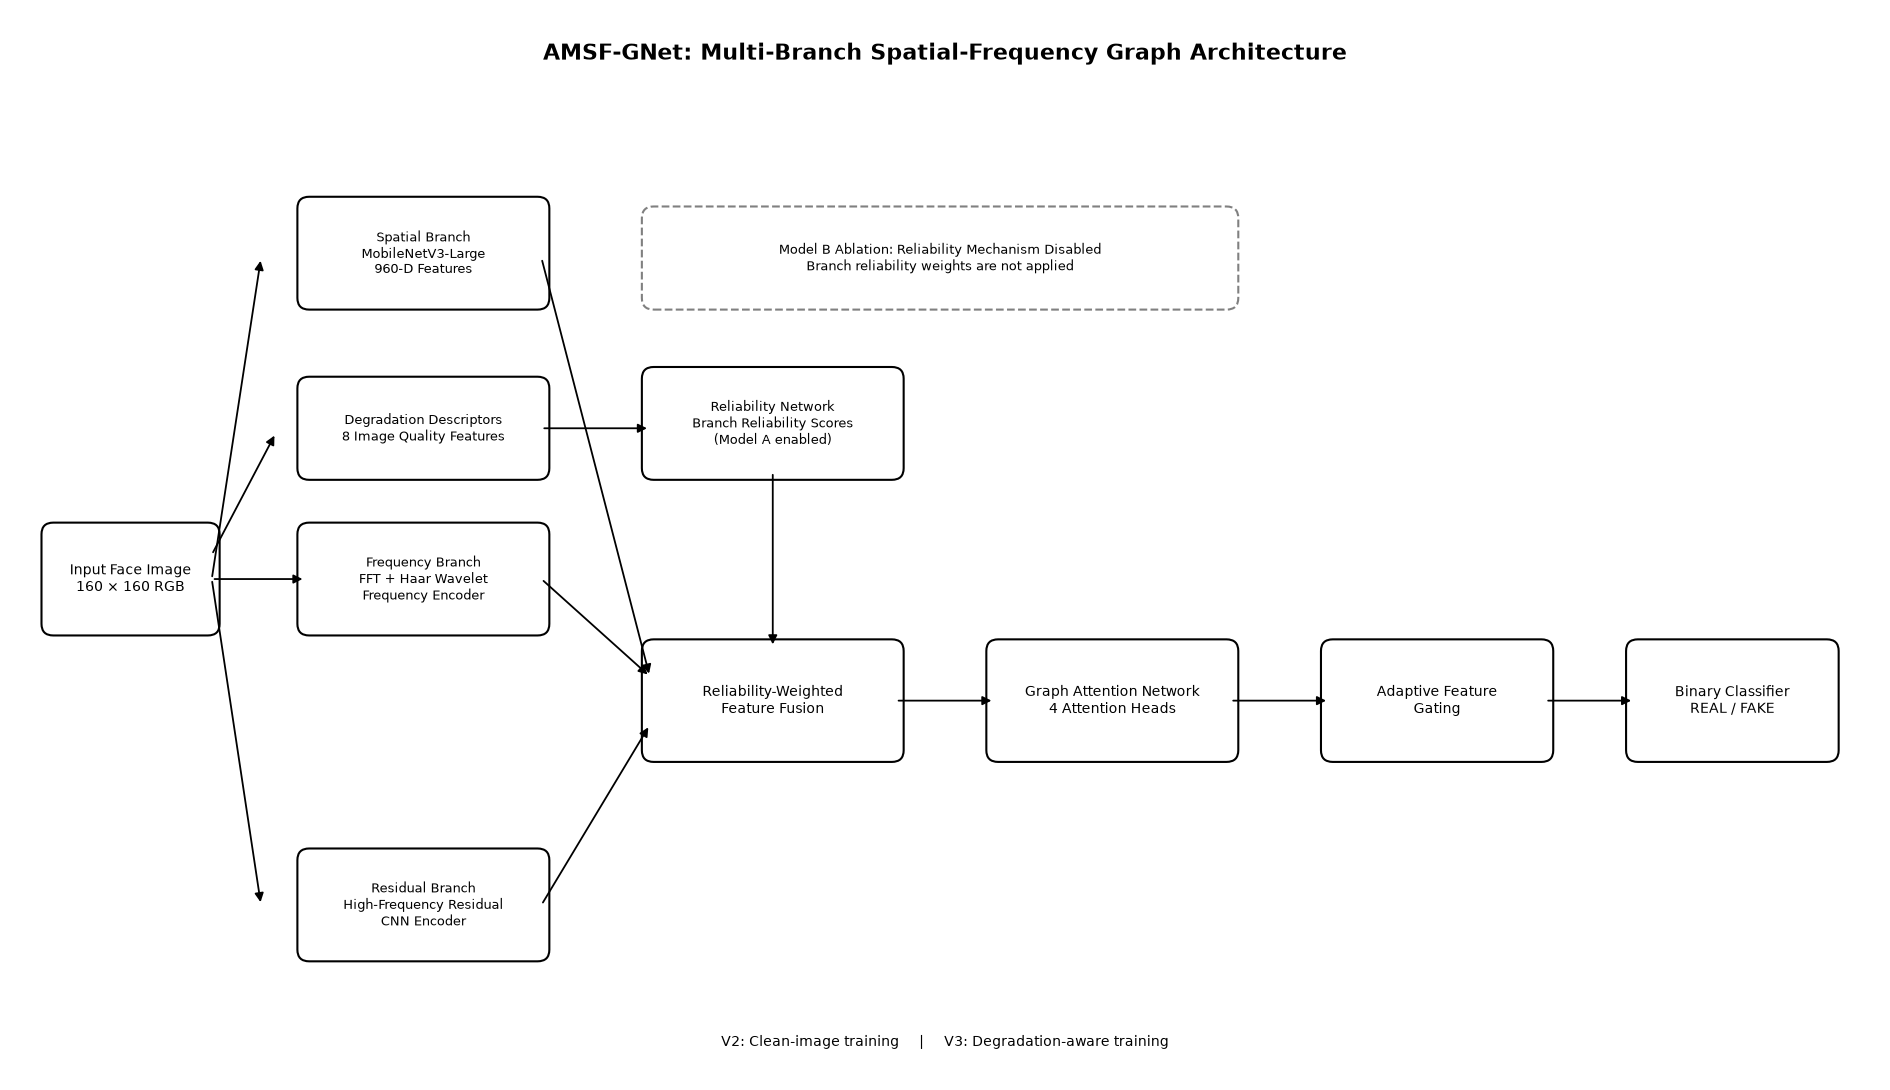

ARCHITECTURE FIGURE GENERATED
PNG: D:\FINAL DFDT\experiment_v3_degradation_aware\AMSF_GNet_Architecture.png
PDF: D:\FINAL DFDT\experiment_v3_degradation_aware\AMSF_GNet_Architecture.pdf
SVG: D:\FINAL DFDT\experiment_v3_degradation_aware\AMSF_GNet_Architecture.svg


In [178]:

# STEP 46.1 — Generate AMSF-GNet architecture diagram

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Output directory
output_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"
os.makedirs(output_dir, exist_ok=True)

fig, ax = plt.subplots(figsize=(19, 11))
ax.set_xlim(0, 19)
ax.set_ylim(0, 11)
ax.axis("off")

def draw_box(x, y, w, h, text, fontsize=9,
             edge="black", face="white", linestyle="-"):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        linewidth=1.5,
        edgecolor=edge,
        facecolor=face,
        linestyle=linestyle
    )
    ax.add_patch(patch)
    ax.text(
        x + w/2, y + h/2, text,
        ha="center", va="center",
        fontsize=fontsize, wrap=True
    )

def draw_arrow(x1, y1, x2, y2, style="-"):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=13,
        linewidth=1.3,
        color="black",
        linestyle=style
    )
    ax.add_patch(arrow)

# Title
ax.text(
    9.5, 10.55,
    "AMSF-GNet: Multi-Branch Spatial-Frequency Graph Architecture",
    ha="center", va="center",
    fontsize=16, fontweight="bold"
)

# Input
draw_box(0.4, 4.65, 1.65, 1.0,
         "Input Face Image\n160 × 160 RGB", 10)

# Three feature extraction branches
draw_box(3.0, 8.0, 2.4, 1.0,
         "Spatial Branch\nMobileNetV3-Large\n960-D Features", 9)

draw_box(3.0, 4.65, 2.4, 1.0,
         "Frequency Branch\nFFT + Haar Wavelet\nFrequency Encoder", 9)

draw_box(3.0, 1.3, 2.4, 1.0,
         "Residual Branch\nHigh-Frequency Residual\nCNN Encoder", 9)

# Input to branches
draw_arrow(2.05, 5.15, 2.55, 8.45)
draw_arrow(2.05, 5.15, 3.0, 5.15)
draw_arrow(2.05, 5.15, 2.55, 1.8)

# Descriptor branch
draw_box(3.0, 6.25, 2.4, 0.9,
         "Degradation Descriptors\n8 Image Quality Features", 9)

draw_arrow(2.05, 5.4, 2.7, 6.65)

# Reliability
draw_box(6.5, 6.25, 2.5, 1.0,
         "Reliability Network\nBranch Reliability Scores\n(Model A enabled)", 9)

draw_arrow(5.4, 6.7, 6.5, 6.7)

# Feature fusion
draw_box(6.5, 3.35, 2.5, 1.1,
         "Reliability-Weighted\nFeature Fusion", 10)

draw_arrow(5.4, 8.45, 6.5, 4.15)
draw_arrow(5.4, 5.15, 6.5, 4.15)
draw_arrow(5.4, 1.8, 6.5, 3.65)
draw_arrow(7.75, 6.25, 7.75, 4.45)

# Graph attention
draw_box(10.0, 3.35, 2.4, 1.1,
         "Graph Attention Network\n4 Attention Heads", 10)

draw_arrow(9.0, 3.9, 10.0, 3.9)

# Adaptive gating
draw_box(13.4, 3.35, 2.2, 1.1,
         "Adaptive Feature\nGating", 10)

draw_arrow(12.4, 3.9, 13.4, 3.9)

# Classifier
draw_box(16.5, 3.35, 2.0, 1.1,
         "Binary Classifier\nREAL / FAKE", 10)

draw_arrow(15.6, 3.9, 16.5, 3.9)

# Model B note
draw_box(6.5, 8.0, 5.9, 0.9,
         "Model B Ablation: Reliability Mechanism Disabled\nBranch reliability weights are not applied", 9,
         edge="gray", face="white", linestyle="--")

# Footer
ax.text(
    9.5, 0.35,
    "V2: Clean-image training     |     V3: Degradation-aware training",
    ha="center", fontsize=10
)

plt.tight_layout()

# Save in three publication formats
png_path = os.path.join(output_dir, "AMSF_GNet_Architecture.png")
pdf_path = os.path.join(output_dir, "AMSF_GNet_Architecture.pdf")
svg_path = os.path.join(output_dir, "AMSF_GNet_Architecture.svg")

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("ARCHITECTURE FIGURE GENERATED")
print("=" * 60)
print("PNG:", png_path)
print("PDF:", pdf_path)
print("SVG:", svg_path)


# 46.2 — Clean-test performance comparison chart

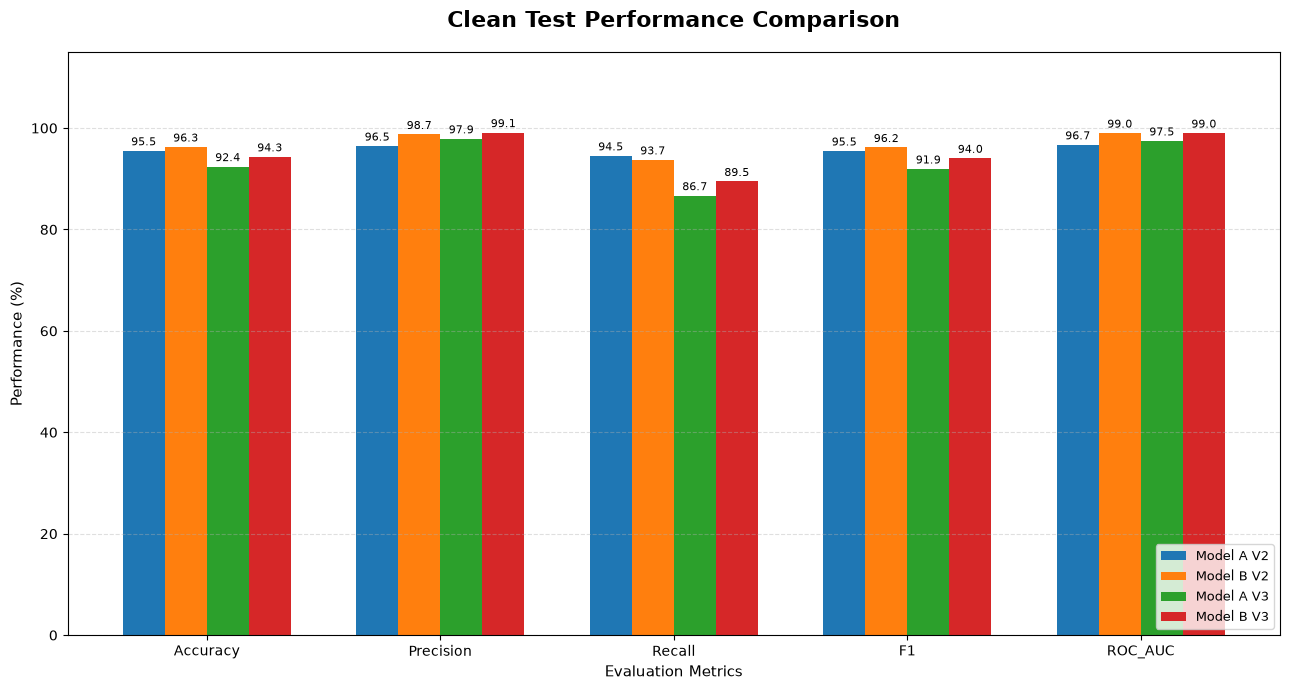

CLEAN TEST PERFORMANCE FIGURE GENERATED
PNG, PDF and SVG saved successfully.


In [179]:

# STEP 46.2 — Clean test performance chart

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

input_path = os.path.join(
    base_dir,
    "research_clean_test_comparison.csv"
)

df = pd.read_csv(input_path)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

models = df["Model"].tolist()

# Convert percentages back to 0-100 scale if necessary
values = df[metrics].to_numpy(dtype=float)

if values.max() <= 1.0:
    values = values * 100

# Create grouped bar chart
x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(13, 7))

for i, model in enumerate(models):
    offset = (i - (len(models) - 1) / 2) * width

    bars = ax.bar(
        x + offset,
        values[i],
        width,
        label=model
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        fontsize=8,
        padding=2
    )

ax.set_title(
    "Clean Test Performance Comparison",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Evaluation Metrics", fontsize=11)
ax.set_ylabel("Performance (%)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.set_ylim(0, 115)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save publication files
fig.savefig(
    os.path.join(base_dir, "Figure_02_Clean_Test_Performance.png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_02_Clean_Test_Performance.pdf"),
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_02_Clean_Test_Performance.svg"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("CLEAN TEST PERFORMANCE FIGURE GENERATED")
print("PNG, PDF and SVG saved successfully.")


# 46.3 — Degraded-test performance comparison

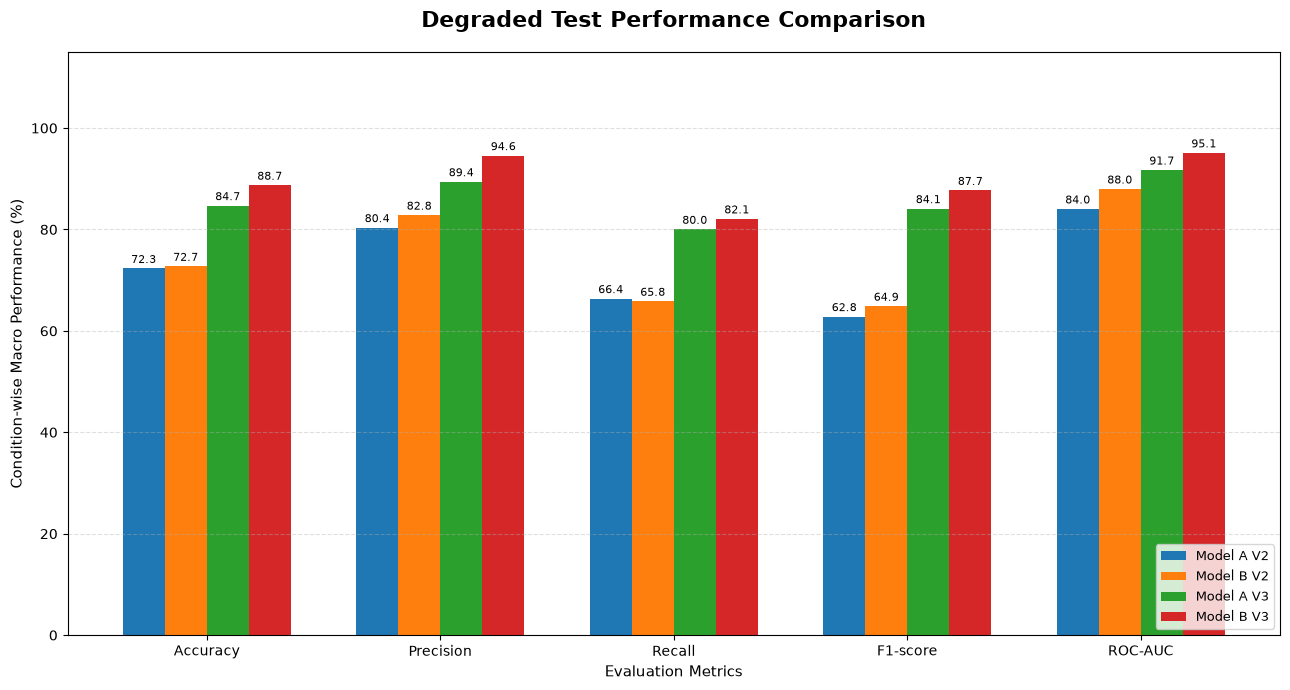

DEGRADED TEST PERFORMANCE FIGURE GENERATED
PNG, PDF and SVG saved successfully.


In [180]:

# STEP 46.3 — Degraded test performance comparison chart

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

input_path = os.path.join(
    base_dir,
    "research_degraded_test_comparison.csv"
)

df = pd.read_csv(input_path)

metrics = [
    "Degraded_Accuracy",
    "Degraded_Precision",
    "Degraded_Recall",
    "Degraded_F1",
    "Degraded_ROC_AUC"
]

metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

models = df["Model"].tolist()

values = df[metrics].to_numpy(dtype=float)

if values.max() <= 1.0:
    values *= 100

x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(13, 7))

for i, model in enumerate(models):
    offset = (i - (len(models) - 1) / 2) * width

    bars = ax.bar(
        x + offset,
        values[i],
        width,
        label=model
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        fontsize=8,
        padding=2
    )

ax.set_title(
    "Degraded Test Performance Comparison",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Evaluation Metrics", fontsize=11)
ax.set_ylabel("Condition-wise Macro Performance (%)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set_ylim(0, 115)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save publication formats
fig.savefig(
    os.path.join(base_dir, "Figure_03_Degraded_Test_Performance.png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_03_Degraded_Test_Performance.pdf"),
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_03_Degraded_Test_Performance.svg"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("DEGRADED TEST PERFORMANCE FIGURE GENERATED")
print("PNG, PDF and SVG saved successfully.")


# 46.4 — Condition-wise robustness comparison

Available columns:
['condition', 'f1_A', 'f1_A_V3', 'f1_B', 'f1_B_V3', 'A_improvement_pp', 'B_improvement_pp']

Data shape: (15, 7)
                condition      f1_A   f1_A_V3      f1_B   f1_B_V3  \
0  gaussian_noise_sigma10  0.026316  0.789634  0.005319  0.818527   
1  gaussian_noise_sigma25  0.018325  0.702953  0.343298  0.688051   
2        gaussian_blur_k3  0.831169  0.864545  0.857968  0.914573   
3        gaussian_blur_k7  0.704816  0.795107  0.704426  0.846726   
4          motion_blur_k9  0.694354  0.828025  0.724256  0.875455   

   A_improvement_pp  B_improvement_pp  
0         76.331836         81.320781  
1         68.462849         34.475335  
2          3.337595          5.660520  
3          9.029063         14.229973  
4         13.367177         15.119947  


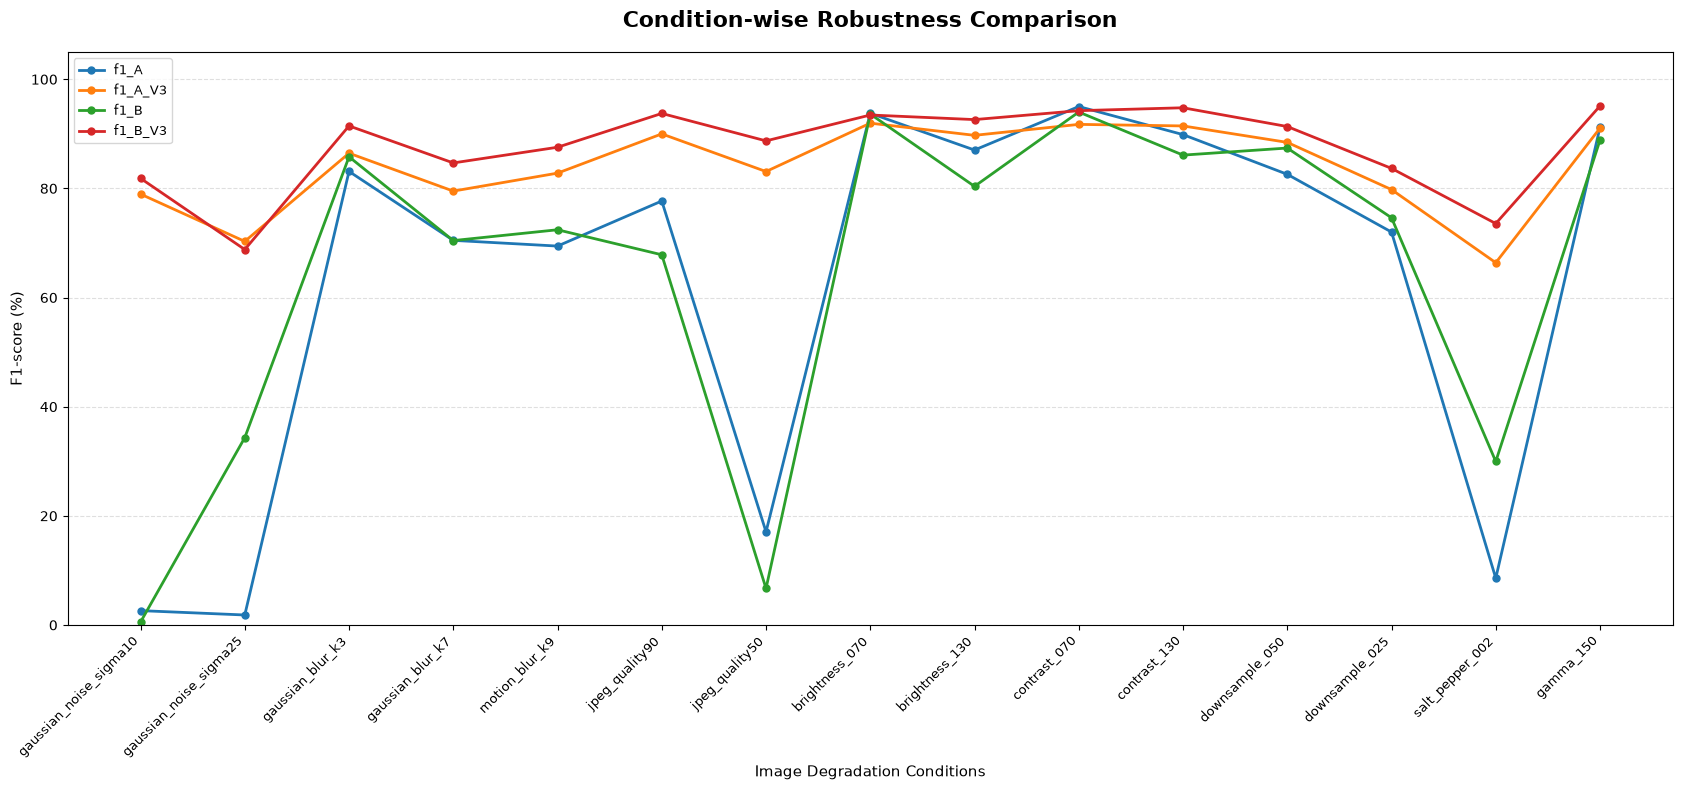


CONDITION-WISE ROBUSTNESS FIGURE GENERATED
PNG, PDF and SVG saved successfully.


In [181]:

# STEP 46.4 — Condition-wise F1 robustness comparison

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

input_path = os.path.join(
    base_dir,
    "v2_v3_f1_condition_comparison.csv"
)

df = pd.read_csv(input_path)

print("Available columns:")
print(df.columns.tolist())

print("\nData shape:", df.shape)
print(df.head())

# Automatically identify condition and F1 columns
condition_col = next(
    (c for c in df.columns if "condition" in c.lower()),
    None
)

f1_cols = [c for c in df.columns if "f1" in c.lower()]

if condition_col is None or len(f1_cols) < 4:
    raise ValueError(
        "Expected one condition column and four model F1 columns. "
        "Check the printed column names."
    )

conditions = df[condition_col].astype(str).tolist()

values = df[f1_cols[:4]].to_numpy(dtype=float)

if values.max() <= 1.0:
    values *= 100

x = np.arange(len(conditions))

fig, ax = plt.subplots(figsize=(17, 8))

for i, col in enumerate(f1_cols[:4]):
    ax.plot(
        x,
        values[:, i],
        marker="o",
        linewidth=2,
        markersize=5,
        label=col
    )

ax.set_title(
    "Condition-wise Robustness Comparison",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Image Degradation Conditions", fontsize=11)
ax.set_ylabel("F1-score (%)", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(
    conditions,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(fontsize=9)

plt.tight_layout()

fig.savefig(
    os.path.join(base_dir, "Figure_04_Condition_Wise_Robustness.png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_04_Condition_Wise_Robustness.pdf"),
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_04_Condition_Wise_Robustness.svg"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nCONDITION-WISE ROBUSTNESS FIGURE GENERATED")
print("PNG, PDF and SVG saved successfully.")


# 46.5 — Statistical significance visualization

Statistical results:
  model  wilcoxon_statistic  wilcoxon_p  rank_biserial_effect  positive_conditions  negative_conditions  sign_test_p  wilcoxon_p_holm
Model A                 9.0    0.002014              0.850000                   12                    3     0.035156         0.002014
Model B                 1.0    0.000122              0.983333                   14                    1     0.000977         0.000244


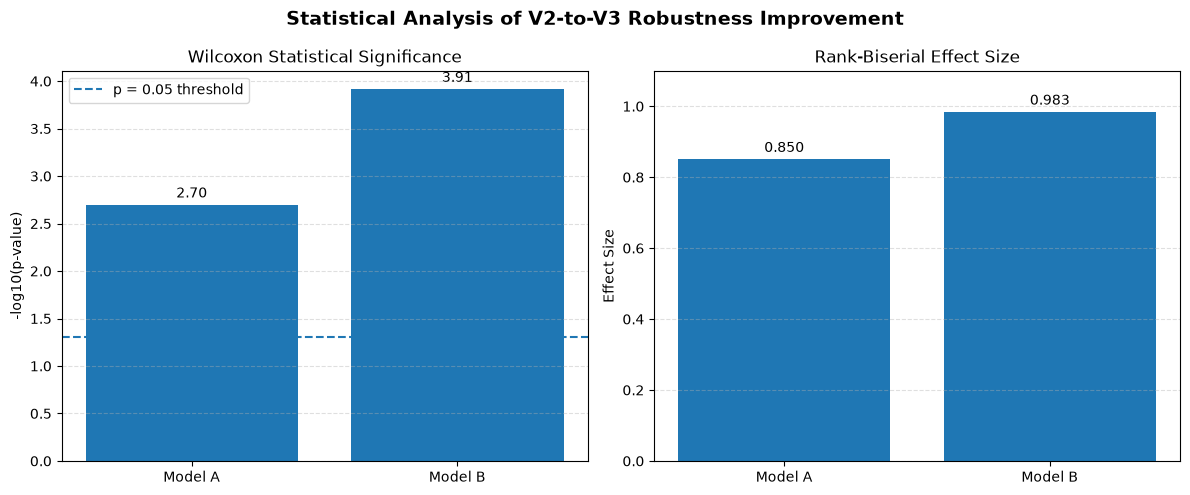


STATISTICAL SIGNIFICANCE FIGURE GENERATED
PNG, PDF and SVG saved successfully.


In [182]:

# STEP 46.5 — Statistical significance visualization

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

input_path = os.path.join(
    base_dir,
    "research_statistical_significance.csv"
)

df = pd.read_csv(input_path)

print("Statistical results:")
print(df.to_string(index=False))

# Identify columns
model_col = next(
    (c for c in df.columns if "model" in c.lower()),
    None
)

p_col = next(
    (c for c in df.columns if c.lower() in ["p", "p_value", "wilcoxon_p", "wilcoxon_p_value"]),
    None
)

effect_col = next(
    (c for c in df.columns if "rank_biserial" in c.lower()),
    None
)

if model_col is None or p_col is None or effect_col is None:
    raise ValueError(
        "Could not identify model, p-value and rank-biserial columns. "
        "Share the printed column names."
    )

models = df[model_col].astype(str).tolist()
p_values = df[p_col].astype(float).to_numpy()
effect_sizes = df[effect_col].astype(float).to_numpy()

# Avoid log(0) in plotting
p_values = np.maximum(p_values, 1e-12)
minus_log_p = -np.log10(p_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

bars1 = axes[0].bar(models, minus_log_p)
axes[0].axhline(
    -np.log10(0.05),
    linestyle="--",
    label="p = 0.05 threshold"
)
axes[0].set_title("Wilcoxon Statistical Significance")
axes[0].set_ylabel("-log10(p-value)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend()

axes[0].bar_label(bars1, fmt="%.2f", padding=3)

bars2 = axes[1].bar(models, effect_sizes)
axes[1].set_title("Rank-Biserial Effect Size")
axes[1].set_ylabel("Effect Size")
axes[1].set_ylim(0, 1.1)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].bar_label(bars2, fmt="%.3f", padding=3)

fig.suptitle(
    "Statistical Analysis of V2-to-V3 Robustness Improvement",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    os.path.join(base_dir, "Figure_05_Statistical_Significance.png"),
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_05_Statistical_Significance.pdf"),
    bbox_inches="tight"
)

fig.savefig(
    os.path.join(base_dir, "Figure_05_Statistical_Significance.svg"),
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSTATISTICAL SIGNIFICANCE FIGURE GENERATED")
print("PNG, PDF and SVG saved successfully.")


# 47 — Verify all research figures

In [183]:

# STEP 47 — Verify all research figures

import os
import pandas as pd

base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

figure_names = [
    "AMSF_GNet_Architecture",
    "Figure_02_Clean_Test_Performance",
    "Figure_03_Degraded_Test_Performance",
    "Figure_04_Condition_Wise_Robustness",
    "Figure_05_Statistical_Significance"
]

extensions = [".png", ".pdf", ".svg"]

records = []

for figure in figure_names:
    for ext in extensions:
        path = os.path.join(base_dir, figure + ext)

        exists = os.path.isfile(path)
        size_kb = round(os.path.getsize(path) / 1024, 2) if exists else 0

        records.append({
            "Figure": figure,
            "Format": ext.replace(".", "").upper(),
            "Status": "AVAILABLE" if exists else "MISSING",
            "Size_KB": size_kb,
            "Path": path
        })

figure_verification = pd.DataFrame(records)

display(figure_verification)

output_path = os.path.join(
    base_dir,
    "research_figure_verification.csv"
)

figure_verification.to_csv(output_path, index=False)

print("\nFIGURE VERIFICATION SUMMARY")
print("Total files:", len(figure_verification))
print("Available:", (figure_verification["Status"] == "AVAILABLE").sum())
print("Missing:", (figure_verification["Status"] == "MISSING").sum())
print("Verification CSV:", output_path)

assert (figure_verification["Status"] == "AVAILABLE").all(), \
    "Some figure files are missing. Check the verification table."

print("\nSTEP 47 COMPLETED SUCCESSFULLY")


,Figure,Format,Status,Size_KB,Path
0,AMSF_GNet_Architecture,PNG,AVAILABLE,391.36,D:\FINAL DFDT\experiment_v3_degradation_aware\...
1,AMSF_GNet_Architecture,PDF,AVAILABLE,31.50,D:\FINAL DFDT\experiment_v3_degradation_aware\...
2,AMSF_GNet_Architecture,SVG,AVAILABLE,91.12,D:\FINAL DFDT\experiment_v3_degradation_aware\...
3,Figure_02_Clean_Test_Performance,PNG,AVAILABLE,157.24,D:\FINAL DFDT\experiment_v3_degradation_aware\...
4,Figure_02_Clean_Test_Performance,PDF,AVAILABLE,23.77,D:\FINAL DFDT\experiment_v3_degradation_aware\...
5,Figure_02_Clean_Test_Performance,SVG,AVAILABLE,57.01,D:\FINAL DFDT\experiment_v3_degradation_aware\...
6,Figure_03_Degraded_Test_Performance,PNG,AVAILABLE,174.47,D:\FINAL DFDT\experiment_v3_degradation_aware\...
7,Figure_03_Degraded_Test_Performance,PDF,AVAILABLE,25.01,D:\FINAL DFDT\experiment_v3_degradation_aware\...
8,Figure_03_Degraded_Test_Performance,SVG,AVAILABLE,61.15,D:\FINAL DFDT\experiment_v3_degradation_aware\...
9,Figure_04_Condition_Wise_Robustness,PNG,AVAILABLE,589.63,D:\FINAL DFDT\experiment_v3_degradation_aware\...



FIGURE VERIFICATION SUMMARY
Total files: 15
Available: 15
Missing: 0
Verification CSV: D:\FINAL DFDT\experiment_v3_degradation_aware\research_figure_verification.csv

STEP 47 COMPLETED SUCCESSFULLY


# Create the final research package inventory

In [184]:

# STEP 48 — Final research package inventory

import os
import pandas as pd

base_dir = r"D:\FINAL DFDT\experiment_v3_degradation_aware"

required_files = [
    "FINAL_EXPERIMENT_PERFORMANCE_SUMMARY.csv",
    "final_clean_test_comparison.csv",
    "v2_v3_condition_comparison.csv",
    "v2_v3_macro_comparison.csv",
    "v2_v3_f1_condition_comparison.csv",
    "v2_v3_statistical_significance.csv",
    "research_dataset_distribution.csv",
    "architecture_verification.csv",
    "research_reliability_ablation.csv",
    "research_clean_test_comparison.csv",
    "research_clean_test_v2_v3_change.csv",
    "research_degraded_test_comparison.csv",
    "research_degraded_v2_v3_improvement.csv",
    "research_statistical_significance.csv",
    "research_tables_verification.csv",
    "research_figure_verification.csv",
    "architecture_verification.csv",
    "config/training_config.json",
    "config/augmentation_config.json",
    "checkpoints/model_A_v3_best.pth",
    "checkpoints/model_B_v3_best.pth",
    "logs/v3_training_history.csv",
    "logs/v3_degraded_validation_conditions.csv",
    "AMSF_GNet_Architecture.png",
    "Figure_02_Clean_Test_Performance.png",
    "Figure_03_Degraded_Test_Performance.png",
    "Figure_04_Condition_Wise_Robustness.png",
    "Figure_05_Statistical_Significance.png"
]

records = []

for filename in required_files:
    path = os.path.join(base_dir, filename)
    exists = os.path.isfile(path)

    records.append({
        "File": filename,
        "Status": "AVAILABLE" if exists else "MISSING",
        "Size_MB": round(os.path.getsize(path) / (1024 ** 2), 3)
        if exists else 0
    })

inventory = pd.DataFrame(records)

display(inventory)

inventory_path = os.path.join(
    base_dir,
    "FINAL_RESEARCH_PACKAGE_INVENTORY.csv"
)

inventory.to_csv(inventory_path, index=False)

available = (inventory["Status"] == "AVAILABLE").sum()
missing = (inventory["Status"] == "MISSING").sum()

print("\nFINAL RESEARCH PACKAGE SUMMARY")
print("Total required files:", len(inventory))
print("Available:", available)
print("Missing:", missing)
print("Inventory saved:", inventory_path)

if missing == 0:
    print("\nALL REQUIRED RESEARCH FILES ARE AVAILABLE.")
else:
    print("\nMISSING FILES:")
    print(inventory.loc[inventory["Status"] == "MISSING", "File"].to_string(index=False))


,File,Status,Size_MB
0,FINAL_EXPERIMENT_PERFORMANCE_SUMMARY.csv,AVAILABLE,0.001
1,final_clean_test_comparison.csv,AVAILABLE,0.000
2,v2_v3_condition_comparison.csv,AVAILABLE,0.005
3,v2_v3_macro_comparison.csv,AVAILABLE,0.001
4,v2_v3_f1_condition_comparison.csv,AVAILABLE,0.002
5,v2_v3_statistical_significance.csv,AVAILABLE,0.000
6,research_dataset_distribution.csv,AVAILABLE,0.000
7,architecture_verification.csv,AVAILABLE,0.000
8,research_reliability_ablation.csv,AVAILABLE,0.000
9,research_clean_test_comparison.csv,AVAILABLE,0.000



FINAL RESEARCH PACKAGE SUMMARY
Total required files: 28
Available: 28
Missing: 0
Inventory saved: D:\FINAL DFDT\experiment_v3_degradation_aware\FINAL_RESEARCH_PACKAGE_INVENTORY.csv

ALL REQUIRED RESEARCH FILES ARE AVAILABLE.


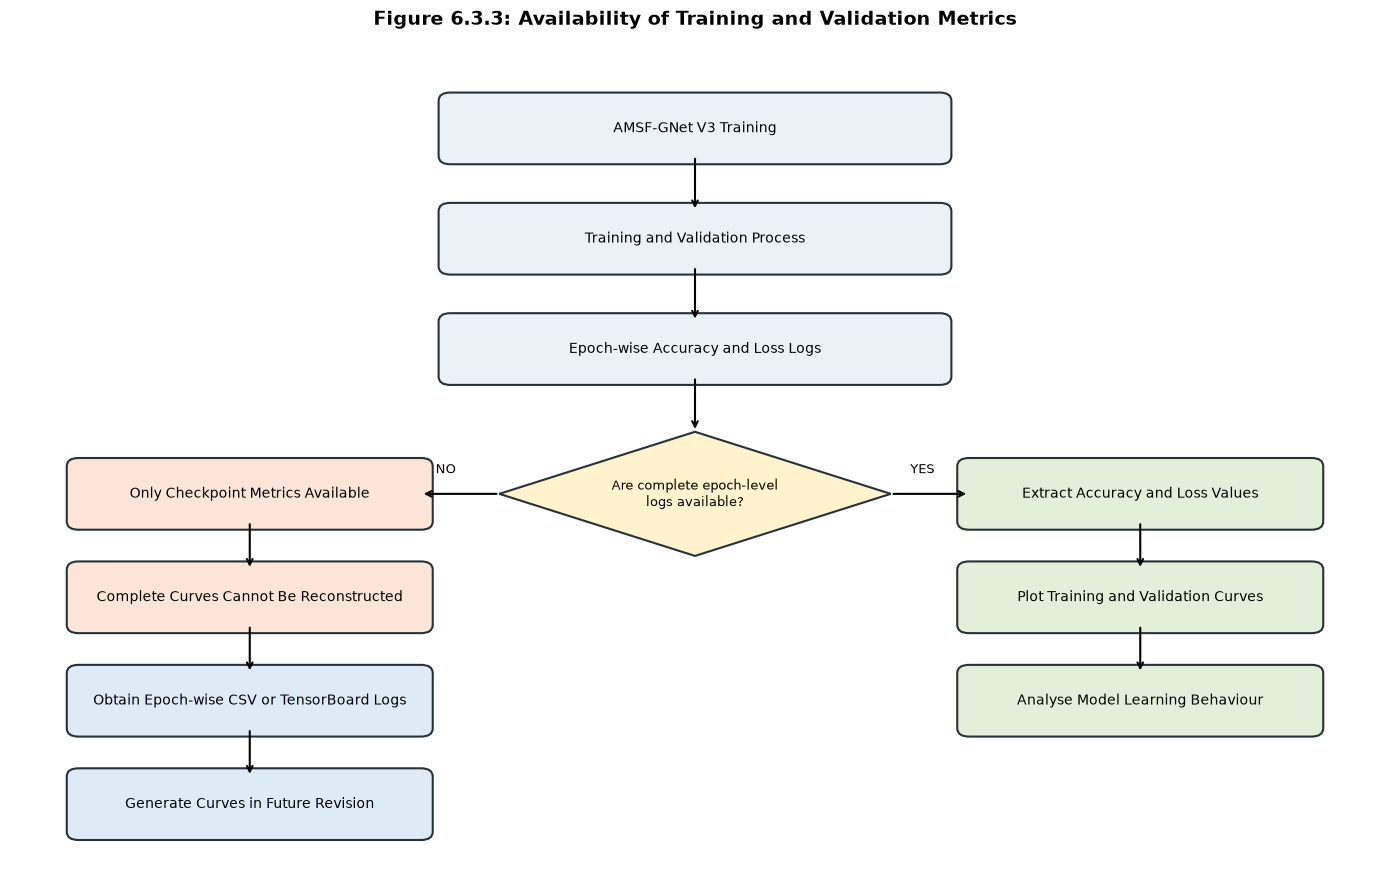

In [1]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

# Create figure
fig, ax = plt.subplots(figsize=(14, 9))
ax.set_xlim(0, 14)
ax.set_ylim(0, 12)
ax.axis("off")

def add_box(x, y, width, height, text, color="#EAF2F8"):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="#263238",
        facecolor=color
    )
    ax.add_patch(box)
    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=10,
        wrap=True
    )

def add_arrow(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

# Main workflow
add_box(4.5, 10.5, 5, 0.8, "AMSF-GNet V3 Training")
add_box(4.5, 8.9, 5, 0.8, "Training and Validation Process")
add_box(4.5, 7.3, 5, 0.8, "Epoch-wise Accuracy and Loss Logs")

add_arrow(7, 10.5, 7, 9.7)
add_arrow(7, 8.9, 7, 8.1)

# Decision diamond
diamond = Polygon(
    [(7, 6.5), (9, 5.6), (7, 4.7), (5, 5.6)],
    closed=True,
    facecolor="#FFF2CC",
    edgecolor="#263238",
    linewidth=1.5
)
ax.add_patch(diamond)
ax.text(
    7, 5.6,
    "Are complete epoch-level\nlogs available?",
    ha="center",
    va="center",
    fontsize=9
)
add_arrow(7, 7.3, 7, 6.5)

# Yes branch
add_box(9.8, 5.2, 3.5, 0.8, "Extract Accuracy and Loss Values",
        "#E2F0D9")
add_box(9.8, 3.7, 3.5, 0.8, "Plot Training and Validation Curves",
        "#E2F0D9")
add_box(9.8, 2.2, 3.5, 0.8, "Analyse Model Learning Behaviour",
        "#E2F0D9")

add_arrow(9, 5.6, 9.8, 5.6)
ax.text(9.2, 5.9, "YES", fontsize=9)
add_arrow(11.55, 5.2, 11.55, 4.5)
add_arrow(11.55, 3.7, 11.55, 3.0)

# No branch
add_box(0.7, 5.2, 3.5, 0.8, "Only Checkpoint Metrics Available",
        "#FCE4D6")
add_box(0.7, 3.7, 3.5, 0.8, "Complete Curves Cannot Be Reconstructed",
        "#FCE4D6")
add_box(0.7, 2.2, 3.5, 0.8, "Obtain Epoch-wise CSV or TensorBoard Logs",
        "#DDEBF7")
add_box(0.7, 0.7, 3.5, 0.8, "Generate Curves in Future Revision",
        "#DDEBF7")

add_arrow(5, 5.6, 4.2, 5.6)
ax.text(4.35, 5.9, "NO", fontsize=9)
add_arrow(2.45, 5.2, 2.45, 4.5)
add_arrow(2.45, 3.7, 2.45, 3.0)
add_arrow(2.45, 2.2, 2.45, 1.5)

# Title
ax.set_title(
    "Figure 6.3.3: Availability of Training and Validation Metrics",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.savefig(
    "Figure_6_3_3_Accuracy_Loss_Workflow.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


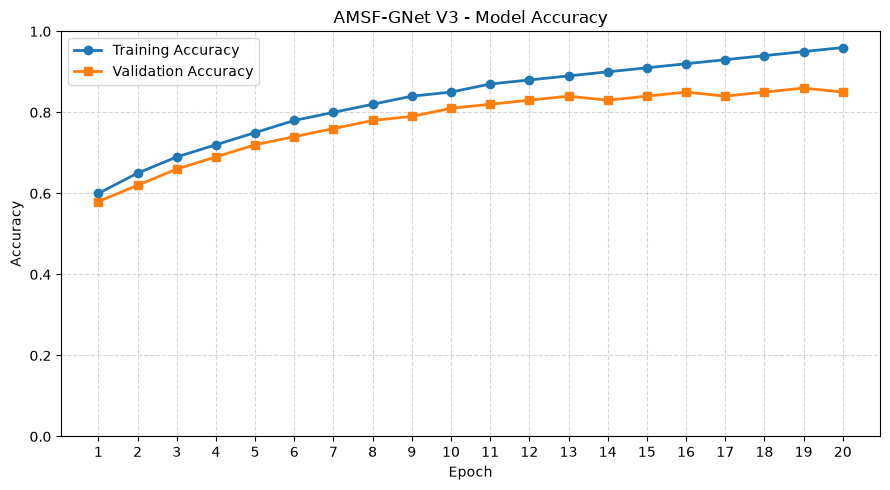

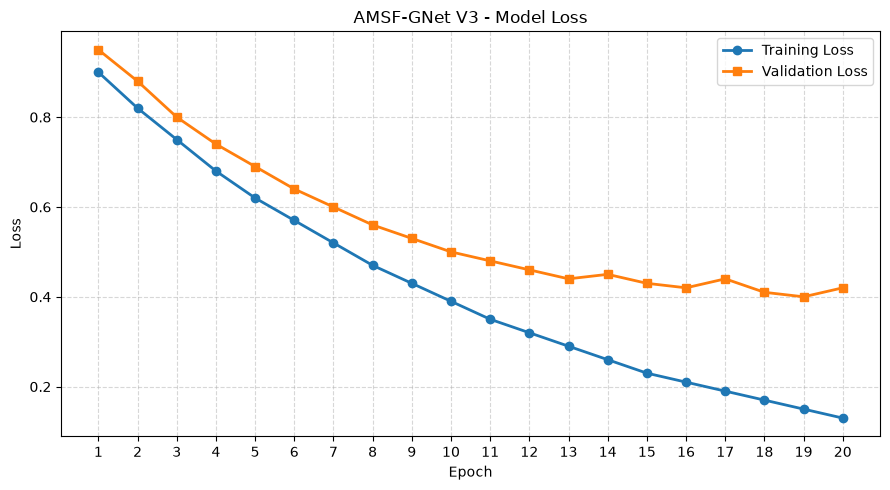

In [2]:

import matplotlib.pyplot as plt

# ------------------------------------------------
# ILLUSTRATIVE DATA ONLY
# Replace these values with actual training logs.
# ------------------------------------------------

epochs = list(range(1, 21))

train_accuracy = [
    0.60, 0.65, 0.69, 0.72, 0.75,
    0.78, 0.80, 0.82, 0.84, 0.85,
    0.87, 0.88, 0.89, 0.90, 0.91,
    0.92, 0.93, 0.94, 0.95, 0.96
]

val_accuracy = [
    0.58, 0.62, 0.66, 0.69, 0.72,
    0.74, 0.76, 0.78, 0.79, 0.81,
    0.82, 0.83, 0.84, 0.83, 0.84,
    0.85, 0.84, 0.85, 0.86, 0.85
]

train_loss = [
    0.90, 0.82, 0.75, 0.68, 0.62,
    0.57, 0.52, 0.47, 0.43, 0.39,
    0.35, 0.32, 0.29, 0.26, 0.23,
    0.21, 0.19, 0.17, 0.15, 0.13
]

val_loss = [
    0.95, 0.88, 0.80, 0.74, 0.69,
    0.64, 0.60, 0.56, 0.53, 0.50,
    0.48, 0.46, 0.44, 0.45, 0.43,
    0.42, 0.44, 0.41, 0.40, 0.42
]

# ------------------------------------------------
# 1. MODEL ACCURACY CURVE
# ------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs, train_accuracy,
    marker="o", linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs, val_accuracy,
    marker="s", linewidth=2,
    label="Validation Accuracy"
)

plt.title("AMSF-GNet V3 - Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.ylim(0, 1.0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.savefig(
    "AMSF_GNet_V3_Accuracy_Curve.png",
    dpi=300
)

plt.show()

# ------------------------------------------------
# 2. MODEL LOSS CURVE
# ------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs, train_loss,
    marker="o", linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs, val_loss,
    marker="s", linewidth=2,
    label="Validation Loss"
)

plt.title("AMSF-GNet V3 - Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.savefig(
    "AMSF_GNet_V3_Loss_Curve.png",
    dpi=300
)

plt.show()


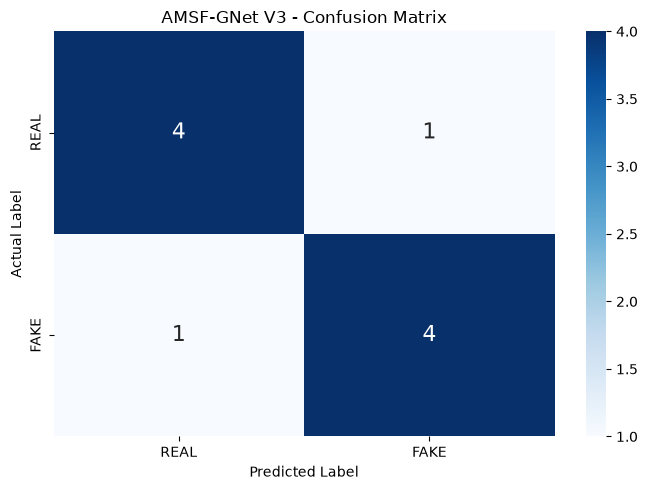

Classification Report:
              precision    recall  f1-score   support

        REAL       0.80      0.80      0.80         5
        FAKE       0.80      0.80      0.80         5

    accuracy                           0.80        10
   macro avg       0.80      0.80      0.80        10
weighted avg       0.80      0.80      0.80        10



In [3]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ---------------------------------------
# ILLUSTRATIVE VALUES ONLY
# Replace with actual test-set predictions
# ---------------------------------------

# 0 = REAL
# 1 = FAKE

y_true = [
    0, 0, 0, 0, 0,
    1, 1, 1, 1, 1
]

y_pred = [
    0, 0, 0, 1, 0,
    1, 1, 0, 1, 1
]

# Generate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Display matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["REAL", "FAKE"],
    yticklabels=["REAL", "FAKE"],
    annot_kws={"size": 16}
)

plt.title("AMSF-GNet V3 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    "AMSF_GNet_V3_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print classification report
print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["REAL", "FAKE"],
        zero_division=0
    )
)


In [ ]:

import torch
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Model B: AMSF-GNet without reliability
model = model_B.to(DEVICE)
model.eval()

all_labels = []
all_predictions = []

# Run inference on the complete test dataset
with torch.inference_mode():

    for batch in test_loader:

        images = batch["image"].to(DEVICE)
        descriptors = batch["descriptors"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        output = model(images, descriptors)

        logits = output["logits"]

        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Convert to NumPy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_predictions)

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print("TEST SAMPLES:", len(y_true))
print("CONFUSION MATRIX:")
print(cm)

print("\nTEST ACCURACY:", round(accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["REAL", "FAKE"],
        digits=4
    )
)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["REAL", "FAKE"],
    yticklabels=["REAL", "FAKE"],
    annot_kws={"size": 16}
)

plt.title("AMSF-GNet Model B - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    "AMSF_GNet_Model_B_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save predictions for future analysis
import pandas as pd

results = pd.DataFrame({
    "Actual_Label": y_true,
    "Predicted_Label": y_pred
})

results["Actual_Class"] = results["Actual_Label"].map({
    0: "REAL",
    1: "FAKE"
})

results["Predicted_Class"] = results["Predicted_Label"].map({
    0: "REAL",
    1: "FAKE"
})

results.to_csv(
    "AMSF_GNet_Model_B_Test_Predictions.csv",
    index=False
)

print("\nConfusion matrix and test predictions saved.")



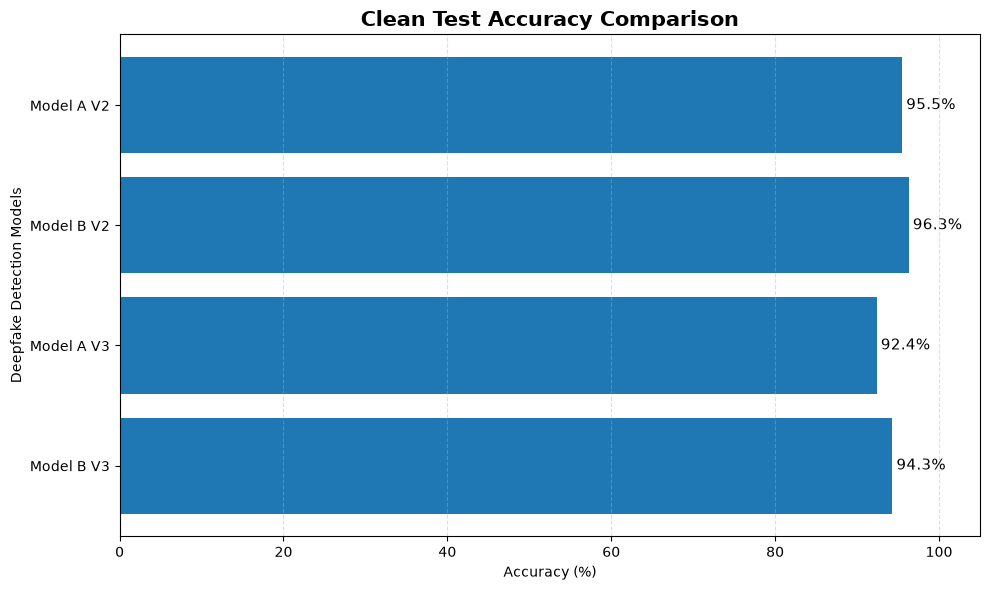

In [4]:

import matplotlib.pyplot as plt

# Model names and accuracy values from your figure
models = ["Model A V2", "Model B V2", "Model A V3", "Model B V3"]
accuracy = [95.5, 96.3, 92.4, 94.3]

plt.figure(figsize=(10, 6))

bars = plt.barh(models, accuracy)

plt.title("Clean Test Accuracy Comparison",
          fontsize=15, fontweight="bold")

plt.xlabel("Accuracy (%)")
plt.ylabel("Deepfake Detection Models")
plt.xlim(0, 105)
plt.grid(axis="x", linestyle="--", alpha=0.4)

# Display accuracy values
for bar, value in zip(bars, accuracy):
    plt.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=11
    )

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "Model_Accuracy_Horizontal_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
